# 19 · Table Extraction from Document Images
*AI Foundations · Notebook 19 of 19*

Reports, invoices, timetables and forms are full of tables. Once a page is scanned or
photographed, though, those tables are just a grid of gray pixels: a computer cannot
search them, sum a column or load them into a spreadsheet. **Table extraction** turns the
pixels back into structured data: where each table is, how many rows and columns it has,
which cells are merged, what text sits in each cell, and which cells are bold.

In this notebook you build such a system **from scratch** and learn to measure it honestly.
You will write a synthetic document generator that gives you unlimited pages with perfect
labels, a classical computer-vision pipeline (deskewing, contrast enhancement, binarization,
morphology, projection profiles, union–find), an OCR stage, bold detection, cross-page
stitching, and an evaluation suite built around **TEDS**, a tree-edit-distance score.

**What you will learn**
- How to specify a structured output format precisely (Extended Markdown with merge
  markers, line breaks, escaping and bold) and write a parser and validator for it.
- How to generate realistic synthetic documents with exact ground truth: merged headers,
  vertical merges, multi-line cells, bold rows, several tables per page, tables that continue
  on the next page, and scanner artifacts.
- Classical document-image processing: the Hough transform for deskewing, CLAHE, Otsu's
  threshold, and mathematical morphology for extracting ruling lines.
- Table structure recognition: table localization, projection profiles, run grouping,
  merged-cell inference with line coverage and union–find, and rectangle validation.
- OCR in practice: cropping, splitting multi-line cells into text bands, Tesseract (and how to
  batch it), an "oracle" reader that isolates structure errors from reading errors, and a tiny
  from-scratch glyph reader for numbers that shows what happens inside a classical OCR engine.
- Bold detection from stroke thickness (erosion and distance transform).
- Evaluation: tree edit distance (Zhang–Shasha), TEDS, TEDS-Struct and Bold-F1.
  experiments, ablations and stage-by-stage error analysis.
- How learned systems (detection transformers, image-to-markup models, vision–language
  models) attack the same problem, and where rule-based pipelines break.

**Prerequisites:** comfortable Python and NumPy, and the idea that a grayscale image is a 2-D
array of numbers. No deep learning is needed (we discuss it at the end).
**Estimated time:** ~5 h.

**How to use this notebook:** run cells top to bottom (Runtime → Run all works).
Exercises are marked ✏️. Each has an automatic checker and a hidden solution
(click "Solution" to expand). Quick-check questions have hidden answers.

**Contents**
1. The task: from pixels to tables
2. Extended Markdown: a precise output format
3. A synthetic document generator
4. Preprocessing: deskew, contrast, binarization
5. Ruling lines and table localization
6. Recovering the atomic grid
7. Logical cells: inferring merges
8. Reading the cells (cropping, text bands, OCR)
9. Bold detection
10. Document level: reading order and cross-page tables
11. The complete pipeline
12. Measuring quality: tree edit distance, TEDS and Bold-F1
13. Experiments: results, OCR cost, robustness, ablations, error analysis
14. Beyond rules: borderless tables and learned models
15. Quiz
16. Summary and going further

In [1]:
import importlib
import math
import platform
import random
import re
import shutil
import subprocess
import sys
import time
from collections import Counter, defaultdict
from dataclasses import dataclass, field
from pathlib import Path

import cv2
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle
from PIL import Image, ImageDraw, ImageFont

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
rng = np.random.default_rng(SEED)
cv2.setNumThreads(2)          # be gentle on small machines

plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 100, "figure.figsize": (7, 4),
    "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 11,
})
pd.set_option("display.precision", 4)
pd.set_option("display.width", 120)

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)
FONT_DIR = Path(matplotlib.get_data_path()) / "fonts" / "ttf"
FONT_REGULAR = FONT_DIR / "DejaVuSans.ttf"
FONT_BOLD = FONT_DIR / "DejaVuSans-Bold.ttf"


def ensure(pkg: str, import_name: str | None = None):
    """Import a package, installing it with pip first if it is missing."""
    name = import_name or pkg
    try:
        return importlib.import_module(name)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])
        return importlib.import_module(name)


def run_check(name, test_fn):
    """Run test_fn() and print a friendly status instead of crashing the notebook."""
    try:
        test_fn()
    except NotImplementedError:
        print(f"⏳ {name}: not implemented yet. Fill in the function and re-run this cell.")
    except AssertionError as err:
        print(f"❌ {name}: {err}")
    else:
        print(f"✅ {name}: all checks passed!")


print(f"Python {platform.python_version()} | NumPy {np.__version__} | pandas {pd.__version__} | "
      f"OpenCV {cv2.__version__} | Pillow {Image.__version__} | Matplotlib {matplotlib.__version__}")
print("Fonts found:", FONT_REGULAR.exists(), FONT_BOLD.exists())

Python 3.13.15 | NumPy 2.5.3 | pandas 2.3.3 | OpenCV 5.0.0 | Pillow 12.3.0 | Matplotlib 3.11.2
Fonts found: True True


## 1. The task: from pixels to tables

### 1.1 Two problems hiding in one

Imagine copying a printed timetable into a spreadsheet by hand. You do two different things
without noticing:

1. **Content recognition**. You *read* the words and numbers ("North", "1,250", "On track").
2. **Structure reconstruction**. You work out *where each piece of text belongs*: which row,
   which column, whether a heading stretches over several columns, whether one label is shared
   by several rows.

Optical character recognition (**OCR**) solves only the first problem. A perfect OCR engine
that reads every word correctly can still produce a useless table if it puts "1,250" in the
wrong column. In fact, structure is usually the harder half: a misread digit damages one
cell, but a missed column boundary corrupts a cell in every row.

> **Key idea.** Table extraction = *structure* (rows, columns, merges, order) **+**
> *content* (text, line breaks) **+** *formatting* (bold). We recover structure first, and
> only then read the text inside each recovered cell, so every OCR result already knows its
> place in the table.

### 1.2 Vocabulary: atomic grid vs logical cells

Draw every ruling line of a table all the way across. The lines cut the table into a grid of
small rectangles. We call this the **atomic grid** and each small rectangle a **slot**.
A **logical cell** is what a human calls a cell: one box of text. A logical cell may cover
several slots, in which case it is a **merged cell** with a **rowspan** (number of slot rows) and a
**colspan** (number of slot columns). Its top-left slot is its **anchor**.

```
 What the page shows                          The atomic grid (3 x 4 slots)
 +-------------------------------------+      +--------+--------+--------+--------+
 |       Fleet costs - March           |      | (0,0)  | (0,1)  | (0,2)  | (0,3)  |
 +---------+----------+-------+--------+      +--------+--------+--------+--------+
 | Vehicle |  Driver  | Fuel  | Notes  |      | (1,0)  | (1,1)  | (1,2)  | (1,3)  |
 +---------+----------+-------+--------+      +--------+--------+--------+--------+
 | Van 2   |  L. Ito  |  415  | tyres  |      | (2,0)  | (2,1)  | (2,2)  | (2,3)  |
 +---------+----------+-------+--------+      +--------+--------+--------+--------+

 Logical cells: "Fleet costs - March" = anchor (0,0), rowspan 1, colspan 4  (a horizontal merge)
                every other cell      = one slot (rowspan 1, colspan 1)
```

A **vertical merge** is the same idea in the other direction (one label shared by several
rows). A **multi-line cell** has text broken over several lines *inside one cell*, not to be
confused with a merge. The **header** is the block of rows at the top that names the columns,
the **body** holds the data, and many reports end with a **totals row**.

Two more document-level notions matter:

* **Reading order**: a page can hold several tables, and the output must list them in the order
  a person would read them.
* **Cross-page tables**: a long table can continue on the next page, usually *repeating its
  header rows* at the top of the new page. The output must contain **one** table, not two,
  and must not contain the repeated header twice.

### 1.3 Our version of the task

We frame a general, self-contained version of the problem (all data is generated in this
notebook):

* **Input:** a *document* = one or two grayscale page images (A4 at 150 dpi, i.e.
  $1240 \times 1754$ pixels) containing one or more tables.
* **Output:** one text string in **Extended Markdown** (Section 2) listing every table in
  reading order, with its full structure, text, line breaks and bold formatting.
* **Difficulty levels:**

| Level | Ruling lines | Layout | Merged cells | Multi-line text | Bold |
|---|---|---|---|---|---|
| L1 | full grid | one table, one page | none | none | header row and totals row |
| L2 | full grid | 1–2 tables per page, or one table continuing onto page 2 | 3-row header hierarchy, vertical merges in the body | some cells | header rows, and totals row only at the *true* end of a table |
| L3 | full grid | like L2, plus side-by-side tables | irregular headers, horizontal merges inside the body | more cells | like L2, plus occasional bold body cells |
| L4 | horizontal rules only | one table | none | none | header and totals rows |

* **Scoring** (built from scratch in Section 12): the main score is **TEDS** (Tree-Edit-
  Distance-based Similarity, in $[0, 1]$), which compares the predicted and true tables as
  trees and is sensitive to both structure and text. **Bold-F1** separately checks bold
  formatting. We combine them as $\text{Score} = 0.9\,\text{TEDS} + 0.1\,\text{Bold-F1}$,
  and a document whose output is **not valid Extended Markdown scores 0**, so a validator is
  part of the solution, not an afterthought.

### 1.4 The pipeline at a glance

```
 page images
     |
     v
 [1] deskew (Hough) -> [2] CLAHE + Otsu binarization -> [3] morphological line masks
                                                                 |
                                                                 v
 [6] read text per cell (OCR) <- [5] atomic grid + merged cells <- [4] locate tables
     |
     v
 [7] bold detection -> [8] reading order + cross-page stitching -> [9] Extended Markdown + validation
```

Every stage is simple on its own. The art is in choosing parameters that are *relative* to the
page (a kernel length "1/30 of the page width" instead of "41 pixels"), in checking every
intermediate result visually, and in measuring which stage causes which error.

**Quick check.** A system reads every word on the page perfectly but outputs a table with one
column too few. Is its TEDS score close to 1? Why?

<details><summary>Answer</summary>

No. It drops to roughly 0.7–0.8 for typical tables with 4–7 columns, while the misread word in
Section 12.3 (one wrong letter) costs only 0.0014. With a missing column boundary, two columns'
words are glued into single cells, every row has the wrong number of cells, and the tree
comparison has to delete or rewrite a cell in every row. Perfect reading cannot compensate for
wrong structure, and TEDS measures both.
</details>

## 2. Extended Markdown: a precise output format

### 2.1 Why plain Markdown is not enough

A plain Markdown table is a list of lines, one per row, with cells separated by `|`:

```
| Fruit | Boxes |
|---|---|
| Apples | 120 |
```

It cannot say "this cell spans three columns", "this label covers two rows", "this cell has a
line break" or "this cell contains a literal `|` character". Our **Extended Markdown** keeps
the plain syntax (so it still renders as an ordinary table) and adds five conventions.

### 2.2 The rules

A **document** is a sequence of tables in reading order, separated by exactly one blank line.
A **table** whose atomic grid has $R$ rows and $C$ columns is written as $R + 1$ lines:

1. line 1 holds row 0 of the grid: `| s(0,0) | s(0,1) | ... | s(0,C-1) |`.
2. line 2 is the separator `|---|---|...|`, with exactly $C$ entries of at least three dashes.
3. lines $3, \dots, R+1$ hold rows $1, \dots, R-1$.

Every line starts and ends with `|` and contains **exactly $C$ cells**. (Markdown calls line 1
the "header", but for us it is simply row 0 of the grid, and a header may span several rows.)

The string $s(r, c)$ written in slot $(r, c)$ is:

| Situation | What is written |
|---|---|
| slot is the **anchor** (top-left slot) of a logical cell | the cell text |
| slot is in the anchor's row, to its right (horizontal continuation) | `[[H]]` |
| slot is in a lower row of the same merged block (vertical continuation) | `[[V]]` |

and the cell text is encoded with these rules:

* a line break inside the cell becomes `<br>`.
* a literal backslash `\` becomes `\\`, then a literal pipe `|` becomes `\|`
  (escaping the escape character first keeps the encoding reversible).
* a **bold** cell has its whole content wrapped in `**...**` (bold is a property of the whole
  cell, and empty cells are never bold).
* leading/trailing spaces are not significant, and an empty cell is an empty string.

A block merged in *both* directions (say 2 rows × 3 columns) therefore looks like
`text | [[H]] | [[H]]` in its first row and `[[V]] | [[V]] | [[V]]` in its second row.

**Validity.** An output is valid only if: it contains at least one table, every table has the
separator on its second line, all lines of a table have the same number of cells, and every
marker belongs to a full rectangle anchored at a non-marker slot (no `[[H]]` without a cell
to its left in the same block, no `[[V]]` without a cell above, no L-shapes, no overlapping
blocks). Invalid output scores 0, so the pipeline must **validate before it writes**.

> **Common pitfall.** Our format assumes cell text never contains the literal strings `<br>`,
> `[[H]]` or `[[V]]`, and never starts *and* ends with `**`. Real formats need extra escape
> rules for those cases. We keep ours small but you should always ask "is my encoding
> reversible?" when you design a format.

### 2.3 A worked example by hand

Here is a 4 × 4 grid with every feature: a title merged across all columns, a bold header
row, a label merged over two rows, a two-line cell merged over two rows, and pipes in the text.

```
| **Fruit stock - Week 12** | [[H]] | [[H]] | [[H]] |
|---|---|---|---|
| **Fruit** | **Store** | **Boxes** | **Note** |
| Apples | Dock\|A | 120 | Fresh<br>today |
| [[V]] | Dock\|B | 85 | [[V]] |
```

Reading it back gives 11 logical cells:

| anchor | rowspan × colspan | text | bold |
|---|---|---|---|
| (0,0) | 1 × 4 | Fruit stock - Week 12 | yes |
| (1,0), (1,1), (1,2), (1,3) | 1 × 1 each | Fruit / Store / Boxes / Note | yes |
| (2,0) | 2 × 1 | Apples | no |
| (2,1) | 1 × 1 | Dock\|A (stored as `Dock|A`) | no |
| (2,2) | 1 × 1 | 120 | no |
| (2,3) | 2 × 1 | Fresh⏎today (two lines) | no |
| (3,1), (3,2) | 1 × 1 each | Dock\|B, 85 | no |

Count check: the grid has $4 \times 4 = 16$ slots. The merged cells use $4 + 2 + 2 = 8$
slots for 3 cells, and the remaining 8 slots are 8 single cells: $3 + 8 = 11$ logical cells.

### 2.4 The data model in code

We represent a table by its grid size and a list of logical cells. The **owner matrix**
$O \in \{0, \dots, n-1\}^{R \times C}$ stores, for every slot, the index of the logical cell
covering it. Building it is also the perfect consistency check (cells must *tile* the grid:
no overlaps, no gaps).

In [2]:
H_MARK, V_MARK = "[[H]]", "[[V]]"


@dataclass
class Cell:
    """One logical cell: its anchor slot, its span, its text lines and its style."""
    row: int
    col: int
    rowspan: int = 1
    colspan: int = 1
    lines: list = field(default_factory=list)   # one string per visual text line
    bold: bool = False
    align: str = "l"                            # rendering hint only: "l", "c" or "r"

    @property
    def text(self) -> str:
        return "\n".join(self.lines)


@dataclass
class Table:
    """A table = an atomic grid (n_rows x n_cols) tiled by logical cells."""
    n_rows: int
    n_cols: int
    cells: list                                 # list[Cell]


def owner_matrix(table: Table) -> np.ndarray:
    """Slot (r, c) -> index of the logical cell covering it. Raises if cells overlap or leave gaps."""
    own = np.full((table.n_rows, table.n_cols), -1, dtype=int)
    for k, c in enumerate(table.cells):
        block = own[c.row:c.row + c.rowspan, c.col:c.col + c.colspan]
        if block.shape != (c.rowspan, c.colspan):
            raise ValueError(f"cell {k} sticks out of the grid")
        if (block != -1).any():
            raise ValueError(f"cell {k} overlaps another cell")
        block[...] = k
    if (own == -1).any():
        raise ValueError("some grid slots are not covered by any cell")
    return own

Serialization is a direct transcription of the rules: escape, join lines with `<br>`, wrap bold
cells, then write markers into every non-anchor slot.

In [3]:
def escape_text(text: str) -> str:
    """Cell text -> Extended Markdown (escape '\\' then '|', newline -> <br>)."""
    escaped = text.replace("\\", "\\\\").replace("|", "\\|")
    return "<br>".join(escaped.split("\n"))


def unescape_text(s: str) -> str:
    """Inverse of escape_text: '\\x' -> 'x', '<br>' -> newline."""
    out, i = [], 0
    while i < len(s):
        if s[i] == "\\" and i + 1 < len(s):
            out.append(s[i + 1])
            i += 2
        elif s.startswith("<br>", i):
            out.append("\n")
            i += 4
        else:
            out.append(s[i])
            i += 1
    return "".join(out)


def cell_to_md(cell: Cell) -> str:
    lines = [ln.strip() for ln in cell.lines]
    body = escape_text("\n".join(lines)) if any(lines) else ""
    return f"**{body}**" if (cell.bold and body) else body


def table_to_grid(table: Table) -> list:
    """Logical cells -> rectangular grid of strings (anchor text, [[H]] or [[V]])."""
    grid = [[None] * table.n_cols for _ in range(table.n_rows)]
    for c in table.cells:
        for r in range(c.row, c.row + c.rowspan):
            for q in range(c.col, c.col + c.colspan):
                if (r, q) == (c.row, c.col):
                    grid[r][q] = cell_to_md(c)
                else:
                    grid[r][q] = H_MARK if r == c.row else V_MARK
    return grid


def grid_to_markdown(grid: list) -> str:
    n_cols = len(grid[0])
    lines = ["| " + " | ".join(grid[0]) + " |", "|" + "---|" * n_cols]
    lines += ["| " + " | ".join(row) + " |" for row in grid[1:]]
    return "\n".join(lines)


def tables_to_markdown(tables: list) -> str:
    """A whole document: tables in reading order, separated by one blank line."""
    return "\n\n".join(grid_to_markdown(table_to_grid(t)) for t in tables)


demo = Table(4, 4, [
    Cell(0, 0, 1, 4, ["Fruit stock - Week 12"], bold=True, align="c"),
    Cell(1, 0, 1, 1, ["Fruit"], bold=True), Cell(1, 1, 1, 1, ["Store"], bold=True),
    Cell(1, 2, 1, 1, ["Boxes"], bold=True), Cell(1, 3, 1, 1, ["Note"], bold=True),
    Cell(2, 0, 2, 1, ["Apples"]), Cell(2, 1, 1, 1, ["Dock|A"]), Cell(2, 2, 1, 1, ["120"]),
    Cell(2, 3, 2, 1, ["Fresh", "today"]),
    Cell(3, 1, 1, 1, ["Dock|B"]), Cell(3, 2, 1, 1, ["85"]),
])
print("owner matrix:\n", owner_matrix(demo))
print()
print(tables_to_markdown([demo]))

owner matrix:
 [[ 0  0  0  0]
 [ 1  2  3  4]
 [ 5  6  7  8]
 [ 5  9 10  8]]

| **Fruit stock - Week 12** | [[H]] | [[H]] | [[H]] |
|---|---|---|---|
| **Fruit** | **Store** | **Boxes** | **Note** |
| Apples | Dock\|A | 120 | Fresh<br>today |
| [[V]] | Dock\|B | 85 | [[V]] |


### 2.5 Parsing and validating

The parser is the serializer run backwards, with a check at every step. Splitting a line into
cells must respect escapes: `Dock\|A` contains a pipe that is *not* a separator. After
splitting, we rebuild logical cells: from each non-marker slot we extend right over `[[H]]`
and down over `[[V]]`, then verify that the block is a complete rectangle of the right
markers and does not overlap an earlier block.

In [4]:
def split_row(line: str) -> list:
    """Split one Markdown table line into raw cell strings on *unescaped* pipes."""
    line = line.strip()
    if len(line) < 2 or not line.startswith("|"):
        raise ValueError(f"a table line must start with '|': {line[:40]!r}")
    cells, cur, i = [], [], 1
    while i < len(line):
        ch = line[i]
        if ch == "\\" and i + 1 < len(line):
            cur.append(line[i:i + 2])           # keep escapes for unescape_text later
            i += 2
            continue
        if ch == "|":
            cells.append("".join(cur).strip())
            cur = []
        else:
            cur.append(ch)
        i += 1
    if "".join(cur).strip():
        raise ValueError(f"text after the last unescaped '|': {line[-40:]!r}")
    return cells


def parse_cell(raw: str):
    """Raw cell string -> (is_bold, text with real newlines)."""
    bold = len(raw) >= 4 and raw.startswith("**") and raw.endswith("**")
    if bold:
        raw = raw[2:-2]
    return bold, unescape_text(raw).strip()


def parse_markdown(md: str) -> list:
    """Extended Markdown document -> list of raw string grids (one per table)."""
    blocks = [b for b in re.split(r"\n\s*\n", md.strip()) if b.strip()]
    if not blocks:
        raise ValueError("no table found")
    grids = []
    for b in blocks:
        lines = b.strip().split("\n")
        if len(lines) < 2:
            raise ValueError("a table needs a first row and a separator row")
        first, sep = split_row(lines[0]), split_row(lines[1])
        if not all(re.fullmatch(r":?-{3,}:?", s) for s in sep):
            raise ValueError("second line must be the separator row |---|---|")
        rows = [first] + [split_row(ln) for ln in lines[2:]]
        n = len(first)
        if len(sep) != n or any(len(r) != n for r in rows):
            raise ValueError(f"inconsistent column counts: {sorted({len(r) for r in rows} | {len(sep)})}")
        grids.append(rows)
    return grids

In [5]:
def grid_to_table(grid: list) -> Table:
    """Rebuild logical cells from markers, checking that every merge is a full rectangle."""
    R, C = len(grid), len(grid[0])
    owner = [[None] * C for _ in range(R)]
    cells = []
    for r in range(R):
        for c in range(C):
            s = grid[r][c]
            if s in (H_MARK, V_MARK):
                if owner[r][c] is None:
                    raise ValueError(f"orphan {s} at row {r}, col {c}")
                continue
            if owner[r][c] is not None:
                raise ValueError(f"text at row {r}, col {c} lies inside a merged cell")
            w = 1
            while c + w < C and grid[r][c + w] == H_MARK:
                w += 1
            h = 1
            while r + h < R and grid[r + h][c] == V_MARK:
                h += 1
            for rr in range(r, r + h):
                for cc in range(c, c + w):
                    want = H_MARK if rr == r else V_MARK
                    if (rr, cc) != (r, c) and grid[rr][cc] != want:
                        raise ValueError(f"merge anchored at ({r},{c}) is not a rectangle")
                    if owner[rr][cc] is not None:
                        raise ValueError(f"overlapping merges at ({rr},{cc})")
                    owner[rr][cc] = len(cells)
            bold, text = parse_cell(s)
            cells.append(Cell(r, c, h, w, text.split("\n") if text else [], bold))
    return Table(R, C, cells)


def markdown_to_tables(md: str) -> list:
    return [grid_to_table(g) for g in parse_markdown(md)]


def validate_markdown(md: str):
    """Return (True, 'ok') or (False, reason)."""
    try:
        markdown_to_tables(md)
    except ValueError as err:
        return False, str(err)
    return True, "ok"


back = markdown_to_tables(tables_to_markdown([demo]))[0]
print("round trip identical:", tables_to_markdown([back]) == tables_to_markdown([demo]))
print("cell (2,1) text:", repr(back.cells[6].text), "| merged note:", repr(back.cells[8].text),
      "| spans of the note:", (back.cells[8].rowspan, back.cells[8].colspan))

round trip identical: True
cell (2,1) text: 'Dock|A' | merged note: 'Fresh\ntoday' | spans of the note: (2, 1)


A validator is only useful if it rejects the right things. Each of these strings breaks one rule:

In [6]:
bad_examples = {
    "missing separator": "| a | b |\n| c | d |",
    "ragged row": "| a | b |\n|---|---|\n| c |",
    "[[H]] in first column": "| a | b |\n|---|---|\n| [[H]] | d |",
    "L-shaped merge": "| a | [[H]] |\n|---|---|\n| [[V]] | x |",
    "unescaped pipe": "| a|b | c |\n|---|---|\n| d | e |",
    "empty output": "",
}
for name, md in bad_examples.items():
    print(f"{name:24s} -> {validate_markdown(md)}")

missing separator        -> (False, 'second line must be the separator row |---|---|')
ragged row               -> (False, 'inconsistent column counts: [1, 2]')
[[H]] in first column    -> (False, 'orphan [[H]] at row 1, col 0')
L-shaped merge           -> (False, 'merge anchored at (0,0) is not a rectangle')
unescaped pipe           -> (False, 'inconsistent column counts: [2, 3]')
empty output             -> (False, 'no table found')


Notice the *unescaped pipe* case: `a|b` silently becomes two cells, so the row has three cells
while the separator has two, and the column-count check catches it. Without escaping, a single
`|` inside a cell would invalidate a whole document.

**Quick check.** A cell spans rows 2–4 and columns 1–2 of the grid. How many `[[H]]` and how
many `[[V]]` markers does it produce?

<details><summary>Answer</summary>

The block has $3 \times 2 = 6$ slots: 1 anchor, 1 `[[H]]` (row 2, column 2) and 4 `[[V]]`
(rows 3–4, both columns). Only the anchor's row uses `[[H]]`.
</details>

In [7]:
# ✏️ Exercise 1: encode one cell
def format_cell(lines: list, bold: bool) -> str:
    """Return the Extended Markdown string of a cell with the given text lines.

    Rules: strip each line, escape '\\' as '\\\\' and '|' as '\\|', join lines with '<br>',
    wrap the result in '**...**' if bold and non-empty, and an all-empty cell is ''.
    """
    # YOUR CODE HERE
    raise NotImplementedError

def _test():
    assert format_cell(["Dock|A"], False) == "Dock\\|A", format_cell(["Dock|A"], False)
    assert format_cell(["Fresh", "today"], True) == "**Fresh<br>today**"
    assert format_cell(["  85 "], False) == "85", "strip spaces"
    assert format_cell([], True) == "", "empty cells are never bold"
    assert format_cell(["C:\\temp|x"], False) == "C:\\\\temp\\|x", "escape the backslash first"
    assert unescape_text(format_cell(["a\\|b", "c"], False)) == "a\\|b\nc", "must be reversible"

run_check("Exercise 1", _test)

⏳ Exercise 1: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def format_cell(lines, bold):
    clean = [ln.strip() for ln in lines]
    if not any(clean):
        return ""
    body = "<br>".join(ln.replace("\\", "\\\\").replace("|", "\\|") for ln in clean)
    return f"**{body}**" if bold else body
```
Escaping the backslash *before* the pipe matters: in the other order, the backslash you just
added in front of `|` would itself be doubled, and the text would no longer round-trip.
</details>

In [8]:
# ✏️ Exercise 2: validate merge markers
def markers_valid(grid: list) -> bool:
    """grid: list of rows (lists of strings) that already have equal lengths.

    Return True iff every [[H]]/[[V]] marker belongs to a full rectangle anchored at a
    non-marker slot (anchor row: [[H]] to the right, lower rows: [[V]] in every column of the
    block) and no two blocks overlap.
    """
    # YOUR CODE HERE
    raise NotImplementedError

def _test():
    ok = [
        [["a", "b"], ["c", "d"]],
        [["a", H_MARK, H_MARK], [V_MARK, V_MARK, V_MARK], ["x", "y", "z"]],
        [["a", "b"], [V_MARK, "c"], [V_MARK, V_MARK]],
        [["t", H_MARK], ["", ""]],
    ]
    bad = [
        [[H_MARK, "b"], ["c", "d"]],                   # [[H]] in column 0
        [[V_MARK, "b"], ["c", "d"]],                   # [[V]] in row 0
        [["a", H_MARK], [V_MARK, "x"]],                # L-shape
        [["a", H_MARK], ["b", V_MARK]],                # [[V]] under an [[H]] but not under its anchor
        [["a", "b", H_MARK], [V_MARK, V_MARK, "c"]],   # second block misses its lower-right [[V]]
    ]
    for g in ok:
        assert markers_valid(g) is True, f"should be valid: {g}"
    for g in bad:
        assert markers_valid(g) is False, f"should be invalid: {g}"

run_check("Exercise 2", _test)

⏳ Exercise 2: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def markers_valid(grid):
    R, C = len(grid), len(grid[0])
    owned = [[False] * C for _ in range(R)]
    for r in range(R):
        for c in range(C):
            s = grid[r][c]
            if s in (H_MARK, V_MARK):
                if not owned[r][c]:
                    return False                      # orphan marker
                continue
            w = 1
            while c + w < C and grid[r][c + w] == H_MARK:
                w += 1
            h = 1
            while r + h < R and grid[r + h][c] == V_MARK:
                h += 1
            for rr in range(r, r + h):
                for cc in range(c, c + w):
                    want = H_MARK if rr == r else V_MARK
                    if (rr, cc) != (r, c) and grid[rr][cc] != want:
                        return False                  # not a rectangle
                    if owned[rr][cc]:
                        return False                  # overlap
                    owned[rr][cc] = True
    return True
```
Scanning in row-major order guarantees that every anchor is visited before the markers of its
block, so "marker not yet owned" really means "orphan".
</details>

## 3. A synthetic document generator

### 3.1 Why generate our own documents?

To build and *measure* a table extractor you need pages together with their exact answers.
Labeling real scans by hand is slow and error-prone (try writing down every merge of a 30-row
table without a mistake). A **generator** inverts the problem: it first invents the answer
(a logical table), then *draws* it. That gives us:

* **perfect ground truth**: the Markdown answer, and also the exact pixel position of every
  ruling line, cell and word, which lets us test each pipeline stage separately.
* **control**: we can switch features on one at a time (merges, multi-line text, page breaks,
  rotation, blur) and see which one breaks the system.
* **unlimited data**: useful later if you train a model.

The price is the **domain gap**: real documents have fonts, layouts and defects our generator
never imagined. A pipeline tuned only on synthetic pages can be over-confident. We will keep
this in mind and discuss it in Section 14.

Our generator works in three layers:

```
 template  (column kinds + header hierarchy)            "what kind of table is this?"
    -> logical table (cells, spans, text, bold)         the ground-truth answer
       -> document (tables placed on 1-2 pages)         layout decisions
          -> rendered pages + scan artifacts            the input images
```

### 3.2 Values and column kinds

Every column has a *kind* that decides its header label and its values: a grouping label, an
item name, a status, a date, an integer, money, a percentage, and so on. A few values contain
a literal `|` (to exercise escaping) and some notes are two lines long.

In [9]:
_FONT_CACHE = {}


def get_font(size: int, bold: bool = False) -> ImageFont.FreeTypeFont:
    key = (size, bold)
    if key not in _FONT_CACHE:
        _FONT_CACHE[key] = ImageFont.truetype(str(FONT_BOLD if bold else FONT_REGULAR), size)
    return _FONT_CACHE[key]


TOPICS = ["Quarterly sales by region", "Warehouse stock levels", "Energy use by building",
          "Clinic visits by department", "Library loans by branch", "Fleet maintenance costs",
          "Course enrollment summary", "Field survey results", "Project budget tracking",
          "Water quality checks", "Support ticket volumes", "Harvest yields by farm"]
PERIODS = ["Reporting period: Q1 2025", "Reporting period: Q2 2025", "Status as of 30 June",
           "Figures for March", "Second half of 2025", "Annual review 2025"]
GROUP_PAIRS = [("General information", "Reported figures"), ("Identification", "Measurements"),
               ("Details", "Results"), ("Profile", "Performance"), ("Context", "Indicators"),
               ("Description", "Key numbers")]
KIND_HEADERS = {
    "group": ["Region", "Area", "Zone", "Division"],
    "item": ["Item", "Product", "Asset", "Site"],
    "status": ["Status", "Stage", "Phase"],
    "owner": ["Owner", "Manager", "Team lead"],
    "notes": ["Notes", "Remarks", "Comments"],
    "code": ["Code", "Ref. no", "Batch"],
    "date": ["Date", "Due date", "Updated"],
    "int": ["Units", "Orders", "Visits", "Count", "Stock", "Hours", "Returns", "Tickets"],
    "money": ["Revenue", "Budget", "Spent", "Cost", "Price"],
    "pct": ["Share (%)", "Change (%)", "Growth (%)", "Done (%)"],
    "dec": ["Score", "Avg. time", "Rating", "Index"],
}
GROUP_NAMES = ["North", "South", "East", "West", "Central", "Coastal", "Highland", "Lakeside",
               "Riverside", "Uptown", "Harbor", "Valley", "Midland", "Prairie"]
ITEMS = ["Steel bolts", "Pumps", "Valves", "Sensors", "Cables", "Filters", "Brackets", "Hoses",
         "Gaskets", "Panels", "Fuses", "Relays", "Motors", "Bearings"]
STATUSES = ["Done", "Delayed", "On track", "Pending", "Paused", "Closed", "Open", "At risk"]
OWNERS = ["Team A", "Team B", "Team C", "R. Diaz", "M. Chen", "S. Patel", "J. Okafor", "L. Novak"]
NOTES = ["Checked", "On hold", "Needs review", "Awaiting parts", "Second audit", "Data pending",
         "Confirmed", "Estimate", "Revised", "No issues"]
NOTES_2LINE = [("Delayed", "(weather)"), ("Moved to", "Q3"), ("Batch 7", "re-tested"),
               ("Split", "delivery"), ("See", "appendix"), ("Recount", "pending")]
TEXT_KINDS = ("status", "owner", "notes", "code", "date")
NUM_KINDS = ("int", "money", "pct", "dec")


def gen_value(kind: str, rng, p_multiline: float = 0.0) -> list:
    """One body value of a column kind, as a list of text lines."""
    if kind == "item":
        return [str(rng.choice(ITEMS))]
    if kind == "status":
        return [str(rng.choice(STATUSES))]
    if kind == "owner":
        return [str(rng.choice(OWNERS))]
    if kind == "notes":
        if rng.random() < p_multiline:
            return list(NOTES_2LINE[rng.integers(len(NOTES_2LINE))])
        return [str(rng.choice(NOTES))]
    if kind == "code":
        letters = "".join(rng.choice(list("ABCDEFGHKMNPRSTX"), size=int(rng.integers(1, 3))))
        sep = "|" if rng.random() < 0.15 else "-"
        return [f"{letters}{sep}{int(rng.integers(10, 999))}"]
    if kind == "date":
        return [f"2025-{int(rng.integers(1, 13)):02d}-{int(rng.integers(1, 29)):02d}"]
    if kind == "int":
        return [f"{int(rng.integers(10, 50000)):,}"]
    if kind == "money":
        return [f"${int(rng.integers(100, 90000)):,}"]
    if kind == "pct":
        return [f"{rng.uniform(0.5, 99.5):.1f}%"]
    if kind == "dec":
        return [f"{rng.uniform(0.5, 99.9):.2f}"]
    raise ValueError(kind)


def total_value(kind: str, values: list) -> str:
    """Value of the totals row for one column (sum, mean or blank)."""
    nums = []
    for v in values:
        try:
            nums.append(float(v.replace("$", "").replace(",", "").replace("%", "")))
        except ValueError:
            pass
    if not nums or kind not in NUM_KINDS:
        return ""
    if kind == "int":
        return f"{int(sum(nums)):,}"
    if kind == "money":
        return f"${int(sum(nums)):,}"
    if kind == "pct":
        return f"{np.mean(nums):.1f}%"
    return f"{np.mean(nums):.2f}"


demo_rng = np.random.default_rng(0)
print({k: gen_value(k, demo_rng, p_multiline=0.5) for k in ["item", "notes", "code", "money", "pct"]})

{'item': ['Relays'], 'notes': ['Split', 'delivery'], 'code': ['A|183'], 'money': ['$73,212'], 'pct': ['90.9%']}


### 3.3 Templates: column layouts and header hierarchies

A **template** fixes the column kinds, the header labels and the header hierarchy. Keeping it
separate from the values lets us create *look-alike* tables (same columns, different data),
exactly the situation that makes cross-page stitching tricky.

* **L1 / L4:** one header row, 4–7 columns.
* **L2:** a regular 3-row header. Row 0 is a title spanning all columns, row 1 splits the
  columns into two groups at $\lfloor C/2 \rfloor$, row 2 names each column.
* **L3:** an irregular header. 2–3 groups split at random columns, and sometimes the first
  column's label is merged *vertically* over header rows 1–2.

In [10]:
@dataclass
class Template:
    """Column layout shared by all tables made from it (needed for look-alike tables)."""
    level: str
    kinds: list
    headers: list            # one list of text lines per column
    groups: list             # header row 1: (label, first_col, end_col), [] for one-row headers
    col0_tall: bool = False  # L3 only: the first header spans header rows 1-2


def make_template(level: str, rng, n_cols: int | None = None) -> Template:
    hierarchical = level in ("L2", "L3") and n_cols is None
    if not hierarchical:
        n_cols = n_cols or int(rng.integers(4, 8))
        extra = [k for k in TEXT_KINDS if k != "notes" or level == "L3"]
        kinds = ["item"] + list(rng.choice(extra, size=int(rng.integers(0, 2)), replace=False))
    else:
        n_cols = int(rng.integers(6, 10))
        kinds = ["group", "item"] + list(rng.choice(TEXT_KINDS, size=int(rng.integers(1, 3)), replace=False))
    while len(kinds) < n_cols:
        kinds.append(str(rng.choice(NUM_KINDS)))
    head = 2 if kinds[0] == "group" else 1
    kinds = kinds[:head] + [str(k) for k in rng.permutation(kinds[head:])]
    headers, used = [], set()
    for k in kinds:
        label = str(rng.choice([h for h in KIND_HEADERS[k] if h not in used]))
        used.add(label)
        if hierarchical and " " in label and rng.random() < 0.25:
            headers.append(label.split(" ", 1))              # a two-line header label
        else:
            headers.append([label])
    groups, col0_tall = [], False
    if hierarchical:
        a, b = GROUP_PAIRS[rng.integers(len(GROUP_PAIRS))]
        if level == "L3":                     # irregular: 2-3 groups at random split points
            col0_tall = bool(rng.random() < 0.5)
            start = 1 if col0_tall else 0
            n_groups = int(rng.integers(2, 4)) if n_cols - start >= 6 else 2
            cuts = sorted(int(x) for x in rng.choice(np.arange(start + 1, n_cols), size=n_groups - 1, replace=False))
            bounds = [start, *cuts, n_cols]
            labels = [a, b, "Other"][:n_groups]
            groups = [(labels[i], bounds[i], bounds[i + 1]) for i in range(n_groups)]
        else:                                 # regular: two groups split at n_cols // 2
            groups = [(a, 0, n_cols // 2), (b, n_cols // 2, n_cols)]
    return Template(level, kinds, headers, groups, col0_tall)


for lvl in ["L1", "L2", "L3"]:
    t = make_template(lvl, np.random.default_rng(7))
    print(lvl, "| kinds:", t.kinds, "| groups:", t.groups, "| col0_tall:", t.col0_tall)

L1 | kinds: ['item', 'dec', 'pct', 'dec', 'code', 'dec', 'int'] | groups: [] | col0_tall: False
L2 | kinds: ['group', 'item', 'dec', 'dec', 'int', 'money', 'date', 'notes', 'int'] | groups: [('Description', 0, 4), ('Key numbers', 4, 9)] | col0_tall: False
L3 | kinds: ['group', 'item', 'dec', 'dec', 'int', 'money', 'date', 'notes', 'int'] | groups: [('Description', 0, 3), ('Key numbers', 3, 5), ('Other', 5, 9)] | col0_tall: False


### 3.4 Filling a template: merges, multi-line text and the bold grammar

`fill_table` turns a template into a logical table. It places cells one by one and keeps an
owner matrix so that cells can never overlap. The order matters: header first, then the
vertical merges of the grouping column, then optional merges in text columns (and, in L3,
horizontal "n/a" merges across numeric columns), then ordinary values, then the totals row.

The formatting follows a fixed **bold grammar**: header rows are bold, body rows are not
(except rare highlighted cells in L3), and the totals row (which exists only at the *true*
end of a table) is bold. We will verify these regularities with counts in Section 3.8 and
exploit them later.

In [11]:
P_MULTILINE = {"L1": 0.0, "L2": 0.25, "L3": 0.35, "L4": 0.0}


def fill_table(tpl: Template, rng, n_body: int, title: list, totals: bool = True) -> tuple:
    """Create the logical table for a template. Returns (Table, number_of_header_rows)."""
    C, hier = len(tpl.kinds), bool(tpl.groups)
    H = 3 if hier else 1
    R = H + n_body + int(totals)
    own, cells = np.full((R, C), -1), []

    def add(r, c, rs, cs, lines, bold=False, align="l"):
        assert (own[r:r + rs, c:c + cs] == -1).all(), "cells must not overlap"
        own[r:r + rs, c:c + cs] = len(cells)
        cells.append(Cell(r, c, rs, cs, list(lines), bold, align))

    # ---- header rows (always bold) ----
    if hier:
        add(0, 0, 1, C, title, True, "c")
        if tpl.col0_tall:
            add(1, 0, 2, 1, tpl.headers[0], True, "c")
        for label, a, b in tpl.groups:
            add(1, a, 1, b - a, [label], True, "c")
        for c in range(C):
            if own[2, c] == -1:
                add(2, c, 1, 1, tpl.headers[c], True, "c")
    else:
        for c in range(C):
            add(0, c, 1, 1, tpl.headers[c], True, "c")
    body, pm = range(H, H + n_body), P_MULTILINE[tpl.level]
    # ---- vertical merges in the grouping column (consecutive rows share one label) ----
    if tpl.kinds[0] == "group":
        r, names = H, [str(s) for s in rng.permutation(GROUP_NAMES)]
        while r < H + n_body:
            size = int(min(rng.choice([1, 2, 2, 3]), H + n_body - r))
            add(r, 0, size, 1, [names.pop()])
            r += size
    # ---- occasional vertical merges in text columns (L2: sometimes, L3: often) ----
    p_vmerge = {"L2": 0.35, "L3": 0.8}.get(tpl.level, 0.0)
    for c in [c for c in range(1, C) if tpl.kinds[c] in ("status", "owner", "notes")]:
        if n_body >= 3 and rng.random() < p_vmerge:
            r = int(rng.integers(H, H + n_body - 1))
            if (own[r:r + 2, c] == -1).all():
                add(r, c, 2, 1, gen_value(tpl.kinds[c], rng, pm))
    # ---- L3 only: horizontal merges inside the body ("n/a" across numeric columns) ----
    if tpl.level == "L3" and hier:
        num_cols = [c for c in range(C) if tpl.kinds[c] in NUM_KINDS]
        for r in body:
            if len(num_cols) >= 3 and rng.random() < 0.15:
                c0 = int(rng.choice(num_cols[:-1]))
                span = [c for c in range(c0, min(c0 + int(rng.integers(2, 4)), C))]
                if len(span) >= 2 and all(tpl.kinds[c] in NUM_KINDS for c in span) and (own[r, span] == -1).all():
                    add(r, span[0], 1, len(span), [str(rng.choice(["n/a", "Not reported"]))], align="c")
    # ---- every remaining body slot gets one value ----
    values, p_bold_body = defaultdict(list), (0.04 if tpl.level == "L3" else 0.0)
    for r in body:
        for c in range(C):
            if own[r, c] == -1:
                kind = tpl.kinds[c]
                lines = [] if (kind in NUM_KINDS and rng.random() < 0.03) else gen_value(kind, rng, pm)
                add(r, c, 1, 1, lines, bool(lines) and rng.random() < p_bold_body,
                    "r" if kind in NUM_KINDS else "l")
                values[c].append(" ".join(lines))
    # ---- totals row: bold, only at the true end of the table ----
    if totals:
        span = 2 if (tpl.level == "L3" and tpl.kinds[0] == "group" and rng.random() < 0.5) else 1
        add(R - 1, 0, 1, span, ["Total"], True)
        for c in range(span, C):
            v = total_value(tpl.kinds[c], values[c])
            add(R - 1, c, 1, 1, [v] if v else [], bool(v), "r")
    table = Table(R, C, sorted(cells, key=lambda q: (q.row, q.col)))
    owner_matrix(table)                                       # sanity check: a perfect tiling
    return table, H


t2, h2 = fill_table(make_template("L2", np.random.default_rng(3)), np.random.default_rng(4), 5,
                    ["Energy use by building", "Reporting period: Q2 2025"])
print(f"{t2.n_rows} x {t2.n_cols} grid, {len(t2.cells)} logical cells, {h2} header rows\n")
print(tables_to_markdown([t2]))

9 x 9 grid, 64 logical cells, 3 header rows

| **Energy use by building<br>Reporting period: Q2 2025** | [[H]] | [[H]] | [[H]] | [[H]] | [[H]] | [[H]] | [[H]] | [[H]] |
|---|---|---|---|---|---|---|---|---|
| **Context** | [[H]] | [[H]] | [[H]] | **Indicators** | [[H]] | [[H]] | [[H]] | [[H]] |
| **Zone** | **Asset** | **Share (%)** | **Units** | **Tickets** | **Rating** | **Count** | **Avg. time** | **Status** |
| Valley | Steel bolts | 97.9% | 23,862 | 23,208 | 66.67 | 30,446 | 95.78 | Delayed |
| [[V]] | Sensors | 58.1% | 1,353 | 24,591 | 77.10 | 23,954 | 96.17 | On track |
| [[V]] | Hoses | 53.7% | 36,976 | 7,656 | 95.52 | 48,622 | 11.18 | At risk |
| Coastal | Motors | 78.5% | 20,268 | 25,299 | 9.26 | 27,764 | 56.99 | Pending |
| West | Cables | 48.1% | 11,264 | 29,215 | 9.79 | 29,877 | 51.26 | Done |
| **Total** |  | **67.3%** | **93,723** | **109,969** | **51.67** | **160,663** | **62.28** |  |


Read the Markdown above slowly: row 0 is one bold two-line title (`<br>`), row 1 holds two
group labels, row 2 the column names. The grouping column uses `[[V]]` for regions that cover
several rows, and the totals row is bold except for its empty cells.

### 3.5 Documents: placing tables on pages

A **document** decides which rows of which table go on which page. A table *part* is a list of
grid rows drawn together, and a continuation part on page 2 repeats the header rows first. The
ground truth of the whole document is simply the list of complete tables in reading order.

| Layout | Levels | What it tests |
|---|---|---|
| `single` | all | the basics |
| `two_tables` | L2, L3 | finding several tables, reading order |
| `cross_page` | L2, L3 | stitching a table split over two pages, dropping repeated headers |
| `lookalike` | L2 | two *different* tables with the same columns on consecutive pages, which must **not** be stitched |
| `side_by_side` | L3 | two narrow tables on one line, reading order left to right |

A page break may only fall between rows that no merged cell crosses. `clean_breaks` finds
those boundaries.

In [12]:
@dataclass
class Part:
    table: int              # index into Document.tables
    rows: list              # grid rows drawn in this part (repeated header rows included)
    slot: str = "full"      # "full", or "left"/"right" for side-by-side tables


@dataclass
class Document:
    level: str
    layout: str
    tables: list            # complete logical tables = the ground truth, in reading order
    n_header: list          # number of header rows of each table
    pages: list             # one list of Parts per page, in reading order
    font_size: int = 17
    line_w: int = 2
    ruled: str = "full"     # "full" grid or "open" (horizontal rules only)
    shared: list = field(default_factory=list)   # (i, j): draw tables i and j with equal column widths
    seed: int = 0

    @property
    def markdown(self) -> str:
        return tables_to_markdown(self.tables)


LAYOUTS = {"L1": (["single"], [1.0]),
           "L2": (["single", "two_tables", "cross_page", "lookalike"], [0.35, 0.25, 0.25, 0.15]),
           "L3": (["single", "two_tables", "cross_page", "side_by_side"], [0.3, 0.2, 0.25, 0.25]),
           "L4": (["single"], [1.0])}


def clean_breaks(table: Table, n_header: int) -> list:
    """Row indices r such that no merged cell crosses the boundary between rows r-1 and r."""
    own = owner_matrix(table)
    return [r for r in range(n_header + 1, table.n_rows) if (own[r - 1] != own[r]).all()]


def make_document(level: str, seed: int) -> Document:
    rng = np.random.default_rng(seed)
    names, probs = LAYOUTS[level]
    layout = str(rng.choice(names, p=probs))
    topics = [str(t) for t in rng.permutation(TOPICS)]
    tables, n_header = [], []

    def new_table(tpl, n_body, title=None):
        k = len(tables)
        if title is None:
            title = ([topics[k], str(rng.choice(PERIODS))] if rng.random() < 0.35
                     else [f"{topics[k]} - Table {k + 1}"])
        t, H = fill_table(tpl, rng, n_body, title)
        tables.append(t)
        n_header.append(H)
        return k

    def whole(k, slot="full"):
        return Part(k, list(range(tables[k].n_rows)), slot)

    shared = []
    if layout == "single":
        lo, hi = {"L1": (4, 9), "L4": (5, 10)}.get(level, (6, 14))
        pages = [[whole(new_table(make_template(level, rng), int(rng.integers(lo, hi))))]]
    elif layout == "two_tables":
        i = new_table(make_template(level, rng), int(rng.integers(4, 8)))
        j = new_table(make_template(level, rng), int(rng.integers(4, 8)))
        pages = [[whole(i), whole(j)]]
    elif layout == "cross_page":
        i = new_table(make_template(level, rng), int(rng.integers(14, 23)))
        t, H = tables[i], n_header[i]
        cuts = [s for s in clean_breaks(t, H) if H + 3 <= s <= t.n_rows - 3]
        s = min(cuts, key=lambda s: abs(s - (H + 0.6 * (t.n_rows - H))))
        pages = [[Part(i, list(range(s)))], [Part(i, list(range(H)) + list(range(s, t.n_rows)))]]
    elif layout == "lookalike":
        tpl, topic = make_template(level, rng), topics[0]
        i = new_table(tpl, int(rng.integers(6, 11)), [f"{topic} - Site A"])
        j = new_table(tpl, int(rng.integers(6, 11)), [f"{topic} - Site B"])
        pages, shared = [[whole(i)], [whole(j)]], [(i, j)]
    else:                                                    # side_by_side
        i = new_table(make_template(level, rng, n_cols=int(rng.integers(3, 5))), int(rng.integers(4, 9)))
        j = new_table(make_template(level, rng, n_cols=int(rng.integers(3, 5))), int(rng.integers(4, 9)))
        pages = [[whole(i, "left"), whole(j, "right")]]
    return Document(level, layout, tables, n_header, pages, font_size=int(rng.integers(16, 19)),
                    line_w=int(rng.choice([1, 2, 2, 3])), ruled="open" if level == "L4" else "full",
                    shared=shared, seed=seed)


for lvl, seed in [("L1", 1), ("L2", 11), ("L2", 5), ("L3", 3)]:
    d = make_document(lvl, seed)
    plan = [[(p.table, f"rows {p.rows[0]}..{p.rows[-1]}" if p.rows == list(range(p.rows[0], p.rows[-1] + 1))
              else f"rows {p.rows[:3]} + {p.rows[3]}..{p.rows[-1]}", p.slot) for p in page] for page in d.pages]
    print(f"{lvl} seed={seed:<3d} layout={d.layout:<12s} tables={[f'{t.n_rows}x{t.n_cols}' for t in d.tables]}  pages={plan}")

L1 seed=1   layout=single       tables=['7x6']  pages=[[(0, 'rows 0..6', 'full')]]
L2 seed=11  layout=single       tables=['12x8']  pages=[[(0, 'rows 0..11', 'full')]]
L2 seed=5   layout=cross_page   tables=['23x6']  pages=[[(0, 'rows 0..13', 'full')], [(0, 'rows [0, 1, 2] + 14..22', 'full')]]
L3 seed=3   layout=single       tables=['15x6']  pages=[[(0, 'rows 0..14', 'full')]]


### 3.6 Rendering pages with Pillow

Rendering is where the logical table becomes pixels. Three ideas keep it simple and correct:

1. **Measure, then draw.** Column widths come from the widest text in each column (plus
   padding), and a merged cell that is wider than the columns it spans pushes the extra width into
   those columns. Row heights work the same way with the number of text lines. If a table is
   too wide for the page we shrink the font and measure again.
2. **Draw only real separators.** The boundary between slots $(r, c)$ and $(r+1, c)$ gets a
   line segment only if the two slots belong to *different* logical cells (owner matrix!).
   That single rule produces every merge correctly.
3. **Record the ground truth geometry** while drawing: the position of every grid line, the
   box of every logical cell and the center of every text line on the page (including captions
   and paragraphs, which are *not* table content).

In [13]:
PAGE_W, PAGE_H = 1240, 1754           # an A4 page at 150 dots per inch
MARGIN_X, MARGIN_Y = 80, 80
INK, RULE_GRAY = 20, 30               # gray levels of text and ruling lines (0 = black)
PAD_X, PAD_Y, LINE_GAP = 10, 7, 4     # cell padding and extra space between text lines


def line_height(size: int) -> int:
    ascent, descent = get_font(size).getmetrics()
    return ascent + descent + LINE_GAP


def measure_table(table: Table, size: int) -> tuple:
    """Natural column widths and row heights (pixels) of a logical table."""
    lh = line_height(size)
    col_w, row_h = np.full(table.n_cols, 40.0), np.zeros(table.n_rows)
    for c in sorted(table.cells, key=lambda q: q.colspan):          # single-column cells first
        w = max([get_font(size, c.bold).getlength(s) for s in c.lines] + [0]) + 2 * PAD_X
        span = slice(c.col, c.col + c.colspan)
        if col_w[span].sum() < w:
            col_w[span] += (w - col_w[span].sum()) / c.colspan
    for c in sorted(table.cells, key=lambda q: q.rowspan):
        h = max(1, len(c.lines)) * lh - LINE_GAP + 2 * PAD_Y
        span = slice(c.row, c.row + c.rowspan)
        if row_h[span].sum() < h:
            row_h[span] += (h - row_h[span].sum()) / c.rowspan
    return np.ceil(col_w).astype(int), np.ceil(row_h).astype(int)


def draw_part(draw, table, rows, x0, y0, col_w, row_h, size, line_w, ruled, n_header, words, tid):
    """Draw the given grid rows of a table with top-left corner (x0, y0) and return its ground truth."""
    own = owner_matrix(table)[rows]                     # owner matrix restricted to the drawn rows
    xs = x0 + np.concatenate([[0], np.cumsum(col_w)])
    ys = y0 + np.concatenate([[0], np.cumsum(row_h[rows])])
    local = {g: i for i, g in enumerate(rows)}
    lh, boxes = line_height(size), {}
    for k, cell in enumerate(table.cells):
        if cell.row not in local:
            continue
        i0 = local[cell.row]
        box = (int(xs[cell.col]), int(ys[i0]), int(xs[cell.col + cell.colspan]), int(ys[i0 + cell.rowspan]))
        boxes[k] = box
        font = get_font(size, cell.bold)
        top = (box[1] + box[3]) / 2 - (len(cell.lines) * lh - LINE_GAP) / 2
        for j, s in enumerate(cell.lines):
            w = font.getlength(s)
            tx = {"c": (box[0] + box[2] - w) / 2, "r": box[2] - PAD_X - w}.get(cell.align, box[0] + PAD_X)
            draw.text((tx, top + j * lh), s, font=font, fill=INK)
            bb = draw.textbbox((tx, top + j * lh), s, font=font)
            words.append(dict(cx=(bb[0] + bb[2]) / 2, cy=(bb[1] + bb[3]) / 2, text=s, bold=cell.bold,
                              kind="cell", table=tid, cell=k))

    def hseg(y, xa, xb, t):   # a horizontal line of thickness t centred on row y
        draw.rectangle([xa - t // 2, y - t // 2, xb - t // 2 + t - 1, y - t // 2 + t - 1], fill=RULE_GRAY)

    def vseg(x, ya, yb, t):
        draw.rectangle([x - t // 2, ya - t // 2, x - t // 2 + t - 1, yb - t // 2 + t - 1], fill=RULE_GRAY)

    n, C = len(rows), table.n_cols
    if ruled == "full":
        for i in range(n + 1):                       # horizontal boundaries between drawn rows
            for c in range(C):
                if i in (0, n) or own[i - 1, c] != own[i, c]:
                    hseg(ys[i], xs[c], xs[c + 1], line_w)
        for c in range(C + 1):                       # vertical boundaries between columns
            for i in range(n):
                if c in (0, C) or own[i, c - 1] != own[i, c]:
                    vseg(xs[c], ys[i], ys[i + 1], line_w)
    else:                                            # "open" style: three horizontal rules only
        for i in (0, n_header, n):
            hseg(ys[i], xs[0], xs[C], line_w + 1)
    return dict(table=tid, rows=list(rows), x_edges=xs.tolist(), y_edges=ys.tolist(), boxes=boxes)

In [14]:
FILLER = ["The figures below summarize activity for the reporting period.",
          "All amounts are rounded to the nearest whole unit.",
          "Values marked n/a were not reported by the site.",
          "Totals are computed over the rows shown in each table.",
          "Percentages refer to the share of the annual target.",
          "Comments from site managers are listed in the notes column.",
          "Data were collected at the end of each month.",
          "Rows are grouped by region and sorted by item name.",
          "Late submissions are marked as pending until confirmed."]


def draw_paragraph(draw, x, y, width, rng, words, n_sentences):
    """Greedy word wrap of a few filler sentences. Returns the new y position."""
    font, out, line = get_font(15), [], ""
    for word in " ".join(rng.choice(FILLER, size=n_sentences, replace=False)).split():
        cand = (line + " " + word).strip()
        if font.getlength(cand) > width and line:
            out.append(line)
            line = word
        else:
            line = cand
    for s in out + [line]:
        bb = draw.textbbox((x, y), s, font=font)
        draw.text((x, y), s, font=font, fill=INK)
        words.append(dict(cx=(bb[0] + bb[2]) / 2, cy=(bb[1] + bb[3]) / 2, text=s, bold=False,
                          kind="para", table=-1, cell=-1))
        y += 22
    return y


def draw_label(draw, x, y, s, size, bold, words, kind):
    bb = draw.textbbox((x, y), s, font=get_font(size, bold))
    draw.text((x, y), s, font=get_font(size, bold), fill=INK)
    words.append(dict(cx=(bb[0] + bb[2]) / 2, cy=(bb[1] + bb[3]) / 2, text=s, bold=bold,
                      kind=kind, table=-1, cell=-1))

`render_document` puts everything together. Two details make the pages realistic:

* Column widths are measured on the **whole** table, so both halves of a cross-page table have
  identical columns, exactly like a word processor would draw them. Look-alike tables share
  their column widths too, which makes them dangerous for a naive stitching rule.
* On the first page of a cross-page document the table is pushed down by paragraphs of text so
  that it really runs into the bottom margin and has to continue on the next page.

In [15]:
AVAIL_W = PAGE_W - 2 * MARGIN_X
HALF_W = (AVAIL_W - 40) // 2


def table_geometry(doc: Document) -> dict:
    """Font size, column widths and row heights for every table of a document."""
    geo = {}
    for k, t in enumerate(doc.tables):
        narrow = any(p.slot != "full" for page in doc.pages for p in page if p.table == k)
        size = doc.font_size
        col_w, row_h = measure_table(t, size)
        while col_w.sum() > (HALF_W if narrow else AVAIL_W) and size > 11:   # too wide: shrink font
            size -= 1
            col_w, row_h = measure_table(t, size)
        geo[k] = (size, col_w, row_h)
    for i, j in doc.shared:                                  # look-alike tables: same columns
        size = min(geo[i][0], geo[j][0])
        (wi, hi), (wj, hj) = measure_table(doc.tables[i], size), measure_table(doc.tables[j], size)
        geo[i], geo[j] = (size, np.maximum(wi, wj), hi), (size, np.maximum(wi, wj), hj)
    return geo


def render_document(doc: Document) -> tuple:
    """Draw all pages. Returns (pages, truth): uint8 images (0 = black ink, 255 = paper) and, per
    page, a dict with every text line drawn ('words') and the geometry of every table part."""
    rng = np.random.default_rng(doc.seed + 10_000)
    geo, n_pages = table_geometry(doc), len(doc.pages)
    pages, truth = [], []
    for p, parts in enumerate(doc.pages):
        img = Image.new("L", (PAGE_W, PAGE_H), 255)
        draw, words, geoms = ImageDraw.Draw(img), [], []
        draw_label(draw, MARGIN_X, 36, f"Report {doc.seed:04d}  -  page {p + 1} of {n_pages}", 13, False,
                   words, "header")
        y = draw_paragraph(draw, MARGIN_X, MARGIN_Y, AVAIL_W, rng, words, int(rng.integers(1, 3))) + 14
        rows_of = lambda part: geo[part.table][2][part.rows].sum()
        if p == 0 and n_pages == 2 and doc.layout == "cross_page":     # fill the page above the table
            top = PAGE_H - MARGIN_Y - rows_of(parts[0]) - 40
            while y + 5 * 22 < top - 30:
                y = draw_paragraph(draw, MARGIN_X, y, AVAIL_W, rng, words, 3) + 10
            y = top
        i = 0
        while i < len(parts):
            row = parts[i:i + 2] if parts[i].slot == "left" else parts[i:i + 1]
            height = 0
            for part in row:
                size, col_w, row_h = geo[part.table]
                x0 = MARGIN_X if part.slot in ("full", "left") else MARGIN_X + HALF_W + 40
                first = part.rows[0] == 0 and not (p > 0 and doc.layout == "cross_page")
                caption = f"Table {part.table + 1}" + ("" if first else " (continued)")
                draw_label(draw, x0, y, caption, 15, True, words, "caption")
                g = draw_part(draw, doc.tables[part.table], part.rows, x0, y + 30, col_w, row_h, size,
                              doc.line_w, doc.ruled, doc.n_header[part.table], words, part.table)
                g.update(page=p, slot=part.slot, font_size=size)
                geoms.append(g)
                height = max(height, 30 + rows_of(part))
            y += height + 34
            i += len(row)
            if i < len(parts) and rng.random() < 0.6:                  # a paragraph between tables
                y = draw_paragraph(draw, MARGIN_X, y, AVAIL_W, rng, words, 2) + 20
        assert y < PAGE_H - 20, "page overflow"
        pages.append(np.array(img))
        truth.append(dict(words=words, parts=geoms))
    return pages, truth


doc_demo = make_document("L2", 5)                   # the cross-page example listed above
pages_demo, truth_demo = render_document(doc_demo)
print("pages:", [pg.shape for pg in pages_demo], "| dtype:", pages_demo[0].dtype)
print("text lines on page 1 by kind:", dict(Counter(w["kind"] for w in truth_demo[0]["words"])))
print("table part on page 2 -> grid rows", truth_demo[1]["parts"][0]["rows"][:5], "...")

pages: [(1754, 1240), (1754, 1240)] | dtype: uint8
text lines on page 1 by kind: {'header': 1, 'para': 35, 'caption': 1, 'cell': 65}
table part on page 2 -> grid rows [0, 1, 2, 14, 15] ...


### 3.7 Simulating a scanner

A clean rendering is too easy. Real scans are slightly **rotated** (the sheet was not straight
on the glass), **unevenly lit** (one side darker), **low in contrast** (gray ink on gray paper),
**blurred** (optics, compression) and **noisy** (sensor noise, dust specks). `scan` applies all
of these with a strength set by a *severity* level. It also returns the $2 \times 3$ affine
matrix $M$ of the rotation, so that ground-truth coordinates can be moved along with the
pixels: a point $(x, y)$ of the clean page lands at

$$
\begin{pmatrix} x' \\ y' \end{pmatrix} = M \begin{pmatrix} x \\ y \\ 1 \end{pmatrix},
\qquad
M = \begin{pmatrix} \cos\alpha & \sin\alpha & (1-\cos\alpha)\,c_x - \sin\alpha\, c_y \\
-\sin\alpha & \cos\alpha & \sin\alpha\, c_x + (1-\cos\alpha)\, c_y \end{pmatrix},
$$

where $\alpha$ is the rotation angle (counter-clockwise on screen) and $(c_x, c_y)$ is the page
center. (This is the matrix OpenCV's `getRotationMatrix2D` builds, and the translation column keeps
the center fixed.)

In [16]:
SEVERITY = {   # max |angle| (deg), light falloff, blur sigma, noise std, (ink, paper) gray, specks
    "clean":  dict(angle=0.0, shade=0.00, blur=0.0, noise=0.0, levels=(0, 255), specks=0),
    "light":  dict(angle=1.0, shade=0.10, blur=0.5, noise=4.0, levels=(25, 240), specks=150),
    "medium": dict(angle=2.5, shade=0.22, blur=0.8, noise=8.0, levels=(45, 225), specks=400),
    "heavy":  dict(angle=4.0, shade=0.35, blur=1.1, noise=12.0, levels=(70, 210), specks=900),
}


def scan(page: np.ndarray, rng, severity: str = "light") -> tuple:
    """Simulate scanning. Returns (scanned uint8 image, 2x3 matrix M: clean -> scanned coords)."""
    s = SEVERITY[severity]
    H, W = page.shape
    angle = float(rng.uniform(-s["angle"], s["angle"]))
    M = cv2.getRotationMatrix2D((W / 2, H / 2), angle, 1.0)
    img = cv2.warpAffine(page, M, (W, H), flags=cv2.INTER_LINEAR, borderValue=255).astype(np.float32)
    lo, hi = s["levels"]
    img = lo + (hi - lo) * img / 255.0                          # squeeze the contrast
    if s["shade"]:                                              # light falls off towards one corner
        a, b = rng.uniform(0.3, 1.0, size=2) * rng.choice([-1, 1], size=2)
        ramp = (a * (np.arange(W, dtype=np.float32)[None, :] / W - 0.5)
                + b * (np.arange(H, dtype=np.float32)[:, None] / H - 0.5))   # H x W by broadcasting
        img *= 1.0 - s["shade"] * (ramp - ramp.min()) / (np.ptp(ramp) + 1e-9)
    if s["blur"]:
        img = cv2.GaussianBlur(img, (0, 0), s["blur"])
    if s["noise"]:
        img += s["noise"] * rng.standard_normal(size=img.shape, dtype=np.float32)
    if s["specks"]:                                             # dust: tiny dark dots
        ys, xs = rng.integers(0, H, s["specks"]), rng.integers(0, W, s["specks"])
        img[ys, xs] = np.minimum(img[ys, xs], rng.uniform(lo, lo + 80, s["specks"]))
    return np.clip(img, 0, 255).astype(np.uint8), M


def apply_affine(M: np.ndarray, x, y) -> tuple:
    """Map point(s) through a 2x3 affine matrix."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    return M[0, 0] * x + M[0, 1] * y + M[0, 2], M[1, 0] * x + M[1, 1] * y + M[1, 2]


scan_rng = np.random.default_rng(SEED)
scans_demo = [scan(pg, scan_rng, "medium") for pg in pages_demo]
print("rotation angles (deg):", [round(math.degrees(math.atan2(-M[1, 0], M[0, 0])), 3) for _, M in scans_demo])
print("gray range clean page:", pages_demo[0].min(), pages_demo[0].max(),
      "| scanned page:", scans_demo[0][0].min(), scans_demo[0][0].max())

rotation angles (deg): [1.37, -0.903]
gray range clean page: 20 255 | scanned page: 34 254


Let us look at one document of each level, as whole pages first.

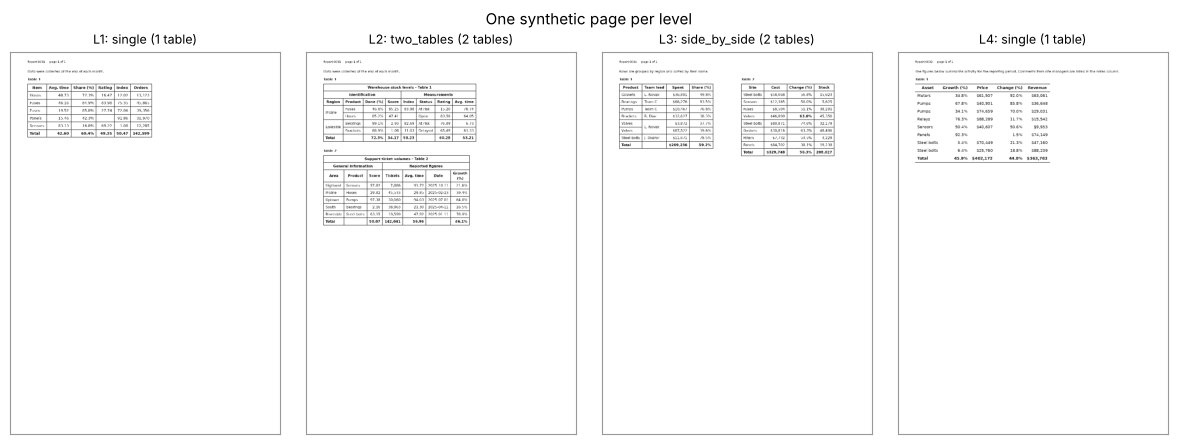

In [17]:
def show_pages(images: list, titles: list, suptitle: str, step: int = 2):
    """Show whole pages side by side (downsampled by `step` to keep the notebook small)."""
    fig, axes = plt.subplots(1, len(images), figsize=(3 * len(images), 4.5))
    for ax, img, title in zip(np.atleast_1d(axes), images, titles):
        ax.imshow(img[::step, ::step], cmap="gray", vmin=0, vmax=255)
        ax.set_title(title, fontsize=9)
        ax.set_xticks([]), ax.set_yticks([]), ax.grid(False)
        for spine in ax.spines.values():
            spine.set_visible(True), spine.set_color("0.6")
    fig.suptitle(suptitle, fontsize=11)
    plt.tight_layout()
    plt.show()


gallery = [("L1", 1), ("L2", 1), ("L3", 4), ("L4", 2)]
gallery_pages = []
for lvl, seed in gallery:
    d = make_document(lvl, seed)
    gallery_pages.append((f"{lvl}: {d.layout} ({len(d.tables)} table{'s' * (len(d.tables) > 1)})",
                          render_document(d)[0][0]))
show_pages([g[1] for g in gallery_pages], [g[0] for g in gallery_pages], "One synthetic page per level")

And here is what the scanner simulation does, at full resolution, to the top of page 2 of the
cross-page document: the repeated header rows, slight rotation, gray paper, softer strokes and
specks of dust.

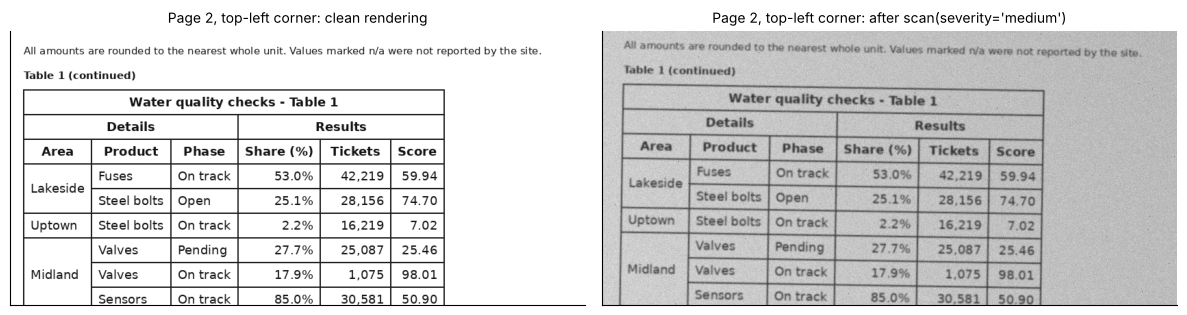

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, img, title in [(axes[0], pages_demo[1], "clean rendering"),
                       (axes[1], scans_demo[1][0], "after scan(severity='medium')")]:
    ax.imshow(img[60:460, 60:900], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Page 2, top-left corner: {title}", fontsize=10)
    ax.set_xticks([]), ax.set_yticks([]), ax.grid(False)
plt.tight_layout()
plt.show()

### 3.8 Exploratory analysis: which regularities can a pipeline rely on?

Before designing an extractor, a practitioner studies a labeled sample and writes down the
**regularities** of the documents: how many header rows, where merges occur, which rows are
bold, what happens at page breaks. Rules built on such regularities are cheap and very
effective, but they are only as good as the sample: a rule that holds on 100% of the sample
can fail on the first unusual document. (In our case the regularities are design choices of
the generator, so the numbers below simply confirm that the generator does what we intended.
With real data, this table is where your design decisions come from.)

In [19]:
def table_stats(t: Table, H: int) -> dict:
    """Regularity indicators of one logical table with H header rows."""
    C, R = t.n_cols, t.n_rows
    row0 = [c for c in t.cells if c.row == 0]
    row1 = [c for c in t.cells if c.row == 1 and c.colspan > 1]
    head = [c for c in t.cells if c.row < H and c.lines]
    body = [c for c in t.cells if H <= c.row < R - 1 and c.lines]
    last = [c for c in t.cells if c.row == R - 1 and c.lines]
    return {
        "header rows": H,
        "row 0 = one full-width cell": len(row0) == 1 and row0[0].colspan == C,
        "row 1 split at C//2": [(c.col, c.colspan) for c in row1] == [(0, C // 2), (C // 2, C - C // 2)],
        "header cells bold": np.mean([c.bold for c in head]),
        "body cells bold": np.mean([c.bold for c in body]) if body else 0.0,
        "last row bold": all(c.bold for c in last),
        "merged cells": sum(c.rowspan * c.colspan > 1 for c in t.cells),
        "multi-line cells": sum(len(c.lines) > 1 for c in t.cells),
    }


eda_rows, page_break_rows = [], []
for lvl in ["L1", "L2", "L3", "L4"]:
    for seed in range(100, 130):
        d = make_document(lvl, seed)
        for t, H in zip(d.tables, d.n_header):
            eda_rows.append({"level": lvl, **table_stats(t, H)})
        if d.layout == "cross_page":
            t, H = d.tables[0], d.n_header[0]
            first, second = d.pages[0][0].rows, d.pages[1][0].rows
            page_break_rows.append({
                "level": lvl,
                "page-1 part ends in a bold row": all(c.bold for c in t.cells if c.row == first[-1] and c.lines),
                "page-2 part repeats the header": second[:H] == list(range(H)),
            })
eda = pd.DataFrame(eda_rows)
print(f"{len(eda)} tables from {4 * 30} documents\n")
display(eda.groupby("level").mean().round(3).T)
print()
display(pd.DataFrame(page_break_rows).groupby("level").agg(["mean", "count"]))

146 tables from 120 documents



level,L1,L2,L3,L4
header rows,1.0,3.000,1.844,1.0
row 0 = one full-width cell,0.0,1.000,0.422,0.0
row 1 split at C//2,0.0,1.000,0.022,0.0
header cells bold,1.0,1.000,1.000,1.0
body cells bold,0.0,0.000,0.032,0.0
last row bold,1.0,1.000,1.000,1.0
merged cells,0.0,6.976,4.800,0.0
multi-line cells,0.0,0.927,0.889,0.0


page-1 part ends in a bold row       page-2 part repeats the header      
                                mean count                           mean count
level                                                                          
L2                               0.0    11                            1.0    11
L3                               0.0     8                            1.0     8

What we learn, and how the pipeline will use it:

| Regularity (from the table above) | Holds for | How we exploit it |
|---|---|---|
| header rows are always bold and body cells almost never | all levels | the header is a free, labeled sample of bold text *in this very table*: calibrate the bold detector per table (Section 9) |
| a 3-row header starts with one cell spanning **all** columns | every hierarchical header | infer the number of header rows from the structure: $H = 3$ if row 0 is a single full-width cell, otherwise $H = 1$ |
| in L2, header row 1 splits at column $\lfloor C/2 \rfloor$ | L2 only (L3 is irregular) | a sanity check, but **not** a rule we hard-code, because it would break on L3 |
| the last row is bold only at the true end of a table (and every finished table has a bold totals row) | all levels | a table whose last row is *not* bold must continue on the next page |
| a continuation repeats the header rows | every cross-page table | drop exactly the repeated header rows when stitching |

> **Common pitfall.** Over-fitting rules to the sample. "Row 1 splits at $\lfloor C/2 \rfloor$"
> is true for every L2 table, so a rule that *forces* it would look perfect on L2 and silently
> destroy every L3 table. Prefer rules that measure the page (line coverage, stroke width) and
> use regularities as *tie-breakers* or *calibration data*.

**Quick check.** Why is "the header is bold" more useful for bold detection than a fixed
threshold learned once on many pages?

<details><summary>Answer</summary>

Stroke thickness in pixels depends on the font size, the scan resolution, blur and the
binarization threshold, all of which change from page to page. A fixed threshold mixes these
nuisance factors with boldness. Comparing a row against the header *of the same table* cancels
most of them: same page, same scan, same font size.
</details>

## 4. Preprocessing: deskew, contrast, binarization

Every later stage assumes that table lines are perfectly horizontal and vertical and that
each pixel is clearly "ink" or "paper". Preprocessing makes those assumptions true.

### 4.1 Deskewing with the Hough transform

**Intuition.** A scanned page rotated by $1.5^\circ$ turns every long horizontal rule into a
slightly tilted line. If we can measure the tilt of the long lines, we rotate the page back by
the same angle. The long lines are the most reliable evidence on the page: a table has dozens
of them, and they are far longer than any letter.

**The Hough transform** finds lines by voting. Any straight line can be written as

$$
\rho = x \cos\theta + y \sin\theta ,
$$

where $\theta$ is the angle of the line's normal and $\rho$ its distance from the origin. Each
edge pixel $(x, y)$ votes for all $(\rho, \theta)$ pairs of lines passing through it (a sinusoid
in the $(\theta, \rho)$ plane), and collinear pixels vote for the same cell of the accumulator, which
becomes a peak. The *probabilistic* variant (`cv2.HoughLinesP`) returns segments with
endpoints $(x_1, y_1, x_2, y_2)$, from which the tilt is

$$
\varphi = \operatorname{atan2}(y_2 - y_1,\; x_2 - x_1).
$$

Our recipe:

1. downscale the page by 2 (four times fewer pixels, the angle is unchanged).
2. Canny edge detection (thin edges are what Hough expects).
3. `HoughLinesP` with a minimum segment length of $W/5$, so that only long rules vote.
4. keep near-horizontal segments ($|\varphi| \le 5^\circ$) and take the **median** angle.
5. rotate the page by that angle around its center (paper-white border).

Why the median and not the mean? A few segments come from vertical rules that happen to pass
the filter, or from two lines joined at a corner. The median ignores such outliers, while a
single wild segment can drag the mean far away.

Signs are easy to get wrong, so let us fix them: in image coordinates $y$ grows *downward*.
A page rotated counter-clockwise on screen by $\alpha$ shows horizontal rules with
$\varphi = -\alpha$, and rotating by $\varphi$ (counter-clockwise convention of OpenCV) undoes it.

In [20]:
def estimate_skew(gray: np.ndarray, max_angle: float = 5.0) -> tuple:
    """Median tilt (degrees) of long, near-horizontal segments (Canny + probabilistic Hough).

    Returns (angle, all accepted segment angles). Rotating the page by `angle` straightens it.
    """
    small = cv2.resize(gray, None, fx=0.5, fy=0.5, interpolation=cv2.INTER_AREA)
    edges = cv2.Canny(small, 50, 150)
    W = small.shape[1]
    segs = cv2.HoughLinesP(edges, rho=1, theta=np.pi / 720, threshold=W // 8,
                           minLineLength=W // 5, maxLineGap=W // 100)
    if segs is None:
        return 0.0, np.array([])
    x1, y1, x2, y2 = segs.reshape(-1, 4).T.astype(float)
    phi = np.degrees(np.arctan2(y2 - y1, x2 - x1))
    phi = (phi + 90.0) % 180.0 - 90.0                     # a segment has no direction: map to [-90, 90)
    phi = phi[np.abs(phi) <= max_angle]
    return (float(np.median(phi)) if len(phi) else 0.0), phi


def rotate_page(gray: np.ndarray, angle: float) -> tuple:
    """Rotate around the page center, filling the corners with the paper's gray level."""
    H, W = gray.shape
    D = cv2.getRotationMatrix2D((W / 2, H / 2), angle, 1.0)
    paper = int(np.median(gray[::8, ::8]))
    return cv2.warpAffine(gray, D, (W, H), flags=cv2.INTER_LINEAR, borderValue=paper), D


scanned, M_scan = scans_demo[1]
true_angle = math.degrees(math.atan2(-M_scan[1, 0], M_scan[0, 0]))
est, seg_angles = estimate_skew(scanned)
straight, D_demo = rotate_page(scanned, est)
print(f"true rotation {true_angle:+.3f} deg | estimated tilt of the rules {est:+.3f} deg "
      f"| {len(seg_angles)} segments voted | residual {true_angle + est:+.3f} deg")

true rotation -0.903 deg | estimated tilt of the rules +0.725 deg | 19 segments voted | residual -0.178 deg


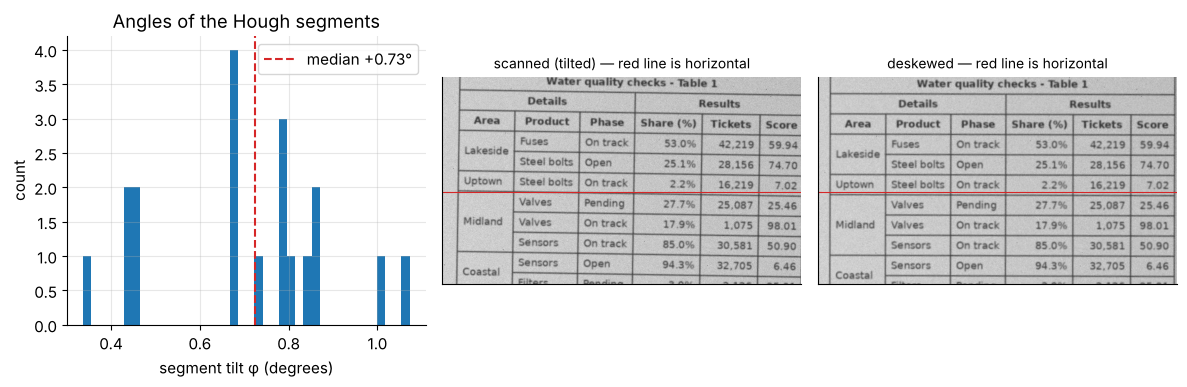

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].hist(seg_angles, bins=40, color="tab:blue")
axes[0].axvline(est, color="tab:red", ls="--", label=f"median {est:+.2f}°")
axes[0].set(title="Angles of the Hough segments", xlabel="segment tilt φ (degrees)", ylabel="count")
axes[0].legend()
for ax, img, title in [(axes[1], scanned, "scanned (tilted)"), (axes[2], straight, "deskewed")]:
    ax.imshow(img[150:520, 60:700], cmap="gray", vmin=0, vmax=255)
    ax.axhline(205, color="tab:red", lw=0.8)            # a perfectly horizontal reference line
    ax.set_title(title + ": red line is horizontal", fontsize=10)
    ax.set_xticks([]), ax.set_yticks([]), ax.grid(False)
plt.tight_layout()
plt.show()

The estimate is close but not exact, and the error points towards zero. The culprit is the pixel
**staircase**: on a pixel grid, a rule tilted by $\alpha$ becomes a series of perfectly horizontal
steps, each about $1/\tan\alpha$ pixels long ($\approx 190$ px at $0.3^\circ$, $\approx 64$ px at
$0.9^\circ$). Below about $0.46^\circ$ a step is longer than the minimum segment length
($W/5 = 124$ px on the half-size page), so whole Hough segments can lie *on* one step and report
exactly $0^\circ$. At larger tilts, like the $0.9^\circ$ of this page, every segment spans two or
more steps (no segment in the histogram above is near $0^\circ$), but its two endpoints are whole
pixels on a jagged edge, so the rise measured between them is typically off by a fraction of a
pixel, more often too small than too large. That small slip matters: on a 150-pixel segment,
half a pixel of missing rise already costs $0.5/150$ rad $\approx 0.2^\circ$. Either way, the
median is biased towards zero.

**Refinement with a projection profile.** Rotate the ink image by a candidate angle $a$ and sum
each pixel row: $P_a(y) = \sum_x I_a(x, y)$, where $I_a$ is the ink (inverted gray) image
after rotation. When the rules are exactly horizontal, the ink of each rule piles up in one or
two rows, which form tall, narrow spikes in $P_a$. When they are tilted, the same ink smears over many
rows. A good sharpness score is the energy of the profile's differences,

$$
S(a) = \sum_{y} \big(P_a(y+1) - P_a(y)\big)^2 ,
$$

which is largest for the sharpest spikes. We search $a$ on a fine grid ($0.05^\circ$) in a
small window ($\pm 0.5^\circ$) around the Hough estimate: Hough gives a *robust* coarse answer
over a wide range, the profile gives a *precise* answer over a narrow range. Coarse-to-fine
search is a pattern you will meet again and again.

In [22]:
def refine_skew(gray: np.ndarray, center: float, half: float = 0.5, step: float = 0.05) -> tuple:
    """Angle in [center-half, center+half] that makes the row profile of the ink sharpest."""
    small = cv2.resize(gray, None, fx=0.5, fy=0.5, interpolation=cv2.INTER_AREA)
    ink = 255 - small
    h, w = ink.shape
    angles = np.arange(center - half, center + half + 1e-9, step)
    scores = []
    for a in angles:
        D = cv2.getRotationMatrix2D((w / 2, h / 2), float(a), 1.0)
        rotated = cv2.warpAffine(ink, D, (w, h), flags=cv2.INTER_LINEAR, borderValue=0)
        profile = rotated.sum(axis=1, dtype=np.float64)
        scores.append(np.sum(np.diff(profile) ** 2))
    return float(angles[int(np.argmax(scores))]), angles, np.array(scores)


def deskew(gray: np.ndarray, refine: bool = True) -> tuple:
    """Straighten a page. Returns (straight image, angle used, 2x3 matrix D: input -> output)."""
    angle, _ = estimate_skew(gray)
    if refine:
        angle, _, _ = refine_skew(gray, angle)
    straight, D = rotate_page(gray, angle)
    return straight, angle, D


skew_rows = []
skew_rng = np.random.default_rng(1)
for k in range(4):
    img, M = scan(pages_demo[0], skew_rng, "medium")
    true = math.degrees(math.atan2(-M[1, 0], M[0, 0]))
    coarse, _ = estimate_skew(img)
    fine, angles, scores = refine_skew(img, coarse)
    skew_rows.append({"true rotation": true, "Hough estimate": -coarse, "refined": -fine,
                      "|error| Hough": abs(true + coarse), "|error| refined": abs(true + fine)})
skew_df = pd.DataFrame(skew_rows)
display(skew_df.round(3))
print("mean |error|: Hough %.3f deg -> refined %.3f deg" % tuple(skew_df[["|error| Hough", "|error| refined"]].mean()))

,true rotation,Hough estimate,refined,|error| Hough,|error| refined
0,0.059,-0.000,0.000,0.059,0.059
1,-1.863,-1.747,-1.847,0.116,0.016
2,-0.565,-0.431,-0.531,0.135,0.035
3,1.934,1.967,1.917,0.032,0.018


mean |error|: Hough 0.086 deg -> refined 0.032 deg


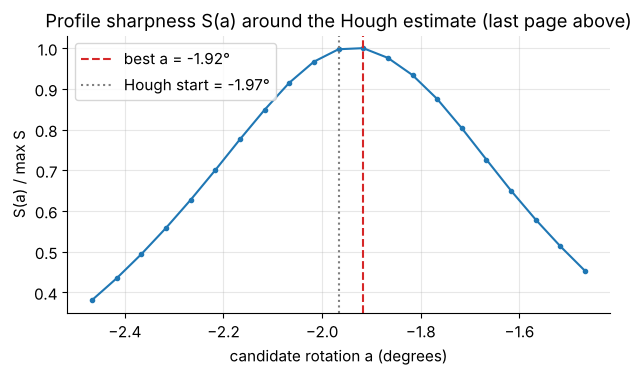

In [23]:
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(angles, scores / scores.max(), "o-", ms=3)
ax.axvline(fine, color="tab:red", ls="--", label=f"best a = {fine:+.2f}°")
ax.axvline(coarse, color="tab:gray", ls=":", label=f"Hough start = {coarse:+.2f}°")
ax.set(title="Profile sharpness S(a) around the Hough estimate (last page above)",
       xlabel="candidate rotation a (degrees)", ylabel="S(a) / max S")
ax.legend()
plt.show()

### 4.2 Contrast: from histogram equalization to CLAHE

After deskewing, we want a clean black-and-white image. The difficulty is **uneven lighting**:
the paper is bright gray on one side of the page and dark gray on the other, so no single
global threshold separates "ink" from "paper" everywhere.

**Histogram equalization (HE).** Let $h(v)$ be the number of pixels with gray level
$v \in \{0, \dots, 255\}$ and $\text{CDF}(v) = \frac{1}{N}\sum_{u \le v} h(u)$ the fraction of
pixels at most as bright as $v$. HE maps every pixel through

$$
T(v) = \operatorname{round}\big(255 \cdot \text{CDF}(v)\big),
$$

which spreads the gray levels that are actually used over the whole range. The slope of $T$ at
$v$ is proportional to $h(v)$: crowded gray levels are pulled apart.

**Adaptive HE (AHE)** computes a separate mapping for each tile of an $8 \times 8$ grid and
blends the mappings of neighboring tiles bilinearly, so each region gets its own contrast
stretch and no seams appear at tile borders. AHE has one flaw: a tile of plain paper has a
very narrow histogram (only noise), and stretching it to the full range turns invisible
sensor noise into black speckles.

**Contrast-limited AHE (CLAHE)** fixes this by **clipping** each tile's histogram at a limit
(OpenCV's `clipLimit=2.0` means twice the average bin height) and spreading the clipped
excess evenly over all bins before computing the CDF. Because the slope of the mapping is
proportional to the histogram height, clipping the histogram caps the slope, i.e. it caps how
much noise can be amplified.

### 4.3 Binarization with Otsu's method

Binarization picks a threshold $t$ and labels pixels with $v \le t$ as ink. Otsu's idea: the
best $t$ makes the two classes as **compact** as possible. Let $p(v) = h(v)/N$, and for a
threshold $t$ let

$$
\omega_0 = \sum_{v \le t} p(v), \quad \omega_1 = 1 - \omega_0, \quad
\mu_0 = \frac{1}{\omega_0}\sum_{v \le t} v\,p(v), \quad \mu_1 = \frac{1}{\omega_1}\sum_{v > t} v\,p(v)
$$

be the class weights and means, and $\mu_T = \omega_0\mu_0 + \omega_1\mu_1$ the global mean.
The total variance splits into a *within-class* and a *between-class* part,

$$
\sigma_T^2 = \underbrace{\omega_0\sigma_0^2 + \omega_1\sigma_1^2}_{\sigma_W^2(t)}
+ \underbrace{\omega_0\omega_1(\mu_0 - \mu_1)^2}_{\sigma_B^2(t)} .
$$

(To see it, write $\sum_v p(v)(v-\mu_T)^2$ separately over each class and expand
$v - \mu_T = (v - \mu_k) + (\mu_k - \mu_T)$: the cross terms vanish because $\mu_k$ is the class
mean, leaving $\sigma_W^2 + \omega_0(\mu_0-\mu_T)^2 + \omega_1(\mu_1-\mu_T)^2$, and the last two
terms simplify to $\omega_0\omega_1(\mu_0-\mu_1)^2$ using $\omega_0 + \omega_1 = 1$.)
Since $\sigma_T^2$ does not depend on $t$, **minimizing the within-class variance is the same
as maximizing $\sigma_B^2(t)$**, and $\sigma_B^2$ is cheap: with the cumulative sums
$\omega_0(t)$ and $m(t) = \sum_{v \le t} v\,p(v)$,

$$
\sigma_B^2(t) = \frac{\big(\mu_T\,\omega_0(t) - m(t)\big)^2}{\omega_0(t)\,\big(1 - \omega_0(t)\big)} ,
$$

so all 256 candidates are evaluated with two `cumsum` calls.

**A tiny example by hand.** Ten pixels: three at gray level 10, one at 20, four at 200 and
two at 240, so $\mu_T = (3\cdot10 + 20 + 4\cdot200 + 2\cdot240)/10 = 133$.

| split after | $\omega_0$ | $\mu_0$ | $\omega_1$ | $\mu_1$ | $\sigma_B^2 = \omega_0\omega_1(\mu_0-\mu_1)^2$ |
|---|---|---|---|---|---|
| 10 | 0.3 | 10 | 0.7 | 185.71 | $0.21 \times 175.71^2 = 6483.9$ |
| 20 | 0.4 | 12.5 | 0.6 | 213.33 | $0.24 \times 200.83^2 = 9680.2$ |
| 200 | 0.8 | 106.25 | 0.2 | 240 | $0.16 \times 133.75^2 = 2862.3$ |

The winner splits between 20 and 200: dark pixels $\{10, 20\}$ are ink, bright pixels paper.
The code below reproduces these numbers.

In [24]:
def otsu_threshold(gray: np.ndarray) -> tuple:
    """Otsu's threshold t (pixels <= t form the dark class) and the curve sigma_B^2(t)."""
    p = np.bincount(gray.ravel(), minlength=256).astype(float)
    p /= p.sum()
    v = np.arange(256)
    w0, m = np.cumsum(p), np.cumsum(v * p)
    mu_t = m[-1]
    with np.errstate(divide="ignore", invalid="ignore"):   # w0 = 0 or 1 gives 0/0: no split there
        sigma_b = (mu_t * w0 - m) ** 2 / (w0 * (1.0 - w0))
    sigma_b = np.nan_to_num(sigma_b, nan=0.0, posinf=0.0)
    return int(np.argmax(sigma_b)), sigma_b


toy = np.array([10, 10, 10, 20, 200, 200, 200, 200, 240, 240], dtype=np.uint8)
t_toy, curve = otsu_threshold(toy)
print("toy: best threshold t =", t_toy, "| sigma_B^2 at splits after 10, 20, 200:",
      [round(float(curve[t]), 1) for t in (10, 20, 200)])

t_ours, _ = otsu_threshold(straight)
t_cv, _ = cv2.threshold(straight, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print(f"deskewed page: our Otsu threshold = {t_ours}, OpenCV = {int(t_cv)}")

toy: best threshold t = 20 | sigma_B^2 at splits after 10, 20, 200: [6483.9, 9680.2, 2862.3]
deskewed page: our Otsu threshold = 161, OpenCV = 161


### 4.4 When global thresholds fail: flattening and local thresholds

Otsu assumes a histogram with two clear bumps (ink and paper). On a page, ink covers only a few
percent of the pixels. If the lighting is uneven, the paper itself spreads into a wide bump,
and the threshold that maximizes $\sigma_B^2$ may simply split *the paper* into a bright half and
a dark half. CLAHE does not fully rescue this: inside a tile of blank paper there is nothing but
noise, and equalizing it amplifies that noise.

Two classic remedies:

* **Flat-field correction.** Model the observed gray level as reflectance times illumination,
  $I(x, y) = R(x, y)\, L(x, y)$, with $R \approx 1$ on paper. Estimate $L$ with a **morphological
  closing** of the gray image by a $31 \times 31$ square: a *dilation* (local maximum) that
  replaces every thin dark structure (text, ruling lines, all far thinner than 31 pixels) by the
  surrounding paper, followed by an *erosion* (local minimum) that restores the extent of the
  bright regions, and divide: $I / L \approx R$. Then threshold globally.
* **Local (adaptive) thresholding.** Give every pixel its own threshold,

$$
T(x, y) = m_{31}(x, y) - C ,
$$

  where $m_{31}(x, y)$ is the mean gray level in the $31 \times 31$ window centered at $(x, y)$, and
  call the pixel ink if $I(x, y) \le T(x, y)$. Shading changes slowly, so the local mean follows
  the paper. A pixel must be at least $C = 20$ gray levels darker than its surroundings to count
  as ink, which blank paper rarely is.

To compare the options we need a ground truth: the true ink mask is the clean page moved
through the scan rotation $M$ and the deskew rotation $D$. Two numbers matter: **recall** (how
much true ink is found) and **false ink far from any stroke** (pixels labeled ink more than 3
pixels from real ink, as a percentage of the page). We do *not* use precision: blur legitimately
widens strokes by a pixel or two, which would look like false positives. Ink is set to 255 (white
on black) because morphology, contours and pixel counts all treat nonzero pixels as "the object".

In [25]:
CLAHE = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))


def flatten_background(gray: np.ndarray, k: int = 31) -> np.ndarray:
    """Divide by a morphological-closing estimate of the paper (removes uneven lighting)."""
    paper = cv2.morphologyEx(gray, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_RECT, (k, k)))
    return cv2.divide(gray, paper, scale=255)


def binarize(gray: np.ndarray, method: str = "adaptive") -> np.ndarray:
    """Ink mask (uint8, ink = 255). method: 'otsu', 'clahe', 'flat' or 'adaptive' (our default)."""
    if method == "adaptive":
        return cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY_INV, 31, 20)
    src = {"otsu": gray, "clahe": CLAHE.apply(gray), "flat": flatten_background(gray)}[method]
    _, ink = cv2.threshold(src, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    return ink


def compose(A: np.ndarray, B: np.ndarray) -> np.ndarray:
    """2x3 affine matrices: the map 'first B, then A'."""
    return (np.vstack([A, [0, 0, 1]]) @ np.vstack([B, [0, 0, 1]]))[:2]


BIN_METHODS = {"otsu": "Otsu", "clahe": "CLAHE + Otsu", "flat": "flatten + Otsu", "adaptive": "local mean - C"}
bin_page = render_document(make_document("L2", 1))[0][0]
bin_rows, bin_masks = [], {}
for severity in ["medium", "heavy"]:
    img, M = scan(bin_page, np.random.default_rng(7), severity)
    straight_img, _, D = deskew(img)
    true_ink = cv2.warpAffine((bin_page < 128).astype(np.uint8), compose(D, M), bin_page.shape[::-1],
                              flags=cv2.INTER_NEAREST)
    near = cv2.dilate(true_ink, np.ones((7, 7), np.uint8)) > 0
    for method, label in BIN_METHODS.items():
        pred = binarize(straight_img, method) > 0
        bin_rows.append({"severity": severity, "method": label,
                         "ink recall": (pred & (true_ink > 0)).sum() / true_ink.sum(),
                         "false ink far from strokes (% of page)": 100 * (pred & ~near).mean()})
        if severity == "heavy":
            bin_masks[label] = pred
    if severity == "heavy":
        heavy_straight = straight_img
display(pd.DataFrame(bin_rows).set_index(["severity", "method"]).round(3))

ink recall  false ink far from strokes (% of page)
severity method                                                            
medium   Otsu                 0.994                                   0.032
         CLAHE + Otsu         0.999                                   1.051
         flatten + Otsu       0.993                                   0.020
         local mean - C       0.989                                   0.073
heavy    Otsu                 1.000                                  33.847
         CLAHE + Otsu         0.999                                  28.800
         flatten + Otsu       0.992                                   1.673
         local mean - C       0.934                                   0.765

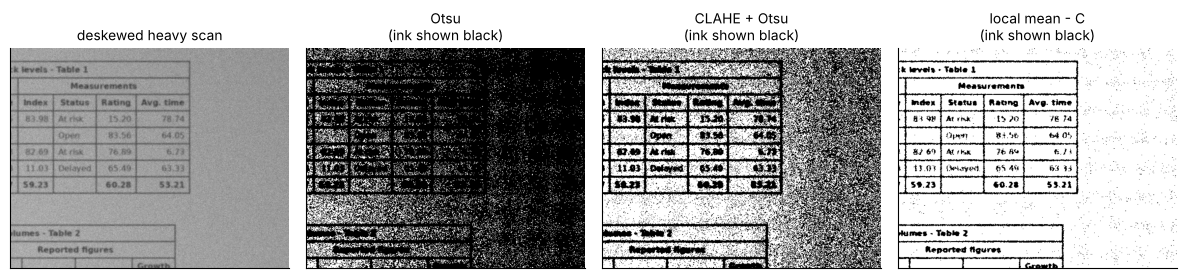

In [26]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3.6))
ys, xs = slice(120, 560), slice(420, 980)                 # a table edge and blank paper
axes[0].imshow(heavy_straight[ys, xs], cmap="gray", vmin=0, vmax=255)
axes[0].set_title("deskewed heavy scan", fontsize=10)
for ax, name in zip(axes[1:], ["Otsu", "CLAHE + Otsu", "local mean - C"]):
    ax.imshow(~bin_masks[name][ys, xs], cmap="gray")
    ax.set_title(name + "\n(ink shown black)", fontsize=10)
for ax in axes:
    ax.set_xticks([]), ax.set_yticks([]), ax.grid(False)
plt.tight_layout()
plt.show()

Read the table row by row:

* At the *medium* level every method finds the ink, but **CLAHE** marks noticeably more paper
  as ink far away from any stroke: amplified paper noise, exactly the AHE failure above.
* At the *heavy* level the global methods collapse: Otsu labels about a third of the page as
  ink, because its threshold now separates the dark side of the paper from the bright side.
  Flattening helps a lot, but a global threshold still struggles with the remaining noise.
* The **local threshold** keeps false ink low at both levels. It pays with some recall at the
  heavy level (faint, blurred strokes that are less than 20 gray levels darker than their
  neighborhood are lost), which the long, redundant table lines easily survive.

We use the local threshold as the default. There is a second, less obvious reason, which we
will meet in the next section: contrast stretching also fills the 1–3 pixel gaps *between
letters*, and fused letters are poison for line extraction.

> **Key idea.** Choose preprocessing by measuring what the *next* stage needs, not by how nice
> the image looks.

**Quick check.** Why does the flat-field correction *divide* by the estimated background
instead of subtracting it?

<details><summary>Answer</summary>

Shading is multiplicative: a region that receives 70% of the light reflects 70% of the light
from paper *and* 70% from ink, so $I = R \cdot L$. Dividing by $L$ restores $R$ for both. Subtracting
would leave the contrast between ink and paper smaller in the dark region than in the bright
one, so a single threshold would still not fit everywhere.
</details>

## 5. Ruling lines and table localization

### 5.1 Morphology in one paragraph

Think of a binary image as a set of white (ink) pixels and of a **structuring element** $B$ as a
small stencil. **Erosion** keeps a pixel only if the stencil, centered there, fits entirely
inside the ink, and **dilation** turns a pixel on if the stencil touches any ink. An **opening** is an
erosion followed by a dilation with the same stencil:

$$
A \circ B = (A \ominus B) \oplus B .
$$

Its effect is easy to state: **the opening keeps exactly the parts of the ink in which the
stencil fits, and deletes everything else.** With a long, thin stencil (a $1 \times k$ row of
pixels), only horizontal runs of ink at least $k$ pixels long survive. Letters are made of short
strokes (at our font sizes no horizontal stroke is longer than about 15 pixels), while a table
rule is hundreds of pixels long. So

* opening with a horizontal stencil of length $k_h$ keeps the **horizontal rules**.
* opening with a vertical stencil of length $k_v$ keeps the **vertical rules**.

The stencil lengths must sit between two limits: longer than any stroke of a character, and
shorter than the shortest real line segment (one column width for horizontal rules, one row
height for vertical ones). We set them **relative to the page size**, $k_h = W/30 \approx 41$ and
$k_v = H/60 \approx 29$ pixels on a $1240 \times 1754$ page, so the same code works at another
resolution. The vertical limit is the tight one: a one-line row is only about 33 pixels tall,
while a `|` or a parenthesis in the text is about 20 pixels tall.

*After* opening we apply a tiny **closing** (dilation then erosion) along the same direction with a
7-pixel stencil, which bridges the small gaps that noise and blur punch into thin lines. The order
matters: closing *before* opening would also bridge the 1–3 pixel gaps between neighboring
letters, turn every word into a long horizontal run, and let text survive the opening.

,horizontal pieces,pieces narrower than 150 px
binarization,,
CLAHE + Otsu,66,53
local mean - C,13,0


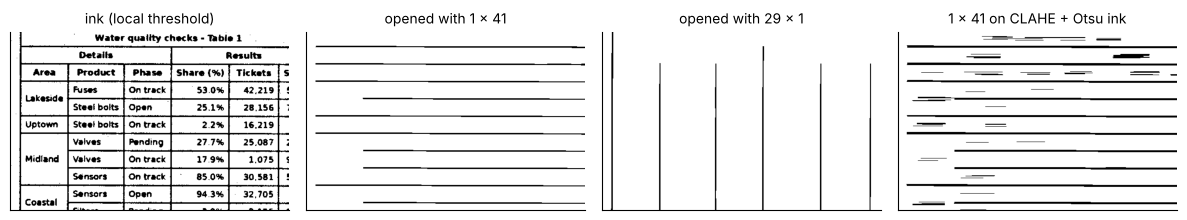

In [27]:
def line_masks(ink: np.ndarray, frac_h: float = 1 / 30, frac_v: float = 1 / 60) -> tuple:
    """Masks of horizontal and vertical ruling lines: open with long thin kernels, then bridge tiny gaps."""
    H, W = ink.shape
    kh, kv = max(15, int(W * frac_h)), max(15, int(H * frac_v))
    rect = cv2.getStructuringElement
    horiz = cv2.morphologyEx(ink, cv2.MORPH_OPEN, rect(cv2.MORPH_RECT, (kh, 1)))
    horiz = cv2.morphologyEx(horiz, cv2.MORPH_CLOSE, rect(cv2.MORPH_RECT, (7, 1)))
    vert = cv2.morphologyEx(ink, cv2.MORPH_OPEN, rect(cv2.MORPH_RECT, (1, kv)))
    vert = cv2.morphologyEx(vert, cv2.MORPH_CLOSE, rect(cv2.MORPH_RECT, (1, 7)))
    return horiz, vert


ink_demo = binarize(straight)                          # page 2 of the cross-page demo (medium scan)
h_mask, v_mask = line_masks(ink_demo)
frag_rows = []
for method in ["clahe", "adaptive"]:
    h = line_masks(binarize(straight, method))[0]
    n, _, stats, _ = cv2.connectedComponentsWithStats(h)
    widths = stats[1:, cv2.CC_STAT_WIDTH]
    frag_rows.append({"binarization": BIN_METHODS[method], "horizontal pieces": n - 1,
                      "pieces narrower than 150 px": int((widths < 150).sum())})
    if method == "clahe":
        h_clahe = h
display(pd.DataFrame(frag_rows).set_index("binarization"))

fig, axes = plt.subplots(1, 4, figsize=(12, 3.4))
ys, xs = slice(150, 520), slice(60, 640)
for ax, img, title in [(axes[0], ink_demo, "ink (local threshold)"),
                       (axes[1], h_mask, "opened with 1 x 41"),
                       (axes[2], v_mask, "opened with 29 x 1"),
                       (axes[3], h_clahe, "1 x 41 on CLAHE + Otsu ink")]:
    ax.imshow(255 - img[ys, xs], cmap="gray", vmin=0, vmax=255)
    ax.set_title(title, fontsize=10)
    ax.set_xticks([]), ax.set_yticks([]), ax.grid(False)
plt.tight_layout()
plt.show()

With the local threshold, the opening leaves only ruling lines. With CLAHE + Otsu, dozens of
short pieces survive: these are words whose letters were fused into one blob by the contrast
stretch, so the stencil fits inside them. Every such piece would later look like a short ruling
line and could invent a row boundary. This is the "less obvious reason" promised above.

### 5.2 Finding the tables

A ruled table is a big connected web of lines. To find each table:

1. take the union of both line masks and dilate it slightly (a $5 \times 5$ square), so lines
   that almost touch at a corner become connected.
2. find the **external contours** of the white blobs (`cv2.findContours` with `RETR_EXTERNAL`
   ignores the holes, i.e. the cells) and their bounding boxes.
3. discard boxes that are too small to be tables (narrower than 15% of the page or shorter than
   2% of it): stray underlines, a rule under a page header, specks.

Tables with **horizontal rules only** (our level L4) never form a connected web, because nothing
joins the rules vertically. We catch them separately: long horizontal rules that are *not*
inside a ruled table and share the same left and right ends (within a few pixels) belong to one
**open** table spanning from the first rule to the last.

Finally we sort the tables in **reading order**: group boxes into horizontal *bands* (boxes whose
vertical extents overlap by more than half belong to the same band, as with side-by-side tables), order
the bands top to bottom and the boxes inside a band left to right.

In [28]:
def preprocess(gray: np.ndarray, use_deskew: bool = True, method: str = "adaptive") -> dict:
    """Deskew -> binarize -> line masks. D maps input-page coordinates to output coordinates."""
    if use_deskew:
        straight_img, angle, D = deskew(gray)
    else:
        straight_img, angle, D = gray, 0.0, np.array([[1.0, 0.0, 0.0], [0.0, 1.0, 0.0]])
    ink = binarize(straight_img, method)
    h, v = line_masks(ink)
    return dict(gray=straight_img, angle=angle, D=D, ink=ink, h=h, v=v)


def reading_order(tables: list, min_overlap: float = 0.5) -> list:
    """Sort table dicts (with 'box' = (x0, y0, x1, y1)) into bands top-down, left-right inside a band."""
    bands = []
    for t in sorted(tables, key=lambda t: t["box"][1]):
        y0, y1 = t["box"][1], t["box"][3]
        if bands:
            b = bands[-1]
            overlap = min(y1, b["y1"]) - max(y0, b["y0"])
            if overlap > min_overlap * min(y1 - y0, b["y1"] - b["y0"]):
                b["items"].append(t)
                b["y1"] = max(b["y1"], y1)
                continue
        bands.append({"y0": y0, "y1": y1, "items": [t]})
    return [t for b in bands for t in sorted(b["items"], key=lambda t: t["box"][0])]


def find_tables(h: np.ndarray, v: np.ndarray, min_w: float = 0.15, min_h: float = 0.02,
                tol: int = 12) -> list:
    """Locate ruled ('grid') and horizontal-rules-only ('open') tables. Returns dicts in reading order."""
    H, W = h.shape
    web = cv2.dilate(cv2.bitwise_or(h, v), np.ones((5, 5), np.uint8))
    contours, _ = cv2.findContours(web, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    tables = []
    for cnt in contours:
        x, y, w, hh = cv2.boundingRect(cnt)
        if w >= min_w * W and hh >= min_h * H:
            tables.append({"box": (x, y, x + w, y + hh), "kind": "grid"})
    # open tables: long horizontal rules outside every grid table, grouped by their x-extent
    n, _, stats, _ = cv2.connectedComponentsWithStats(h)
    rules = []
    for x, y, w, hh, _ in stats[1:]:
        inside = any(b[0] - 3 <= x and x + w <= b[2] + 3 and b[1] - 3 <= y <= b[3] + 3
                     for b in (t["box"] for t in tables))
        if w >= min_w * W and not inside:
            rules.append((x, y, x + w, y + hh))
    rules.sort(key=lambda r: r[1])
    groups = []
    for r in rules:
        g = next((g for g in groups if abs(g[-1][0] - r[0]) <= tol and abs(g[-1][2] - r[2]) <= tol
                  and r[1] - g[-1][3] < 0.35 * H), None)
        if g is None:
            groups.append([r])
        else:
            g.append(r)
    for g in groups:
        if len(g) >= 2:
            tables.append({"box": (min(r[0] for r in g), g[0][1], max(r[2] for r in g), g[-1][3]),
                           "kind": "open", "rules": [(r[1] + r[3]) / 2 for r in g]})
    return reading_order(tables)


loc_demos = []
for lvl, seed in [("L2", 1), ("L3", 4), ("L4", 2)]:
    d = make_document(lvl, seed)
    img, M = scan(render_document(d)[0][0], np.random.default_rng(seed), "medium")
    pre = preprocess(img)
    found = find_tables(pre["h"], pre["v"])
    loc_demos.append((lvl, d.layout, pre, found))
    print(f"{lvl} {d.layout:12s}: {len(found)} table(s) found ->",
          [(t["kind"], tuple(int(c) for c in t["box"])) for t in found])

L2 two_tables  : 2 table(s) found -> [('grid', (75, 142, 783, 414)), ('grid', (76, 470, 755, 798))]
L3 side_by_side: 2 table(s) found -> [('grid', (76, 142, 515, 447)), ('grid', (636, 142, 1071, 480))]


L4 single      : 1 table(s) found -> [('open', (78, 144, 700, 508))]


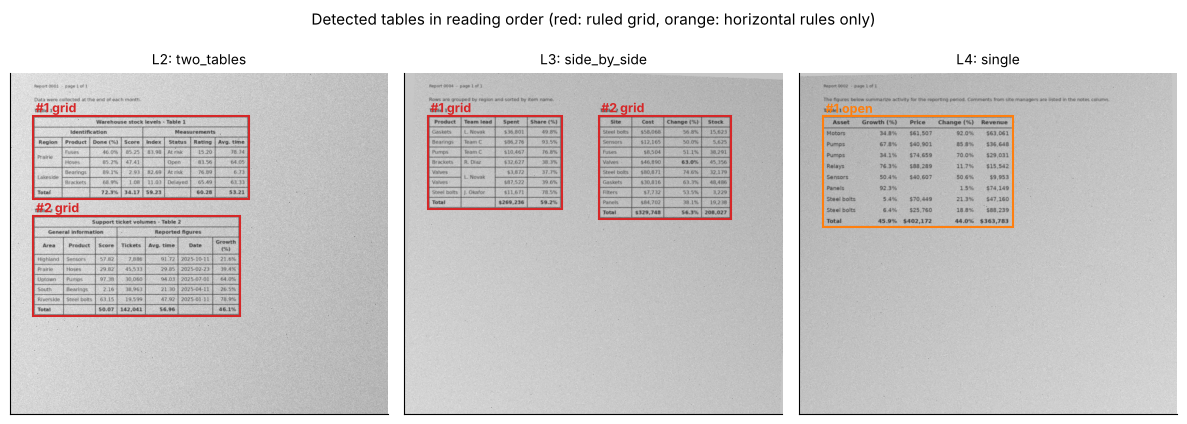

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4.5))
for ax, (lvl, layout, pre, found) in zip(axes, loc_demos):
    ax.imshow(pre["gray"][::2, ::2], cmap="gray", vmin=0, vmax=255)
    for k, t in enumerate(found):
        x0, y0, x1, y1 = (c / 2 for c in t["box"])
        color = "tab:red" if t["kind"] == "grid" else "tab:orange"
        ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, lw=1.5, ec=color))
        ax.text(x0 + 4, y0 - 6, f"#{k + 1} {t['kind']}", color=color, fontsize=9, weight="bold")
    ax.set_ylim(560, 0)                                   # show the top part of the page only
    ax.set_title(f"{lvl}: {layout}", fontsize=10)
    ax.set_xticks([]), ax.set_yticks([]), ax.grid(False)
fig.suptitle("Detected tables in reading order (red: ruled grid, orange: horizontal rules only)", fontsize=11)
plt.tight_layout()
plt.show()

To score a detected box against the true one we use **intersection over union**,

$$
\text{IoU}(A, B) = \frac{|A \cap B|}{|A \cup B|} = \frac{|A \cap B|}{|A| + |B| - |A \cap B|} \in [0, 1],
$$

where $|\cdot|$ is an area. IoU is 1 for identical boxes and 0 for disjoint ones. A common rule
is to count a detection as correct when IoU $\ge 0.5$. In Section 13 we use the same formula to
match predicted *cells* with true cells.

In [30]:
# ✏️ Exercise 3: intersection over union of two boxes
def box_iou(a: tuple, b: tuple) -> float:
    """IoU of axis-aligned boxes given as (x0, y0, x1, y1) with x0 < x1 and y0 < y1."""
    # YOUR CODE HERE
    raise NotImplementedError

def _test():
    assert abs(box_iou((0, 0, 10, 10), (0, 0, 10, 10)) - 1.0) < 1e-12, "identical boxes"
    assert box_iou((0, 0, 10, 10), (20, 20, 30, 30)) == 0.0, "disjoint boxes"
    assert box_iou((0, 0, 10, 10), (10, 0, 20, 10)) == 0.0, "touching edges have zero overlap"
    assert abs(box_iou((0, 0, 10, 10), (5, 0, 15, 10)) - 50 / 150) < 1e-12, box_iou((0, 0, 10, 10), (5, 0, 15, 10))
    assert abs(box_iou((0, 0, 4, 4), (1, 1, 3, 3)) - 4 / 16) < 1e-12, "a box inside another"

run_check("Exercise 3", _test)

⏳ Exercise 3: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def box_iou(a, b):
    iw = max(0.0, min(a[2], b[2]) - max(a[0], b[0]))
    ih = max(0.0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = iw * ih
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0.0
```
The intersection of two axis-aligned boxes is itself a box whose sides are the overlaps of the
two intervals, and `max(0, ...)` turns "no overlap" into zero width.
</details>

## 6. Recovering the atomic grid

### 6.1 Projection profiles

Inside a table box, the **horizontal projection profile** of the horizontal-line mask counts the
line pixels in every pixel row:

$$
P_h(y) = \sum_{x = x_0}^{x_1} \mathbb{1}\big[\text{hmask}(x, y) > 0\big], \qquad
P_v(x) = \sum_{y = y_0}^{y_1} \mathbb{1}\big[\text{vmask}(x, y) > 0\big].
$$

A rule at height $y$ makes $P_h(y)$ jump to roughly its length, while every other row is
(almost) zero, so the rules appear as narrow spikes. Because the opening only keeps runs of at
least $k_h$ pixels, any row with $P_h(y) \ge k_h / 2$ must contain a piece of a rule, and we mark
those rows as **on**. A line drawn 2–3 pixels thick (and blurred) gives several consecutive on
rows, so we turn on-rows into **runs** and take each run's center as one edge.

```
  P_h(y):  0 0 0 412 798 805 3 0 0 0 0 0 0 0 0 0 0 0 0 0 640 655 0 0 ...
  on?:     . . .  #   #   #  . . . . . . . . . . . . . .  #   #  . . ...
  runs:          [3 ...... 5]                             [20 . 21]
  edges:            y = 4                                   y = 20.5
```

Two refinements make this robust:

* **gap-tolerant runs**: a run interrupted by a single off row (a faint pixel row inside a
  blurred line) should still be one run, so runs separated by at most `max_gap` off rows merge.
* **edge deduplication**: two runs that are only a few pixels apart (a double rule, or a thick
  line split by noise) describe *one* boundary, so edges closer than `tol` pixels are merged into
  their mean. Without this, the grid would contain a spurious 2-pixel-high row.

In [31]:
# ✏️ Exercise 4: group "on" positions into runs
def group_runs(on: np.ndarray, max_gap: int = 1) -> list:
    """Return [(start, end), ...] (inclusive) for the runs of True values in a 1-D boolean array.

    Runs separated by at most `max_gap` False values are merged into one run.
    """
    # YOUR CODE HERE
    raise NotImplementedError

def _test():
    on = np.array([0, 1, 1, 0, 0, 0, 1, 0, 1, 1, 0], dtype=bool)
    assert group_runs(on, max_gap=0) == [(1, 2), (6, 6), (8, 9)], group_runs(on, max_gap=0)
    assert group_runs(on, max_gap=1) == [(1, 2), (6, 9)], group_runs(on, max_gap=1)
    assert group_runs(on, max_gap=3) == [(1, 9)], group_runs(on, max_gap=3)
    assert group_runs(np.zeros(5, bool)) == [], "no runs"
    assert group_runs(np.ones(4, bool)) == [(0, 3)], "one run touching both ends"

run_check("Exercise 4", _test)

⏳ Exercise 4: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def group_runs(on, max_gap=1):
    idx = np.flatnonzero(on)
    if len(idx) == 0:
        return []
    runs, start, prev = [], idx[0], idx[0]
    for i in idx[1:]:
        if i - prev - 1 > max_gap:          # number of False values between prev and i
            runs.append((int(start), int(prev)))
            start = i
        prev = i
    runs.append((int(start), int(prev)))
    return runs
```
Working on the indices of the True values makes the gap test a one-liner: two consecutive on
positions $i_{\text{prev}} < i$ have $i - i_{\text{prev}} - 1$ off positions between them.
</details>

In [32]:
# ✏️ Exercise 5: merge edges that are too close
def dedupe_edges(positions: list, tol: float = 6.0) -> list:
    """Sort positions and merge chains of positions whose consecutive gaps are < tol into their mean."""
    # YOUR CODE HERE
    raise NotImplementedError

def _test():
    assert dedupe_edges([10, 50, 52, 100]) == [10, 51, 100], dedupe_edges([10, 50, 52, 100])
    assert dedupe_edges([100, 10, 52, 50]) == [10, 51, 100], "unsorted input"
    assert dedupe_edges([0, 4, 8, 30], tol=5) == [4, 30], "chains merge: 0-4-8 is one cluster"
    assert dedupe_edges([0, 6, 12], tol=6) == [0, 6, 12], "a gap equal to tol is kept"
    assert dedupe_edges([]) == []

run_check("Exercise 5", _test)

⏳ Exercise 5: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def dedupe_edges(positions, tol=6.0):
    out, cluster = [], []
    for p in sorted(positions):
        if cluster and p - cluster[-1] >= tol:
            out.append(sum(cluster) / len(cluster))
            cluster = []
        cluster.append(p)
    if cluster:
        out.append(sum(cluster) / len(cluster))
    return out
```
Comparing each position with the *previous* one (not with the cluster's first element) is what
makes chains merge. The test `[0, 4, 8, 30]` checks exactly that choice.
</details>

### 6.2 The grid of a ruled table

The pipeline uses its own copies of the two helpers (so it keeps working whether or not you
solved the exercises). Edges come from the masks *cropped to the table box*. The thresholds are
again relative: $k_h/2$ line pixels per row, $k_v/2$ per column.

**Open tables** (horizontal rules only) need a different source of evidence. Their columns are
separated by **whitespace**: in the vertical projection profile of the *text* ink (ink minus the
rules, minus tiny specks), each column is a block of nonzero values and the gaps between columns
are runs of zeros at least $2 \times$ the cell padding wide, while the space between two words in
one cell is much narrower. So we group the nonzero positions with `max_gap = 12` (anything
closer belongs to the same column) and put a column edge in the middle of every remaining gap.
Rows work the same way with the horizontal profile: the header row lies between the first two
rules and every text line between the second and the last rule is one body row.

In [33]:
def find_runs(on: np.ndarray, max_gap: int = 1) -> list:
    """Inclusive (start, end) runs of True values. Runs separated by <= max_gap False values merge."""
    idx = np.flatnonzero(on)
    if len(idx) == 0:
        return []
    breaks = np.flatnonzero(np.diff(idx) - 1 > max_gap)
    starts = np.concatenate([[idx[0]], idx[breaks + 1]])
    ends = np.concatenate([idx[breaks], [idx[-1]]])
    return [(int(a), int(b)) for a, b in zip(starts, ends)]


def merge_close(positions, tol: float = 6.0) -> list:
    """Merge chains of positions closer than tol into their mean (sorted output)."""
    out, cluster = [], []
    for p in sorted(positions):
        if cluster and p - cluster[-1] >= tol:
            out.append(float(np.mean(cluster)))
            cluster = []
        cluster.append(p)
    if cluster:
        out.append(float(np.mean(cluster)))
    return out


def ruled_grid(pre: dict, box: tuple) -> tuple:
    """Atomic grid edges (x_edges, y_edges) of a ruled table from projection profiles of the line masks."""
    x0, y0, x1, y1 = box
    H, W = pre["h"].shape
    p_h = (pre["h"][y0:y1, x0:x1] > 0).sum(axis=1)
    p_v = (pre["v"][y0:y1, x0:x1] > 0).sum(axis=0)
    ys = merge_close([y0 + (a + b) / 2 for a, b in find_runs(p_h >= W / 60, max_gap=1)])
    xs = merge_close([x0 + (a + b) / 2 for a, b in find_runs(p_v >= H / 120, max_gap=1)])
    return xs, ys, p_h, p_v


def text_mask(pre: dict, box: tuple, min_area: int = 8) -> np.ndarray:
    """Ink inside a box without ruling lines and without specks smaller than min_area pixels."""
    x0, y0, x1, y1 = box
    lines = cv2.dilate(cv2.bitwise_or(pre["h"], pre["v"])[y0:y1, x0:x1], np.ones((5, 5), np.uint8))
    text = cv2.subtract(pre["ink"][y0:y1, x0:x1], lines)
    n, lab, stats, _ = cv2.connectedComponentsWithStats(text, connectivity=8)
    keep = np.zeros(n, bool)
    keep[1:] = stats[1:, cv2.CC_STAT_AREA] >= min_area
    return np.where(keep[lab], 255, 0).astype(np.uint8)


def open_grid(pre: dict, table: dict, col_gap: int = 12) -> tuple:
    """Grid edges of a table with horizontal rules only: columns from whitespace, rows from text lines."""
    x0, y0, x1, y1 = table["box"]
    text = text_mask(pre, table["box"]) > 0
    blocks = find_runs(text.sum(axis=0) > 0, max_gap=col_gap)
    xs = [x0] + [x0 + (blocks[i][1] + blocks[i + 1][0]) / 2 for i in range(len(blocks) - 1)] + [x1]
    rules = table["rules"]
    ys = [rules[0], rules[1]]                                # the header row: between the first two rules
    body = [(y0 + a, y0 + b) for a, b in find_runs(text.sum(axis=1) > 0, max_gap=2)
            if y0 + a > rules[1] and b - a >= 4]
    ys += [(body[i][1] + body[i + 1][0]) / 2 for i in range(len(body) - 1)] + [rules[-1]]
    return xs, ys


pre_demo = preprocess(scans_demo[1][0])                    # page 2 of the cross-page document
tab_demo = find_tables(pre_demo["h"], pre_demo["v"])[0]
xs_demo, ys_demo, ph_demo, pv_demo = ruled_grid(pre_demo, tab_demo["box"])
true_t = doc_demo.tables[0]
print(f"atomic grid found: {len(ys_demo) - 1} rows x {len(xs_demo) - 1} cols "
      f"(page 2 shows {len(truth_demo[1]['parts'][0]['rows'])} rows x {true_t.n_cols} cols)")

lvl, layout, pre_open, found_open = loc_demos[2]                # the L4 page from Section 5.2
xs_open, ys_open = open_grid(pre_open, found_open[0])
print(f"open table: {len(ys_open) - 1} rows x {len(xs_open) - 1} cols "
      f"(truth: {make_document('L4', 2).tables[0].n_rows} x {make_document('L4', 2).tables[0].n_cols})")

atomic grid found: 12 rows x 6 cols (page 2 shows 12 rows x 6 cols)
open table: 10 rows x 5 cols (truth: 10 x 5)


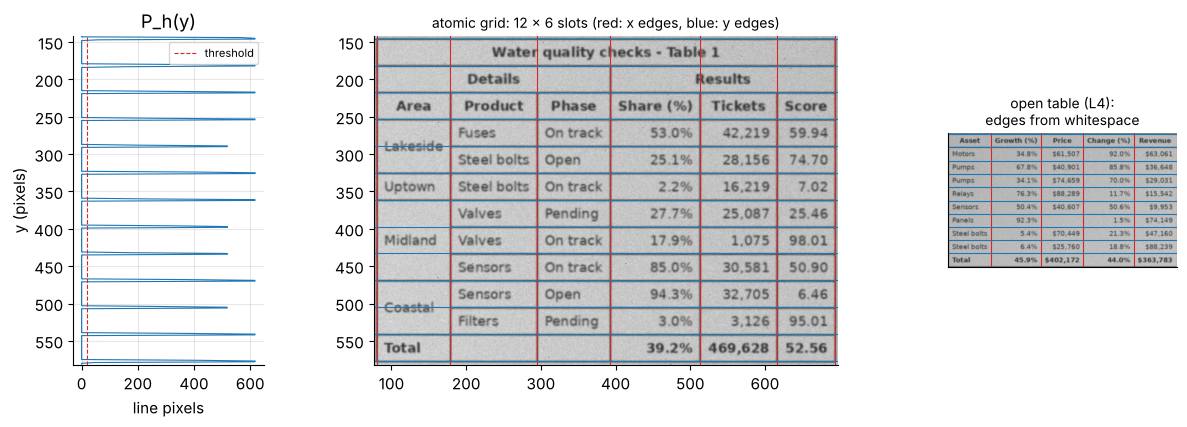

In [34]:
x0, y0, x1, y1 = tab_demo["box"]
fig, axes = plt.subplots(1, 3, figsize=(12, 4.4), gridspec_kw={"width_ratios": [1, 3, 1.2]})
axes[0].plot(ph_demo, np.arange(y0, y1), lw=0.8)
axes[0].axvline(pre_demo["h"].shape[1] / 60, color="tab:red", ls="--", lw=0.8, label="threshold")
axes[0].set(ylim=(y1, y0), title="P_h(y)", xlabel="line pixels", ylabel="y (pixels)")
axes[0].legend(fontsize=8)
axes[1].imshow(pre_demo["gray"][y0:y1, x0:x1], cmap="gray", vmin=0, vmax=255, extent=(x0, x1, y1, y0))
for x in xs_demo:
    axes[1].axvline(x, color="tab:red", lw=0.8)
for y in ys_demo:
    axes[1].axhline(y, color="tab:blue", lw=0.8)
axes[1].set_title(f"atomic grid: {len(ys_demo) - 1} x {len(xs_demo) - 1} slots (red: x edges, blue: y edges)",
                  fontsize=10)
axes[1].grid(False)
x0o, y0o, x1o, y1o = found_open[0]["box"]
axes[2].imshow(pre_open["gray"][y0o:y1o, x0o:x1o], cmap="gray", vmin=0, vmax=255, extent=(x0o, x1o, y1o, y0o))
for x in xs_open:
    axes[2].axvline(x, color="tab:red", lw=0.8)
for y in ys_open:
    axes[2].axhline(y, color="tab:blue", lw=0.8)
axes[2].set_title("open table (L4):\nedges from whitespace", fontsize=10)
axes[2].set_xticks([]), axes[2].set_yticks([]), axes[2].grid(False)
plt.tight_layout()
plt.show()

Notice in the middle panel that the grid is cut by **every** edge, including the ones that
exist only in part of the table: the boundary between the "Fuses" and "Steel bolts" rows is drawn
under every column except "Area", where "Lakeside" covers both rows. The atomic grid deliberately over-segments. Finding
out which slots belong together is the job of the next section.

> **Common pitfall.** Using an absolute threshold such as "at least 300 line pixels per row".
> It works for wide tables and silently misses every row boundary of a narrow table, or of a
> boundary interrupted by merged cells. Thresholds tied to the *stencil length* (which is the
> shortest piece that can survive the opening) cannot be fooled this way.

## 7. Logical cells: inferring merges

### 7.1 Does a boundary really exist? Line coverage

Every pair of neighboring slots is separated by a short **boundary segment**: for slots $(r, c)$
and $(r, c+1)$ it is the vertical segment at $x = x_{c+1}$ from $y_r$ to $y_{r+1}$, and for $(r, c)$ and
$(r+1, c)$ it is the horizontal segment at $y = y_{r+1}$ from $x_c$ to $x_{c+1}$. If the two slots
belong to the same merged cell, that segment was never drawn.

We measure the **coverage** of a segment: walk along its middle part (we skip 20% at each end,
where the perpendicular lines cross and would fake some coverage) and count the fraction of
positions where the matching line mask has a pixel within $\pm 3$ pixels of the expected line:

$$
\text{cov} = \frac{1}{|S|} \sum_{s \in S} \mathbb{1}\Big[\max_{|d| \le 3} \text{mask}(s, \text{pos} + d) > 0\Big],
$$

where $S$ is the set of positions along the inner 60% of the segment. A drawn line gives a
coverage near 1, a missing one near 0. The threshold is generous: **cov < 0.20 means "no line"**.
A real line has to lose more than 80% of its pixels to noise before we would wrongly merge.

### 7.2 Grouping slots: union–find

Turning "these pairs of slots have no line between them" into "these are the logical cells" is
a **connected components** problem on a graph whose nodes are slots and whose edges are missing
boundaries. The ideal data structure is **union–find** (a disjoint-set forest):

* every slot starts as its own set, and each set is a tree whose root is the set's representative.
* `find(i)` follows parent pointers to the root. With **path compression**, every node visited
  is re-pointed directly at the root, so later finds are fast.
* `union(i, j)` links the root of the smaller tree under the root of the larger (**union by
  size**), which keeps trees shallow.

With both tricks, any sequence of $m$ operations on $n$ elements costs $O(m\,\alpha(n))$, where
$\alpha$ is the inverse Ackermann function, at most 4 for any $n$ you will ever meet. For a table
with a few hundred slots this is instant, and the code is ten lines.

### 7.3 Rectangles only

A logical cell must be a rectangle. If a line is missed *partially* (say, one boundary segment
of a long rule vanished under a stain), union–find can produce an **L-shaped** component, which
no valid output can represent. Detect it with a counting argument: a set of slots with row range
$[r_0, r_1]$ and column range $[c_0, c_1]$ is a full rectangle **iff** it contains exactly
$(r_1 - r_0 + 1)(c_1 - c_0 + 1)$ slots (it cannot contain more, and any missing slot means a hole
or a notch). Non-rectangular components are split back into single slots: a missed merge costs a
little, an invalid output costs everything.

In [35]:
# ✏️ Exercise 6: count logical cells with union–find
def count_cells(n_rows: int, n_cols: int, joins: list) -> int:
    """Slots (r, c) of an n_rows x n_cols grid. `joins` lists pairs ((r1, c1), (r2, c2)) of neighboring
    slots with no line between them. Return the number of connected groups (logical cells),
    using a union–find with path compression."""
    # YOUR CODE HERE
    raise NotImplementedError

def _test():
    assert count_cells(2, 2, []) == 4, "no joins: every slot is a cell"
    assert count_cells(1, 4, [((0, 0), (0, 1)), ((0, 1), (0, 2)), ((0, 2), (0, 3))]) == 1, "a title row"
    assert count_cells(3, 2, [((0, 0), (1, 0)), ((1, 0), (2, 0))]) == 4, "a vertical merge over 3 rows"
    joins = [((0, 0), (0, 1)), ((1, 0), (1, 1)), ((0, 0), (1, 0)), ((0, 1), (1, 1))]
    assert count_cells(2, 3, joins) == 3, "a 2x2 block (with a redundant join) plus 2 single slots"
    big = [((r, c), (r, c + 1)) for r in range(30) for c in range(29)]
    assert count_cells(30, 30, big) == 30, "30 full-width rows"

run_check("Exercise 6", _test)

⏳ Exercise 6: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def count_cells(n_rows, n_cols, joins):
    parent = list(range(n_rows * n_cols))
    def find(i):
        root = i
        while parent[root] != root:
            root = parent[root]
        while parent[i] != root:              # path compression
            parent[i], i = root, parent[i]
        return root
    groups = n_rows * n_cols
    for (r1, c1), (r2, c2) in joins:
        a, b = find(r1 * n_cols + c1), find(r2 * n_cols + c2)
        if a != b:
            parent[a] = b
            groups -= 1                       # every successful union removes one group
    return groups
```
Counting is free: start with one group per slot and subtract one for every union that joins two
*different* trees. The redundant fourth join in the 2x2 block changes nothing.
</details>

In [36]:
# ✏️ Exercise 7: is a group of slots a rectangle?
def is_rectangle(slots: list) -> bool:
    """slots: list of distinct (row, col) pairs. True iff they exactly fill their bounding rectangle."""
    # YOUR CODE HERE
    raise NotImplementedError

def _test():
    assert is_rectangle([(2, 3)]) is True, "a single slot"
    assert is_rectangle([(0, 0), (0, 1), (1, 0), (1, 1)]) is True, "2x2 block"
    assert is_rectangle([(0, 0), (0, 1), (1, 0)]) is False, "L-shape"
    assert is_rectangle([(0, 0), (0, 2)]) is False, "a hole in the middle"
    assert is_rectangle([(r, 4) for r in range(5)]) is True, "vertical strip"
    assert is_rectangle([(0, 0), (1, 1)]) is False, "diagonal"

run_check("Exercise 7", _test)

⏳ Exercise 7: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def is_rectangle(slots):
    rows = [r for r, _ in slots]
    cols = [c for _, c in slots]
    area = (max(rows) - min(rows) + 1) * (max(cols) - min(cols) + 1)
    return len(set(slots)) == area
```
All slots lie inside their bounding rectangle, so the set fills it exactly when the counts agree.
</details>

### 7.4 Putting it together, plus one header rule

`infer_cells` measures the coverage of every internal boundary, unions the slots across missing
boundaries, keeps rectangular components and returns the logical cells with their pixel boxes.
It also applies the **header rule** from our exploratory analysis: if row 0 is a single cell
spanning all columns, the table has a 3-row header, otherwise a 1-row header. The pipeline needs
this number twice later: header rows are bold, and repeated header rows are dropped when a table
is stitched across pages.

In [37]:
class DisjointSets:
    """Union–find with path compression and union by size."""

    def __init__(self, n: int):
        self.parent, self.size = list(range(n)), [1] * n

    def find(self, i: int) -> int:
        root = i
        while self.parent[root] != root:
            root = self.parent[root]
        while self.parent[i] != root:
            self.parent[i], i = root, self.parent[i]
        return root

    def union(self, i: int, j: int) -> None:
        a, b = self.find(i), self.find(j)
        if a != b:
            if self.size[a] < self.size[b]:
                a, b = b, a
            self.parent[b] = a
            self.size[a] += self.size[b]


def coverage(mask: np.ndarray, start: float, end: float, pos: float, vertical: bool,
             band: int = 3, inset: float = 0.2) -> float:
    """Fraction of the inner part of a boundary segment that has line pixels within +-band of pos."""
    lo, hi = int(round(start + inset * (end - start))), int(round(end - inset * (end - start)))
    p = int(round(pos))
    if hi <= lo:
        return 1.0
    if vertical:
        strip = mask[lo:hi, max(p - band, 0):p + band + 1]
        return float((strip > 0).any(axis=1).mean())
    strip = mask[max(p - band, 0):p + band + 1, lo:hi]
    return float((strip > 0).any(axis=0).mean())


def infer_cells(pre: dict, xs: list, ys: list, thr: float = 0.20, use_merges: bool = True) -> dict:
    """Atomic grid -> logical cells via line coverage + union–find + rectangle check."""
    R, C = len(ys) - 1, len(xs) - 1
    ds = DisjointSets(R * C)
    cov_v, cov_h = np.ones((R, max(C - 1, 0))), np.ones((max(R - 1, 0), C))
    if use_merges:
        for r in range(R):
            for c in range(C - 1):
                cov_v[r, c] = coverage(pre["v"], ys[r], ys[r + 1], xs[c + 1], vertical=True)
                if cov_v[r, c] < thr:
                    ds.union(r * C + c, r * C + c + 1)
        for r in range(R - 1):
            for c in range(C):
                cov_h[r, c] = coverage(pre["h"], xs[c], xs[c + 1], ys[r + 1], vertical=False)
                if cov_h[r, c] < thr:
                    ds.union(r * C + c, (r + 1) * C + c)
    groups = defaultdict(list)
    for r in range(R):
        for c in range(C):
            groups[ds.find(r * C + c)].append((r, c))
    cells, n_split = [], 0
    for slots in groups.values():
        r0, r1 = min(r for r, _ in slots), max(r for r, _ in slots)
        c0, c1 = min(c for _, c in slots), max(c for _, c in slots)
        if len(slots) == (r1 - r0 + 1) * (c1 - c0 + 1):
            cells.append(dict(row=r0, col=c0, rowspan=r1 - r0 + 1, colspan=c1 - c0 + 1))
        else:                                        # not a rectangle: fall back to single slots
            n_split += 1
            cells += [dict(row=r, col=c, rowspan=1, colspan=1) for r, c in slots]
    for q in cells:
        q["box"] = (xs[q["col"]], ys[q["row"]], xs[q["col"] + q["colspan"]], ys[q["row"] + q["rowspan"]])
    cells.sort(key=lambda q: (q["row"], q["col"]))
    first = [q for q in cells if q["row"] == 0]
    n_header = 3 if (len(first) == 1 and first[0]["colspan"] == C and R > 3) else 1
    return dict(xs=xs, ys=ys, n_rows=R, n_cols=C, cells=cells, n_header=n_header,
                cov_v=cov_v, cov_h=cov_h, n_split=n_split)


def part_truth(table: Table, rows: list) -> set:
    """Ground-truth (row, col, rowspan, colspan) of the cells drawn in a table part (local row numbers)."""
    local = {g: i for i, g in enumerate(rows)}
    return {(local[c.row], c.col, c.rowspan, c.colspan) for c in table.cells if c.row in local}


struct_demo = infer_cells(pre_demo, xs_demo, ys_demo)
found_set = {(q["row"], q["col"], q["rowspan"], q["colspan"]) for q in struct_demo["cells"]}
true_set = part_truth(true_t, truth_demo[1]["parts"][0]["rows"])
print(f"logical cells found: {len(found_set)} | true: {len(true_set)} | identical: {found_set == true_set}")
print(f"merged cells found: {sum(rs * cs > 1 for _, _, rs, cs in found_set)} | header rows inferred: "
      f"{struct_demo['n_header']} | non-rectangular groups split: {struct_demo['n_split']}")

logical cells found: 59 | true: 59 | identical: True
merged cells found: 6 | header rows inferred: 3 | non-rectangular groups split: 0


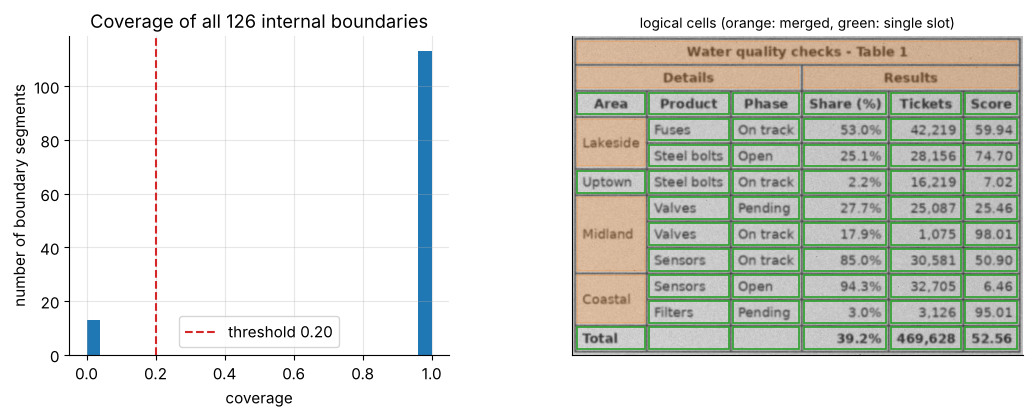

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), gridspec_kw={"width_ratios": [1, 2]})
all_cov = np.concatenate([struct_demo["cov_v"].ravel(), struct_demo["cov_h"].ravel()])
axes[0].hist(all_cov, bins=np.linspace(0, 1, 26), color="tab:blue")
axes[0].axvline(0.20, color="tab:red", ls="--", label="threshold 0.20")
axes[0].set(title=f"Coverage of all {len(all_cov)} internal boundaries", xlabel="coverage",
            ylabel="number of boundary segments")
axes[0].legend()
x0, y0, x1, y1 = tab_demo["box"]
axes[1].imshow(pre_demo["gray"][y0:y1, x0:x1], cmap="gray", vmin=0, vmax=255, extent=(x0, x1, y1, y0))
for q in struct_demo["cells"]:
    bx0, by0, bx1, by1 = q["box"]
    merged = q["rowspan"] * q["colspan"] > 1
    axes[1].add_patch(Rectangle((bx0 + 3, by0 + 3), bx1 - bx0 - 6, by1 - by0 - 6, fill=merged, alpha=0.25 if merged else 1,
                                ec="tab:orange" if merged else "tab:green", fc="tab:orange", lw=1.2))
axes[1].set_title("logical cells (orange: merged, green: single slot)", fontsize=10)
axes[1].set_xticks([]), axes[1].set_yticks([]), axes[1].grid(False)
plt.tight_layout()
plt.show()

The histogram is the best argument for the method: coverage values pile up at 0 (no line) and at
1 (line), with nothing in between, so the exact threshold hardly matters on this page. On noisier
pages the two piles spread out, and Section 13 shows the consequence: at the heavy noise level, a
few real boundaries fall below 0.20 and the cells on both sides are wrongly merged (Sections 13.3
and 13.5).

**Quick check.** A 3-row header has a title spanning 6 columns in row 0 and two group cells
spanning columns 0–2 and 3–5 in row 1. How many internal *vertical* boundary segments do rows 0–1
have, and how many of them have coverage near 0?

<details><summary>Answer</summary>

Each row of a 6-column grid has 5 internal vertical segments, so rows 0–1 have 10. Row 0 is one
cell, so all 5 are missing. Row 1 has a line only between columns 2 and 3, so 4 are missing.
That makes 9 segments near 0 and 1 near 1.
</details>

## 8. Reading the cells

Structure is done. Now the content. Because every cell already has a box, reading becomes a set
of small, independent problems: "what is written in this rectangle?"

### 8.1 Crops and text bands

* **Inset crop.** We shrink each cell box by a few pixels before reading it. Ruling-line remnants
  at the crop border are the most common source of OCR garbage: a vertical line at the edge of a
  crop is happily read as `|`, `l` or `1`.
* **Band splitting.** OCR engines are most reliable on *one line of text at a time*. A multi-line
  cell is split with the same tool as the grid: the horizontal projection profile of the text ink
  inside the crop has one block of nonzero rows per text line, separated by empty rows. Each run
  becomes a **band** (we drop runs shorter than 4 pixels, which are specks, and pad each band by 3
  pixels). The number of bands is also the number of `<br>`-separated lines in the output.

### 8.2 Two readers

* The **oracle reader** cheats on purpose: it looks up the ground-truth text lines whose centers
  fall inside each detected cell box (after moving them through the scan and deskew rotations).
  It never misreads a character, so any error that remains with the oracle is a **structure**
  error. This is the standard trick for evaluating a pipeline stage by stage: replace one stage
  by its perfect version and see how much the final score improves.
* The **Tesseract reader** uses the open-source Tesseract engine through `pytesseract`. Tesseract
  is a separate program, not a Python package: on Colab install it with
  `apt-get install -y tesseract-ocr` (the next cell does this automatically when it detects
  Colab), and on a laptop use your package manager. If the program is missing, the notebook skips the
  Tesseract experiments and says so.

Calling Tesseract once per band is simple but slow, because every call starts a new process
(roughly 0.1–0.2 s each, so a 70-cell page would take over 10 seconds). We therefore **batch**: all
bands of a page are upscaled $2\times$ (Tesseract prefers capital letters about 20–30 pixels tall),
padded and stacked into one tall **mosaic** image with generous white gaps, read in a single call
with page segmentation mode 6 ("a uniform block of text"), and every recognized word is assigned
back to the band whose vertical slot contains the word's center.

In [39]:
def setup_tesseract() -> bool:
    """Make Tesseract available if possible (installs it on Colab) and return True if it can be used."""
    if shutil.which("tesseract") is None and "google.colab" in sys.modules:
        subprocess.run(["apt-get", "install", "-y", "-qq", "tesseract-ocr"], check=False,
                       stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    if shutil.which("tesseract") is None:
        return False
    try:
        ensure("pytesseract")
        return True
    except Exception:                        # no network to install the Python wrapper
        return False


TESSERACT_OK = setup_tesseract()
if TESSERACT_OK:
    import pytesseract
    print("Tesseract", pytesseract.get_tesseract_version(), "is available.")
else:
    print("Tesseract is NOT available: OCR experiments will use the oracle reader only.")


def cell_bands(pre: dict, box: tuple, inset: int = 4, pad: int = 3) -> list:
    """Split the inset crop of a cell into text bands. Returns [(x0, y0, x1, y1), ...] in page coordinates."""
    x0, y0, x1, y1 = (int(round(v)) for v in box)
    x0, y0, x1, y1 = x0 + inset, y0 + inset, x1 - inset, y1 - inset
    if x1 - x0 < 4 or y1 - y0 < 4:
        return []
    text = text_mask(pre, (x0, y0, x1, y1)) > 0
    bands = []
    for a, b in find_runs(text.sum(axis=1) > 0, max_gap=1):
        if b - a + 1 < 4:
            continue
        cols = np.flatnonzero(text[a:b + 1].any(axis=0))
        bands.append((x0 + max(cols[0] - pad, 0), y0 + max(a - pad, 0),
                      x0 + min(cols[-1] + pad + 1, x1 - x0), y0 + min(b + pad + 1, y1 - y0)))
    return bands


def make_oracle(truth: list, scan_matrices: list):
    """Reader that returns the true text lines whose centers fall inside each cell box."""
    def read(page: int, pre: dict, boxes: list) -> list:
        A = compose(pre["D"], scan_matrices[page])
        words = [w for w in truth[page]["words"] if w["kind"] == "cell"]
        cx, cy = apply_affine(A, [w["cx"] for w in words], [w["cy"] for w in words])
        out = []
        for x0, y0, x1, y1 in boxes:
            inside = np.flatnonzero((cx > x0) & (cx < x1) & (cy > y0) & (cy < y1))
            out.append([words[i]["text"] for i in sorted(inside, key=lambda i: (cy[i], cx[i]))])
        return out
    return read

Tesseract 5.3.4 is available.


In [40]:
def clean_ocr(s: str) -> str:
    """Collapse whitespace and strip characters that ruling-line remnants typically produce at the ends."""
    return re.sub(r"\s+", " ", s).strip().strip("|_[]{} ").strip()


def normalize_band(img: np.ndarray) -> np.ndarray:
    """Stretch a gray crop so the paper becomes white and the ink black (robust percentiles)."""
    lo, hi = np.percentile(img, [2, 95])
    return np.clip((img.astype(np.float32) - lo) * 255.0 / max(hi - lo, 1.0), 0, 255).astype(np.uint8)


OCR_CHARS = "ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz0123456789.,:;%$()/|-"


def make_tesseract_reader(scale: float = 2.0, gap: int = 24, pad: int = 20, max_bands: int = 60):
    """Reader that OCRs all text bands of a page with a few batched Tesseract calls (mosaics).

    The character whitelist restricts the output to the characters our documents can contain. It
    must include the space (hence the quotes), otherwise Tesseract glues all words together.
    """
    config = f'--psm 6 -c "tessedit_char_whitelist={OCR_CHARS} "'

    def read(page: int, pre: dict, boxes: list) -> list:
        bands = [cell_bands(pre, b) for b in boxes]
        flat = [(i, j, bb) for i, bb_list in enumerate(bands) for j, bb in enumerate(bb_list)]
        texts = {}
        for start in range(0, len(flat), max_bands):
            chunk = flat[start:start + max_bands]
            ims = [cv2.resize(normalize_band(pre["gray"][y0:y1, x0:x1]), None, fx=scale, fy=scale,
                              interpolation=cv2.INTER_CUBIC) for _, _, (x0, y0, x1, y1) in chunk]
            canvas = np.full((sum(im.shape[0] for im in ims) + gap * (len(ims) - 1) + 2 * pad,
                              max(im.shape[1] for im in ims) + 2 * pad), 255, np.uint8)
            slots, y = [], pad
            for im in ims:
                canvas[y:y + im.shape[0], pad:pad + im.shape[1]] = im
                slots.append((y - gap / 2, y + im.shape[0] + gap / 2))
                y += im.shape[0] + gap
            data = pytesseract.image_to_data(canvas, config=config, output_type=pytesseract.Output.DICT)
            words = defaultdict(list)
            for k, word in enumerate(data["text"]):
                if word.strip():
                    center = data["top"][k] + data["height"][k] / 2
                    m = next((m for m, (a, b) in enumerate(slots) if a <= center < b), None)
                    if m is not None:
                        words[m].append((data["left"][k], word))
            for m, (i, j, _) in enumerate(chunk):
                texts[(i, j)] = clean_ocr(" ".join(w for _, w in sorted(words[m])))
        return [[texts[(i, j)] for j in range(len(b)) if texts.get((i, j))] for i, b in enumerate(bands)]
    return read


def levenshtein(a: str, b: str) -> int:
    """Edit distance (insertions, deletions, substitutions all cost 1), O(len(a) * len(b))."""
    if len(a) < len(b):
        a, b = b, a
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (ca != cb)))
        prev = cur
    return prev[-1]


boxes_demo = [q["box"] for q in struct_demo["cells"]]
oracle_demo = make_oracle(truth_demo, [M for _, M in scans_demo])
t0 = time.time()
lines_oracle = oracle_demo(1, pre_demo, boxes_demo)
t_oracle = time.time() - t0
true_lines = {}
rows_p2 = truth_demo[1]["parts"][0]["rows"]
for c in true_t.cells:
    if c.row in rows_p2:
        true_lines[(rows_p2.index(c.row), c.col)] = c.lines
gt_demo = [true_lines[(q["row"], q["col"])] for q in struct_demo["cells"]]
print(f"oracle: {sum(a == b for a, b in zip(lines_oracle, gt_demo))}/{len(gt_demo)} cells exact "
      f"({t_oracle * 1000:.0f} ms)")
if TESSERACT_OK:
    t0 = time.time()
    lines_tess = make_tesseract_reader()(1, pre_demo, boxes_demo)
    t_tess = time.time() - t0
    exact = sum(a == b for a, b in zip(lines_tess, gt_demo))
    chars = sum(len("\n".join(b)) for b in gt_demo)
    errors = sum(levenshtein("\n".join(a), "\n".join(b)) for a, b in zip(lines_tess, gt_demo))
    print(f"Tesseract: {exact}/{len(gt_demo)} cells exact, character error rate {errors / chars:.2%} "
          f"({t_tess:.1f} s for the page)")
    wrong = [(" / ".join(b), " / ".join(a)) for a, b in zip(lines_tess, gt_demo) if a != b]
    display(pd.DataFrame(wrong[:8], columns=["truth", "Tesseract"]))

oracle: 59/59 cells exact (1 ms)


Tesseract: 58/59 cells exact, character error rate 0.27% (2.1 s for the page)


,truth,Tesseract
0,Valves,Vaives


On this medium-quality scan Tesseract reads almost every cell exactly. What remains are classic
confusions between similar-looking glyphs, such as `l` read as `i`.

The **character error rate** (CER) printed above counts reading mistakes per true character:

$$
\text{CER} = \frac{\sum_{\text{cells}} \text{lev}(\hat s, s)}{\sum_{\text{cells}} |s|},
$$

where $s$ is the true text of a cell (line breaks included), $\hat s$ the text that was read and
$|s|$ the number of characters of $s$. The **Levenshtein distance** $\text{lev}(a, b)$ is the
minimum number of single-character insertions, deletions and substitutions that turn $a$ into
$b$. The function `levenshtein` computes it by dynamic programming: if $D_{i,j}$ is the distance
between the first $i$ characters of $a$ and the first $j$ characters of $b$, then
$D_{i,0} = i$, $D_{0,j} = j$ and

$$
D_{i,j} = \min\big(D_{i-1,j} + 1,\; D_{i,j-1} + 1,\; D_{i-1,j-1} + [a_i \ne b_j]\big),
$$

where the three options delete $a_i$, insert $b_j$, or substitute (or keep) a character, and
$[a_i \ne b_j]$ is 1 if the two characters differ and 0 otherwise. Here the only error is one
substitution (`Vaives` for `Valves`, so $\text{lev} = 1$) among roughly 370 true characters,
giving CER $\approx 1/370 \approx 0.27\%$. Because CER divides by the *true* length, it can exceed
100% when a reader invents text.

Two details made a large difference while building this reader: the **character whitelist**
(our documents only contain ASCII letters, digits and a little punctuation, so forbidding
everything else removes accented look-alikes and `!` for `l`) and the **contrast normalization**
of each band before upscaling.

Here is band splitting at work on a two-line cell of another document (level L2, scanned at the
medium level), with each band read separately by Tesseract in single-line mode (`--psm 7`, one call
per band, which is fine for a demonstration but too slow for whole pages).

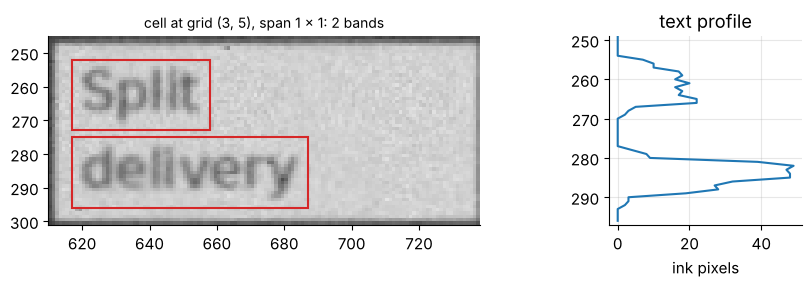

band -> Tesseract --psm 7: 'Split'
band -> Tesseract --psm 7: 'delivery'
oracle lines: ['Split', 'delivery']


In [41]:
doc_ml = make_document("L2", 20)
pages_ml, truth_ml = render_document(doc_ml)
scan_ml, M_ml = scan(pages_ml[0], np.random.default_rng(20), "medium")
pre_p1 = preprocess(scan_ml)
tab_p1 = find_tables(pre_p1["h"], pre_p1["v"])[0]
struct_p1 = infer_cells(pre_p1, *ruled_grid(pre_p1, tab_p1["box"])[:2])
lines_p1 = make_oracle(truth_ml, [M_ml])(0, pre_p1, [q["box"] for q in struct_p1["cells"]])
k_multi = next(k for k, ln in enumerate(lines_p1) if len(ln) > 1 and struct_p1["cells"][k]["row"] >= 3)
q = struct_p1["cells"][k_multi]
bx0, by0, bx1, by1 = (int(round(v)) for v in q["box"])
bands_demo = cell_bands(pre_p1, q["box"])
crop_text = text_mask(pre_p1, (bx0 + 4, by0 + 4, bx1 - 4, by1 - 4)) > 0
fig, axes = plt.subplots(1, 2, figsize=(9, 3), gridspec_kw={"width_ratios": [3, 1]})
axes[0].imshow(pre_p1["gray"][by0:by1, bx0:bx1], cmap="gray", vmin=0, vmax=255, extent=(bx0, bx1, by1, by0))
for x0b, y0b, x1b, y1b in bands_demo:
    axes[0].add_patch(Rectangle((x0b, y0b), x1b - x0b, y1b - y0b, fill=False, ec="tab:red", lw=1.5))
axes[0].set_title(f"cell at grid ({q['row']}, {q['col']}), span {q['rowspan']} x {q['colspan']}: "
                  f"{len(bands_demo)} bands", fontsize=10)
axes[0].grid(False)
axes[1].plot(crop_text.sum(axis=1), np.arange(by0 + 4, by1 - 4))
axes[1].set(ylim=(by1 - 4, by0 + 4), title="text profile", xlabel="ink pixels")
plt.tight_layout()
plt.show()
if TESSERACT_OK:
    for x0b, y0b, x1b, y1b in bands_demo:
        band = cv2.resize(normalize_band(pre_p1["gray"][y0b:y1b, x0b:x1b]), None, fx=2, fy=2,
                          interpolation=cv2.INTER_CUBIC)
        band = cv2.copyMakeBorder(band, 12, 12, 12, 12, cv2.BORDER_CONSTANT, value=255)
        print("band -> Tesseract --psm 7:", repr(clean_ocr(pytesseract.image_to_string(band, config="--psm 7"))))
print("oracle lines:", lines_p1[k_multi])

### 8.3 Going deeper: a tiny reader for numbers, from scratch

What happens *inside* an OCR engine? The classical recipe has four steps, and we can build a
miniature version for the numeric cells of our tables (characters `0-9 . , % $ -`):

1. **Binarize the band** on its own: normalize its contrast, upscale it $2\times$ (a period is only
   2 pixels wide at our resolution) and apply Otsu, since a band is small enough for a global threshold.
2. **Segment into glyphs** with connected components. Some characters have several pieces (the two
   circles and the bar of `%`), so pieces that overlap horizontally by at least half of the narrower
   one are grouped. A blob much wider than a digit (two touching digits) is cut at the column with
   the least ink: the *projection valley*.
3. **Describe each glyph** by its shape (the crop padded to a square and shrunk to $12 \times 12$, so
   144 numbers) plus three geometric numbers relative to the line: height, width and vertical
   offset of its center, all divided by the typical character height of the band. The geometric
   numbers separate glyphs whose *shapes* are similar but whose *size and position* differ: a
   period sits on the baseline and is tiny, a hyphen floats in the middle, a comma has a tail.
4. **Classify** each glyph with a $k$-nearest-neighbor vote ($k = 3$) among labeled training glyphs,
   and insert a space where the gap between two glyphs is large.

Where do labeled glyphs come from? From the same trick as the whole notebook: **synthesis**. We
render random numeric strings, degrade them like a scanner, run *the same segmentation code*, and
keep the strings whose glyph count equals their character count, so the $i$-th glyph is the
$i$-th character. Training on glyphs produced by the very code that will see the test glyphs
removes a whole class of train/test mismatches.

In [42]:
NUM_CHARS = "0123456789.,%$-"


def band_ink(gray_band: np.ndarray) -> np.ndarray:
    """Gray band -> binary ink mask at 2x scale (contrast normalization, cubic upscaling, Otsu)."""
    up = cv2.resize(normalize_band(gray_band), None, fx=2, fy=2, interpolation=cv2.INTER_CUBIC)
    return cv2.threshold(up, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)[1]


def glyph_boxes(mask: np.ndarray, min_area: int = 6) -> list:
    """Connected components -> glyph boxes (pieces grouped by x-overlap, wide blobs split at the valley)."""
    n, _, stats, _ = cv2.connectedComponentsWithStats((mask > 0).astype(np.uint8), connectivity=8)
    comps = sorted((int(x), int(y), int(x + w), int(y + h)) for x, y, w, h, a in stats[1:] if a >= min_area)
    groups = []
    for b in comps:
        if groups:
            a = groups[-1]
            if min(a[2], b[2]) - max(a[0], b[0]) >= 0.5 * min(a[2] - a[0], b[2] - b[0]):
                groups[-1] = (min(a[0], b[0]), min(a[1], b[1]), max(a[2], b[2]), max(a[3], b[3]))
                continue
        groups.append(b)
    if not groups:
        return []
    tallest = max(b[3] - b[1] for b in groups)
    width = float(np.median([b[2] - b[0] for b in groups if b[3] - b[1] >= 0.7 * tallest]))
    out, stack = [], groups[::-1]
    while stack:
        x0, y0, x1, y1 = stack.pop()
        if x1 - x0 > 1.8 * width and x1 - x0 >= 6:            # two touching glyphs: cut at the valley
            prof = (mask[y0:y1, x0:x1] > 0).sum(axis=0)
            lo, hi = int(0.25 * (x1 - x0)), int(0.75 * (x1 - x0))
            cut = x0 + lo + int(np.argmin(prof[lo:hi]))
            stack += [(cut, y0, x1, y1), (x0, y0, cut, y1)]
        else:
            out.append((x0, y0, x1, y1))
    return out


def glyph_vectors(mask: np.ndarray, boxes: list) -> np.ndarray:
    """Shape (12x12, aspect preserved) + 3 geometric features relative to the band's character height."""
    hs = np.array([b[3] - b[1] for b in boxes], float)
    ref_h = float(np.median(hs[hs >= 0.7 * hs.max()]))
    mid_y = float(np.median([(b[1] + b[3]) / 2 for b in boxes if b[3] - b[1] >= 0.7 * ref_h]))
    feats = []
    for x0, y0, x1, y1 in boxes:
        crop = (mask[y0:y1, x0:x1] > 0).astype(np.float32)
        h, w = crop.shape
        side = max(h, w)
        sq = np.zeros((side, side), np.float32)
        sq[(side - h) // 2:(side - h) // 2 + h, (side - w) // 2:(side - w) // 2 + w] = crop
        shape = cv2.resize(sq, (12, 12), interpolation=cv2.INTER_AREA).ravel()
        geo = 3.0 * np.array([h / ref_h, w / ref_h, ((y0 + y1) / 2 - mid_y) / ref_h])
        feats.append(np.concatenate([shape, geo]))
    return np.array(feats)


def numeric_string(rng) -> str:
    kind = str(rng.choice(["int", "money", "pct", "dec", "date"]))
    return gen_value(kind, rng)[0] if kind != "date" else \
        f"2025-{int(rng.integers(1, 13)):02d}-{int(rng.integers(1, 29)):02d}"


def synthetic_band(text: str, rng) -> np.ndarray:
    """Render one line of text with a random size/weight and scanner-like degradation (gray image)."""
    size, bold = int(rng.integers(12, 20)), bool(rng.random() < 0.3)
    font = get_font(size, bold)
    img = Image.new("L", (int(font.getlength(text)) + 16, int(size * 1.6) + 6), 255)
    ImageDraw.Draw(img).text((8, 3), text, font=font, fill=INK)
    lo, hi = rng.uniform(20, 70), rng.uniform(200, 245)
    a = cv2.GaussianBlur(lo + (hi - lo) * np.array(img, np.float32) / 255, (0, 0), rng.uniform(0.3, 1.0))
    return np.clip(a + rng.normal(0, rng.uniform(2, 10), a.shape), 0, 255).astype(np.uint8)


class TinyNumberReader:
    """k-nearest-neighbor glyph classifier trained on synthetic, self-segmented numeric strings."""

    def __init__(self, n_strings: int = 800, k: int = 3, seed: int = 0):
        rng, X, y = np.random.default_rng(seed), [], []
        for _ in range(n_strings):
            text = numeric_string(rng)
            mask = band_ink(synthetic_band(text, rng))
            boxes = glyph_boxes(mask)
            if len(boxes) == len(text):                    # keep only cleanly segmented strings
                X.append(glyph_vectors(mask, boxes))
                y += list(text)
        self.X, self.y, self.k = np.vstack(X), np.array(y), k
        self.sq = (self.X ** 2).sum(axis=1)

    def classify(self, F: np.ndarray) -> list:
        d = (F ** 2).sum(axis=1)[:, None] + self.sq[None, :] - 2.0 * F @ self.X.T   # squared distances
        votes = self.y[np.argsort(d, axis=1)[:, :self.k]]
        return [Counter(v).most_common(1)[0][0] for v in votes]

    def read(self, gray_band: np.ndarray) -> str:
        mask = band_ink(gray_band)
        boxes = glyph_boxes(mask)
        if not boxes:
            return ""
        chars = self.classify(glyph_vectors(mask, boxes))
        h = np.median([b[3] - b[1] for b in boxes])
        return chars[0] + "".join((" " if b[0] - a[2] > 0.45 * h else "") + c
                                  for a, b, c in zip(boxes[:-1], boxes[1:], chars[1:]))


t0 = time.time()
tiny = TinyNumberReader()
print(f"trained on {len(tiny.y)} glyphs in {time.time() - t0:.1f} s")
held = np.random.default_rng(1)
tests = [numeric_string(held) for _ in range(200)]
reads = [tiny.read(synthetic_band(t, held)) for t in tests]
print(f"held-out synthetic numbers read exactly: {np.mean([a == b for a, b in zip(reads, tests)]):.1%}")
print("some mistakes (truth -> read):", [(t, r) for t, r in zip(tests, reads) if t != r][:6])

trained on 4290 glyphs in 0.9 s


held-out synthetic numbers read exactly: 82.0%
some mistakes (truth -> read): [('94.6%', '%%'), ('2025-12-07', '202%1247'), ('2025-04-16', '202544-16'), ('77.4%', '774%'), ('2025-06-11', '2025-0611'), ('15.1%', '15.13$')]


Now the real test: the numeric cells of the scanned demo page from Section 8.2, read band by band
with the tiny reader and compared with Tesseract's output on the same cells.

27 numeric cells | tiny reader exact: 26 | Tesseract exact: 27


,truth,tiny reader,Tesseract
12,17.9%,"17,9%",17.9%


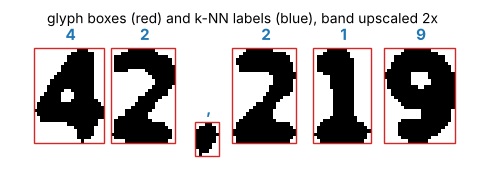

In [43]:
num_rows = []
for q, gt, k in zip(struct_demo["cells"], gt_demo, range(len(gt_demo))):
    if len(gt) != 1 or not gt[0] or any(ch not in NUM_CHARS for ch in gt[0]):
        continue
    x0, y0, x1, y1 = cell_bands(pre_demo, q["box"])[0]
    num_rows.append({"truth": gt[0], "tiny reader": tiny.read(pre_demo["gray"][y0:y1, x0:x1]),
                     "Tesseract": " ".join(lines_tess[k]) if TESSERACT_OK else "n/a"})
num_df = pd.DataFrame(num_rows)
print(f"{len(num_df)} numeric cells | tiny reader exact: {(num_df['tiny reader'] == num_df.truth).sum()} | "
      f"Tesseract exact: {(num_df['Tesseract'] == num_df.truth).sum()}")
display(num_df[num_df["tiny reader"] != num_df.truth])

x0, y0, x1, y1 = cell_bands(pre_demo, next(q["box"] for q, gt in zip(struct_demo["cells"], gt_demo)
                                           if gt and "," in gt[0] and gt[0][0].isdigit()))[0]
mask_demo = band_ink(pre_demo["gray"][y0:y1, x0:x1])
boxes_demo_g = glyph_boxes(mask_demo)
chars_demo = tiny.classify(glyph_vectors(mask_demo, boxes_demo_g))
fig, ax = plt.subplots(figsize=(6, 2))
ax.imshow(255 - mask_demo, cmap="gray")
for (bx0, by0, bx1, by1), ch in zip(boxes_demo_g, chars_demo):
    ax.add_patch(Rectangle((bx0 - 0.5, by0 - 0.5), bx1 - bx0, by1 - by0, fill=False, ec="tab:red", lw=1))
    ax.text((bx0 + bx1) / 2, by0 - 3, ch, color="tab:blue", ha="center", fontsize=11, weight="bold")
ax.set_title("glyph boxes (red) and k-NN labels (blue), band upscaled 2x", fontsize=10)
ax.set_xticks([]), ax.set_yticks([]), ax.grid(False)
for spine in ax.spines.values():
    spine.set_visible(False)
plt.show()

The miniature reader gets almost every numeric cell of the real page right. Its one slip there
confuses two tiny blobs (a period read as a comma). On the harder synthetic strings (smaller fonts,
more blur) the printed mistakes are instructive: nearly all of them are **segmentation** errors,
not classification errors: a period or hyphen lost or glued to a neighbor, a `%` cut in two,
several glyphs fused into one blob. Once the boxes are wrong, no classifier can recover. Letters
would add further problems (`l`, `I` and `|` are nearly identical strokes in many fonts, and `o` and
`O` differ only in size).

This is exactly why modern engines stopped segmenting. Since version 4, Tesseract reads a whole
text line with a recurrent neural network (an LSTM) that outputs a sequence of character
probabilities, trained with the **CTC loss**, which marginalizes over all possible alignments
between image columns and characters. No explicit glyph boxes are ever needed, and the network can
use context (a digit between two digits is more likely than a letter). Our pipeline still *uses*
the classical ideas (bands, crops, normalization), but leaves the reading of each band to the
learned model.

## 9. Bold detection

### 9.1 Bold means thicker strokes

A bold font draws the same letters with **thicker strokes**. At our resolution a regular stroke is
about 2 pixels wide and a bold one about 3–4, so we need a measurement that is sensitive to a
one-pixel difference. Two classic ones, both computed on the text mask of a cell (ink without
ruling lines and specks):

* **Erosion survival ratio.** Erode the mask once with a $3 \times 3$ square and measure the
  fraction of ink pixels that survive:

$$
E = \frac{|\text{erode}(T)|}{|T|} .
$$

  A pixel survives only if its whole $3 \times 3$ neighborhood is ink, i.e. if it lies at least
  2 pixels deep inside a stroke. Strokes 2 pixels wide vanish completely, and strokes 4 pixels wide keep
  their core. So $E$ is near 0 for thin text and grows quickly with stroke width.
* **Distance-transform stroke width.** The distance transform assigns every ink pixel its
  (Euclidean) distance to the nearest background pixel. Along the middle of a stroke (the
  **ridge**, where the distance is a local maximum), that distance is half the stroke width, so

$$
w = 2 \cdot \operatorname{median}\{\, \text{DT}(p) : p \text{ on the ridge} \,\}
$$

  estimates the stroke width directly, in pixels. The median makes it robust to the junctions of
  letters, where the ridge is locally deeper.

Both numbers depend on the font size, the blur and the binarization, which change from page to
page. That is why the **calibration** idea from Section 3.8 matters: in every table, the header
rows are known to be bold and the body rows known to be (almost always) regular, so each table
carries its own labeled reference samples.

In [44]:
def stroke_scores(text: np.ndarray) -> tuple:
    """(erosion survival ratio, distance-transform stroke width) of a binary text mask, NaN if too little ink."""
    ink = (text > 0).astype(np.uint8)
    n = int(ink.sum())
    if n < 15:
        return np.nan, np.nan
    survive = cv2.erode(ink, np.ones((3, 3), np.uint8)).sum() / n
    dt = cv2.distanceTransform(ink, cv2.DIST_L2, cv2.DIST_MASK_PRECISE)   # exact Euclidean distances
    ridge = (dt >= cv2.dilate(dt, np.ones((3, 3), np.uint8))) & (ink > 0)
    return float(survive), 2.0 * float(np.median(dt[ridge]))


def cell_scores(pre: dict, cells: list, inset: int = 4) -> np.ndarray:
    """Stroke scores of every detected cell: array of shape (n_cells, 2)."""
    out = []
    for q in cells:
        x0, y0, x1, y1 = (int(round(v)) for v in q["box"])
        if x1 - x0 <= 2 * inset + 4 or y1 - y0 <= 2 * inset + 4:
            out.append((np.nan, np.nan))
            continue
        out.append(stroke_scores(text_mask(pre, (x0 + inset, y0 + inset, x1 - inset, y1 - inset))))
    return np.array(out)


def true_bold_flags(truth_page: dict, A: np.ndarray, boxes: list) -> list:
    """Ground truth for detected cells: True/False if the box contains bold/regular text, None if empty."""
    words = [w for w in truth_page["words"] if w["kind"] == "cell"]
    cx, cy = apply_affine(A, [w["cx"] for w in words], [w["cy"] for w in words])
    flags = []
    for x0, y0, x1, y1 in boxes:
        inside = [words[i]["bold"] for i in np.flatnonzero((cx > x0) & (cx < x1) & (cy > y0) & (cy < y1))]
        flags.append(None if not inside else bool(np.mean(inside) >= 0.5))
    return flags


bold_rows = []
for lvl, seed, severity in [("L1", 3, "light"), ("L2", 20, "medium"), ("L3", 3, "medium"),
                            ("L2", 11, "heavy"), ("L4", 6, "light"), ("L3", 25, "heavy")]:
    d = make_document(lvl, seed)
    pg, tr = render_document(d)
    img, M = scan(pg[0], np.random.default_rng(seed), severity)
    pre = preprocess(img)
    for t_idx, tab in enumerate(find_tables(pre["h"], pre["v"])):
        xs, ys = ruled_grid(pre, tab["box"])[:2] if tab["kind"] == "grid" else open_grid(pre, tab)
        st = infer_cells(pre, xs, ys, use_merges=tab["kind"] == "grid")
        scores = cell_scores(pre, st["cells"])
        flags = true_bold_flags(tr[0], compose(pre["D"], M), [q["box"] for q in st["cells"]])
        for q, (e, w), b in zip(st["cells"], scores, flags):
            if b is not None and not np.isnan(e):
                bold_rows.append(dict(doc=f"{lvl}-{seed}", severity=severity, table=t_idx, row=q["row"],
                                      n_rows=st["n_rows"], n_header=st["n_header"], bold=b, erosion=e, width=w))
bold_df = pd.DataFrame(bold_rows)
print(f"{len(bold_df)} non-empty cells, {int(bold_df.bold.sum())} of them bold")
display(bold_df.groupby(["severity", "bold"])[["erosion", "width"]].median().round(3))

450 non-empty cells, 84 of them bold


erosion  width
severity bold                 
heavy    False    0.098  2.000
         True     0.358  4.000
light    False    0.134  2.828
         True     0.322  4.000
medium   False    0.142  2.828
         True     0.379  4.000

### 9.2 How well do the two scores separate bold from regular?

A threshold-free way to compare two scores is the **AUC** (area under the ROC curve), which has
a beautifully simple meaning: the probability that a randomly chosen bold cell scores higher than
a randomly chosen regular cell (ties count one half),

$$
\text{AUC} = \frac{1}{n_+ n_-} \sum_{i \in \text{bold}} \sum_{j \in \text{regular}}
\Big(\mathbb{1}[s_i > s_j] + \tfrac12 \mathbb{1}[s_i = s_j]\Big).
$$

AUC = 1 means some threshold separates the classes perfectly, 0.5 means the score is useless.

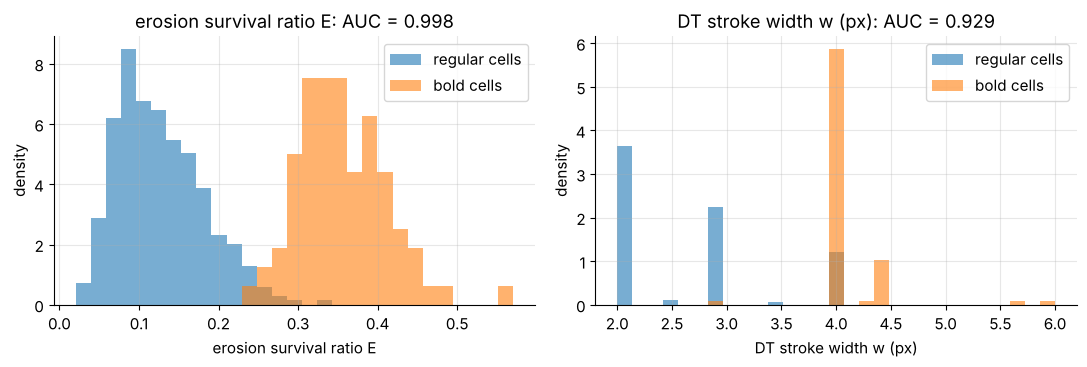

heavy   AUC erosion 1.000 | AUC width 0.993
light   AUC erosion 0.998 | AUC width 0.794
medium  AUC erosion 0.997 | AUC width 0.921


In [45]:
def auc(pos: np.ndarray, neg: np.ndarray) -> float:
    """P(random positive > random negative), ties counted 1/2 (the Mann–Whitney form of the ROC AUC)."""
    pos, neg = np.asarray(pos)[:, None], np.asarray(neg)[None, :]
    return float((pos > neg).mean() + 0.5 * (pos == neg).mean())


fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, col, label in [(axes[0], "erosion", "erosion survival ratio E"), (axes[1], "width", "DT stroke width w (px)")]:
    pos, neg = bold_df.loc[bold_df.bold, col], bold_df.loc[~bold_df.bold, col]
    bins = np.linspace(bold_df[col].min(), bold_df[col].max(), 30)
    ax.hist(neg, bins=bins, alpha=0.6, label="regular cells", density=True)
    ax.hist(pos, bins=bins, alpha=0.6, label="bold cells", density=True)
    ax.set(title=f"{label}: AUC = {auc(pos, neg):.3f}", xlabel=label, ylabel="density")
    ax.legend()
plt.tight_layout()
plt.show()
for sev, grp in bold_df.groupby("severity"):
    print(f"{sev:7s} AUC erosion {auc(grp.erosion[grp.bold], grp.erosion[~grp.bold]):.3f} | "
          f"AUC width {auc(grp.width[grp.bold], grp.width[~grp.bold]):.3f}")

The erosion ratio wins clearly. The distance-transform width suffers from **quantization**: on a
pixel grid the ridge distances take only a few values ($1, \sqrt2, 2, \sqrt5, \dots$), so the
median jumps between a handful of levels, and two strokes 2.4 and 2.6 pixels wide can get the same
score. The erosion ratio averages over *all* ink pixels of the cell and varies smoothly.

### 9.3 From scores to decisions: calibrate per table

We compare three decision rules on the cells above:

1. **Global threshold**: one cut-off for all pages. To make it as strong as possible we cheat
   and choose it *on these very cells* (the best accuracy any single threshold can reach here).
2. **Per-table calibration**: in each table, $\tau = \tfrac12\big(\operatorname{median}E_{\text{header}}
   + \operatorname{median}E_{\text{body}}\big)$, and a cell is bold if $E > \tau$. No training data at all.
3. **Bold grammar**: header rows are bold, body rows are regular, and the **last row** is bold
   iff the median $E$ of its cells exceeds $\tau$ (a whole-row vote is much more reliable than a
   single cell). This uses the regularities of Section 3.8 and can never flag a stray body cell,
   but it also cannot find the rare highlighted body cells of level L3.

In [46]:
def decide_bold(cells: list, erosion: np.ndarray, n_rows: int, n_header: int, mode: str = "grammar",
                default_tau: float = 0.24) -> tuple:
    """Bold flag for every detected cell. Returns (flags, tau, last_row_bold)."""
    ok = ~np.isnan(erosion)
    head = [i for i, q in enumerate(cells) if q["row"] < n_header and ok[i]]
    body = [i for i, q in enumerate(cells) if n_header <= q["row"] < n_rows - 1 and ok[i]]
    tau = 0.5 * (np.median(erosion[head]) + np.median(erosion[body])) if head and body else default_tau
    last = [i for i, q in enumerate(cells) if q["row"] == n_rows - 1 and q["row"] >= n_header and ok[i]]
    last_bold = bool(last) and float(np.median(erosion[last])) > tau
    flags = []
    for i, q in enumerate(cells):
        if q["row"] < n_header:
            flags.append(True)
        elif mode == "grammar":
            flags.append(last_bold and q["row"] == n_rows - 1)
        else:                                                      # "per-cell"
            flags.append(bool(ok[i] and erosion[i] > tau))
    return flags, float(tau), last_bold


rule_rows = []
E_all, y_all = bold_df.erosion.to_numpy(), bold_df.bold.to_numpy()
cands = np.unique(E_all)
best = max(cands, key=lambda t: ((E_all > t) == y_all).mean())
rule_rows.append({"rule": "global threshold (tuned on these cells)", "accuracy": ((E_all > best) == y_all).mean(),
                  "wrong cells": int(((E_all > best) != y_all).sum())})
grammar_errors = []
for mode in ["per-cell", "grammar"]:
    wrong = total = 0
    for (doc_id, t_idx), grp in bold_df.groupby(["doc", "table"]):
        cells_g = [{"row": r} for r in grp.row]
        flags, _, _ = decide_bold(cells_g, grp.erosion.to_numpy(), int(grp.n_rows.iloc[0]),
                                  int(grp.n_header.iloc[0]), mode)
        bad = np.array(flags) != grp.bold.to_numpy()
        wrong += int(bad.sum())
        total += len(grp)
        if mode == "grammar":
            grammar_errors += [(doc_id, f"row {r} of {int(n)}", "truly bold" if b else "truly regular")
                               for r, n, b in zip(grp.row[bad], grp.n_rows[bad], grp.bold[bad])]
    rule_rows.append({"rule": f"per-table calibration, {mode}", "accuracy": 1 - wrong / total, "wrong cells": wrong})
display(pd.DataFrame(rule_rows).set_index("rule").round(4))
print(f"best global threshold on this sample: E > {best:.3f}")
print("cells the grammar gets wrong:", grammar_errors)

,accuracy,wrong cells
rule,,
global threshold (tuned on these cells),0.9844,7
"per-table calibration, per-cell",0.9911,4
"per-table calibration, grammar",0.9956,2


best global threshold on this sample: E > 0.256
cells the grammar gets wrong: [('L3-25', 'row 5 of 17', 'truly bold'), ('L3-25', 'row 11 of 17', 'truly bold')]


Even a threshold tuned on the very cells it is scored on makes more mistakes than the per-table
calibration, which needs no training data at all. The grammar is best overall. Its only errors
are highlighted body cells in an L3 table, which it cannot detect by design. Which rule is better
for the final score depends on the mix of documents. We will compare them with Bold-F1 in
Section 13. The pipeline uses the grammar by default.

> **Olympiad tip.** "Calibrate against a reference that shares the nuisance factors" is a general
> trick: compare a cell with the header *of the same table*, a pixel with its *local* mean (the
> adaptive threshold), a word with the other words *of the same line*. Whenever an absolute
> threshold keeps failing, look for a relative one.

## 10. Document level: reading order and cross-page tables

### 10.1 Order

Tables are listed page by page, and inside a page in the band-then-left-to-right order of
Section 5.2. That is all the reading order our documents need. Multi-column page layouts would
require a proper layout analysis first.

### 10.2 Stitching a table that continues on the next page

Let $T_a$ be the last table of page $p$ and $T_b$ the first table of page $p+1$. We stitch them
into one table when **all three** conditions hold:

1. **same number of columns**, $C_a = C_b$.
2. **same column geometry**: normalize each table's column edges to $[0, 1]$,
   $u_k = (x_k - x_0)/(x_C - x_0)$, and require $\max_k |u^{(a)}_k - u^{(b)}_k| < 0.02$: a word
   processor draws both halves of one table with identical column widths.
3. **$T_a$ is unfinished**: its last row is *not* bold. (Regularity from Section 3.8: a finished
   table ends with a bold totals row.)

Conditions 1–2 alone are not enough: our `lookalike` documents contain two *different* tables
with the same columns on consecutive pages, and only condition 3 tells them apart. When we
stitch, we **drop the repeated header**: the first $H$ rows of $T_b$ (where $H$ is $T_a$'s number
of header rows) are removed if they have the same cell structure as $T_a$'s header and nearly the
same text (average normalized edit similarity at least 0.8, which tolerates an OCR slip).

```
  page 1:  T_a = [header (3 rows)] [body rows 3..13]                  last row not bold -> unfinished
  page 2:  T_b = [header (3 rows)] [body rows ...] [Total]            same C, same column edges
  result:  [header (3 rows)] [body rows of T_a] [body rows of T_b] [Total]
```

In [47]:
def text_similarity(a: str, b: str) -> float:
    """1 - normalized edit distance (1.0 for identical strings, also for two empty strings)."""
    return 1.0 if a == b else 1.0 - levenshtein(a, b) / max(len(a), len(b))


def should_stitch(a: dict, b: dict, tol: float = 0.02) -> tuple:
    """Decide whether table b (top of the next page) continues table a. Returns (decision, reasons)."""
    if a["n_cols"] != b["n_cols"]:
        return False, "different column counts"
    ua = (np.array(a["xs"]) - a["xs"][0]) / (a["xs"][-1] - a["xs"][0])
    ub = (np.array(b["xs"]) - b["xs"][0]) / (b["xs"][-1] - b["xs"][0])
    gap = float(np.abs(ua - ub).max())
    if gap >= tol:
        return False, f"column edges differ (max {gap:.3f})"
    if a["last_bold"]:
        return False, f"same columns (max edge gap {gap:.3f}) but the first table ends with a bold row"
    return True, f"same columns (max edge gap {gap:.3f}) and the first table is unfinished"


def stitch(a: dict, b: dict, drop_header: bool = True) -> dict:
    """Append the rows of b to a, dropping b's repeated header rows when they match a's header."""
    H = a["n_header"]

    def header(t):
        return sorted((q["row"], q["col"], q["rowspan"], q["colspan"], "\n".join(q["lines"]))
                      for q in t["cells"] if q["row"] < H)

    ha, hb = header(a), header(b)
    same = (drop_header and len(ha) == len(hb) and b["n_rows"] > H
            and all(x[:4] == y[:4] for x, y in zip(ha, hb))
            and np.mean([text_similarity(x[4], y[4]) for x, y in zip(ha, hb)]) >= 0.8)
    drop = H if same else 0
    offset = a["n_rows"] - drop
    cells = [dict(q) for q in a["cells"]]
    for q in b["cells"]:
        end = q["row"] + q["rowspan"]
        if end <= drop:
            continue                                   # entirely inside the dropped header
        if q["row"] < drop:                            # straddles the cut: keep the part below it
            q = {**q, "row": drop, "rowspan": end - drop}
        cells.append({**q, "row": q["row"] + offset})
    return {**a, "n_rows": a["n_rows"] + b["n_rows"] - drop, "cells": cells, "last_bold": b["last_bold"],
            "dropped_header_rows": drop}

## 11. The complete pipeline

`extract_document` chains every stage. Options switch individual stages off, which we will use
for ablations. The last step is the **validator** from Section 2: if, against all expectations,
a table does not serialize to valid Extended Markdown, we fall back to the same table without
merges (always valid), and if no table was found at all we still emit a minimal valid table:
an invalid document would score zero, a poor but valid one scores something.

In [48]:
DEFAULT_OPTS = dict(deskew=True, binarize="adaptive", merges=True, bold="grammar", stitch=True, drop_header=True)


def recover_structure(pre: dict, opts: dict) -> list:
    """All tables of a preprocessed page: grid, logical cells, header rows (no text yet)."""
    tables = []
    for tab in find_tables(pre["h"], pre["v"]):
        xs, ys = ruled_grid(pre, tab["box"])[:2] if tab["kind"] == "grid" else open_grid(pre, tab)
        if len(xs) < 2 or len(ys) < 2:
            continue
        st = infer_cells(pre, xs, ys, use_merges=opts["merges"] and tab["kind"] == "grid")
        st.update(box=tab["box"], kind=tab["kind"])
        tables.append(st)
    return tables


def to_table(t: dict) -> Table:
    cells = [Cell(q["row"], q["col"], q["rowspan"], q["colspan"], [s for s in q["lines"] if s.strip()],
                  q["bold"] and any(s.strip() for s in q["lines"])) for q in t["cells"]]
    return Table(t["n_rows"], t["n_cols"], cells)


def safe_markdown(tables: list) -> str:
    """Serialize and validate, then fall back to unmerged tables, then to a minimal valid table."""
    try:
        md = tables_to_markdown([to_table(t) for t in tables]) if tables else ""
    except (ValueError, TypeError):                    # cells that do not tile their grid
        md = ""
    if tables and validate_markdown(md)[0]:
        return md
    flat = []
    for t in tables:
        cells = [dict(row=r, col=c, rowspan=1, colspan=1, lines=[], bold=False)
                 for r in range(t["n_rows"]) for c in range(t["n_cols"])]
        for q in t["cells"]:
            cells[q["row"] * t["n_cols"] + q["col"]].update(lines=q["lines"], bold=q["bold"])
        flat.append({**t, "cells": cells})
    md = tables_to_markdown([to_table(t) for t in flat]) if flat else ""
    return md if flat and validate_markdown(md)[0] else "|  |\n|---|"


def extract_document(pages: list, reader, opts: dict | None = None, cache: dict | None = None) -> tuple:
    """Page images -> (Extended Markdown, debug info). `cache` may hold preprocessed pages."""
    opts = {**DEFAULT_OPTS, **(opts or {})}
    page_tables, info = [], {"pages": []}
    for p, img in enumerate(pages):
        key = (p, opts["deskew"], opts["binarize"])
        if cache is not None and key in cache:
            pre = cache[key]
        else:
            pre = preprocess(img, use_deskew=opts["deskew"], method=opts["binarize"])
            if cache is not None:
                cache[key] = pre
        tables = recover_structure(pre, opts)
        boxes = [q["box"] for t in tables for q in t["cells"]]
        lines = reader(p, pre, boxes) if boxes else []
        k = 0
        for t in tables:
            erosion = cell_scores(pre, t["cells"])[:, 0]
            for q in t["cells"]:
                q["lines"] = lines[k]
                k += 1
            flags, tau, t["last_bold"] = decide_bold(t["cells"], erosion, t["n_rows"], t["n_header"], opts["bold"])
            for q, f in zip(t["cells"], flags):
                q["bold"] = f
            t["page"] = p
        page_tables.append(tables)
        info["pages"].append(dict(angle=pre["angle"], D=pre["D"], boxes=[[q["box"] for q in t["cells"]] for t in tables],
                                  sizes=[(t["n_rows"], t["n_cols"]) for t in tables],
                                  cells=[{(q["row"], q["col"], q["rowspan"], q["colspan"]) for q in t["cells"]}
                                         for t in tables]))
    out, stitches = [], []
    for p, tables in enumerate(page_tables):
        for i, t in enumerate(tables):
            if i == 0 and out and opts["stitch"] and out[-1]["page"] == p - 1:
                ok, why = should_stitch(out[-1], t)
                stitches.append((p, ok, why))
                if ok:
                    out[-1] = {**stitch(out[-1], t, opts["drop_header"]), "page": p}
                    continue
            out.append(t)
    info["stitches"] = stitches
    info["tables"] = out
    return safe_markdown(out), info


t0 = time.time()
cache_demo = {}
md_pred, info_demo = extract_document([img for img, _ in scans_demo], make_oracle(truth_demo, [M for _, M in scans_demo]),
                                     cache=cache_demo)
print(f"pipeline time: {time.time() - t0:.1f} s | stitching decisions: {info_demo['stitches']}")
print("prediction == ground truth:", md_pred == doc_demo.markdown)
print("\n".join(md_pred.split("\n")[:6]), "\n...")

pipeline time: 0.3 s | stitching decisions: [(1, True, 'same columns (max edge gap 0.001) and the first table is unfinished')]
prediction == ground truth: True
| **Water quality checks - Table 1** | [[H]] | [[H]] | [[H]] | [[H]] | [[H]] |
|---|---|---|---|---|---|
| **Details** | [[H]] | [[H]] | **Results** | [[H]] | [[H]] |
| **Area** | **Product** | **Phase** | **Share (%)** | **Tickets** | **Score** |
| Prairie | Cables | Paused | 80.3% | 21,838 | 79.91 |
| [[V]] | Steel bolts | [[V]] | 50.6% |  | 9.03 | 
...


The two-page document comes out *exactly* right: the table was stitched, its repeated three-row
header dropped. Now the trap: a `lookalike` document, whose two pages hold two different tables
with identical columns. Conditions 1 and 2 pass, so everything rests on the bold last row.

In [49]:
doc_look = make_document("L2", 4)
pages_look, truth_look = render_document(doc_look)
scans_look = [scan(pg, np.random.default_rng(40 + k), "medium") for k, pg in enumerate(pages_look)]
cache_look = {}
md_look, info_look = extract_document([img for img, _ in scans_look], make_oracle(truth_look, [M for _, M in scans_look]),
                                     cache=cache_look)
print("layout:", doc_look.layout, "| tables in truth:", len(doc_look.tables), "| tables predicted:", len(info_look["tables"]))
print("stitching decisions:", info_look["stitches"])
print("prediction == ground truth:", md_look == doc_look.markdown)

layout: lookalike | tables in truth: 2 | tables predicted: 2
stitching decisions: [(1, False, 'same columns (max edge gap 0.001) but the first table ends with a bold row')]
prediction == ground truth: True


The figure shows the evidence behind both decisions: the erosion scores of the last row against
the table's own calibrated threshold $\tau$, and the repeated header rows that are dropped.

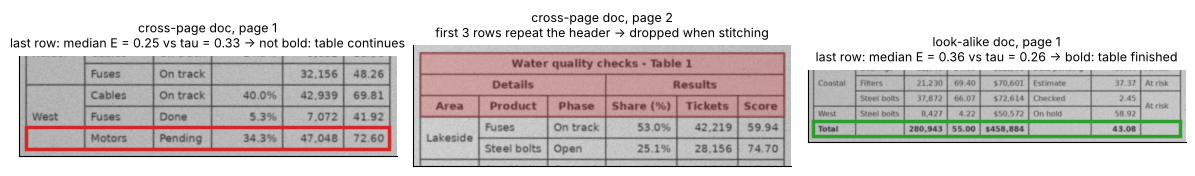

In [50]:
def last_row_evidence(pre: dict) -> tuple:
    """For the last table on a page: its structure, the median erosion score of its last row, and tau."""
    t = recover_structure(pre, DEFAULT_OPTS)[-1]
    erosion = cell_scores(pre, t["cells"])[:, 0]
    _, tau, last_bold = decide_bold(t["cells"], erosion, t["n_rows"], t["n_header"])
    last = [e for q, e in zip(t["cells"], erosion) if q["row"] == t["n_rows"] - 1 and not np.isnan(e)]
    return t, float(np.median(last)), tau, last_bold


fig, axes = plt.subplots(1, 3, figsize=(12, 3.0))
panels = [(cache_demo[(0, True, "adaptive")], "cross-page doc, page 1", "end"),
          (cache_demo[(1, True, "adaptive")], "cross-page doc, page 2", "start"),
          (cache_look[(0, True, "adaptive")], "look-alike doc, page 1", "end")]
for ax, (pre, title, where) in zip(axes, panels):
    t, med, tau, last_bold = last_row_evidence(pre)
    ys = t["ys"]
    y_lo, y_hi = (ys[-5], ys[-1]) if where == "end" else (ys[0], ys[min(5, len(ys) - 1)])
    x0, x1 = t["xs"][0], t["xs"][-1]
    ax.imshow(pre["gray"][int(y_lo) - 12:int(y_hi) + 12, int(x0) - 12:int(x1) + 12], cmap="gray", vmin=0, vmax=255,
              extent=(x0 - 12, x1 + 12, y_hi + 12, y_lo - 12))
    if where == "end":
        color = "tab:green" if last_bold else "tab:red"
        ax.add_patch(Rectangle((x0, ys[-2]), x1 - x0, ys[-1] - ys[-2], fill=False, ec=color, lw=2.5))
        verdict = "bold: table finished" if last_bold else "not bold: table continues"
        ax.set_title(f"{title}\nlast row: median E = {med:.2f} vs tau = {tau:.2f} -> {verdict}", fontsize=9)
    else:
        H = t["n_header"]
        ax.add_patch(Rectangle((x0, ys[0]), x1 - x0, ys[H] - ys[0], fc="tab:red", alpha=0.25, ec="tab:red", lw=2))
        ax.set_title(f"{title}\nfirst {H} rows repeat the header -> dropped when stitching", fontsize=9)
    ax.set_xticks([]), ax.set_yticks([]), ax.grid(False)
plt.tight_layout()
plt.show()

## 12. Measuring quality: tree edit distance, TEDS and Bold-F1

### 12.1 Tables as trees

How similar are two tables? Cell-by-cell comparison breaks down as soon as the structures differ:
if the prediction misses one row boundary, every cell below it is "in the wrong place", although
most of the content is right. A better view is the table's **HTML tree**: a `table` node whose
children are `tr` (row) nodes, whose children are `td` (cell) nodes. Each `td` carries its
`rowspan`, `colspan` and text. Merge markers produce **no** `td`: exactly as in HTML, a merged cell
is one `td` with spans.

```
                      table
           ___________/ | \___________
         tr             tr            tr
         |           /  |  \        /    \
   td(1x4,"Fruit..")  td  td  td   td      td ...
```

In [51]:
@dataclass
class Node:
    """A node of a table tree: tag 'table', 'tr' or 'td'. td nodes carry (rowspan, colspan) and text."""
    tag: str
    span: tuple = (1, 1)
    text: str = ""
    children: list = field(default_factory=list)


def table_tree(t: Table) -> Node:
    """Logical table -> HTML-like tree (one tr per grid row, one td per logical cell anchored in it)."""
    rows = []
    for r in range(t.n_rows):
        tds = [Node("td", (c.rowspan, c.colspan), c.text) for c in sorted(t.cells, key=lambda q: q.col) if c.row == r]
        rows.append(Node("tr", children=tds))
    return Node("table", children=rows)


def tree_size(n: Node) -> int:
    return 1 + sum(tree_size(ch) for ch in n.children)


def to_html(n: Node) -> str:
    """Compact HTML string of a table tree (for display)."""
    if n.tag == "td":
        attrs = "".join(f' {k}="{v}"' for k, v in zip(("rowspan", "colspan"), n.span) if v > 1)
        return f"<td{attrs}>{n.text.replace(chr(10), '<br>')}</td>"
    return f"<{n.tag}>" + "".join(to_html(ch) for ch in n.children) + f"</{n.tag}>"


demo_tree = table_tree(markdown_to_tables(tables_to_markdown([demo]))[0])
print("nodes:", tree_size(demo_tree), "(1 table + 4 tr + 11 td)")
print(to_html(demo_tree)[:400] + " ...")

nodes: 16 (1 table + 4 tr + 11 td)
<table><tr><td colspan="4">Fruit stock - Week 12</td></tr><tr><td>Fruit</td><td>Store</td><td>Boxes</td><td>Note</td></tr><tr><td rowspan="2">Apples</td><td>Dock|A</td><td>120</td><td rowspan="2">Fresh<br>today</td></tr><tr><td>Dock|B</td><td>85</td></tr></table> ...


### 12.2 Tree edit distance

The **tree edit distance** $\text{TED}(T_1, T_2)$ is the minimum total cost of edit operations that
turn $T_1$ into $T_2$:

* **delete** a node (its children move up to its parent, keeping their order), cost 1.
* **insert** a node (the inverse), cost 1.
* **rename** a node $a$ into $b$, cost $c(a, b) \in [0, 1]$.

For tables, the rename cost encodes what "similar cells" means:

$$
c(a, b) = \begin{cases}
1 & \text{if the tags differ, or both are } \texttt{td} \text{ with different spans,} \\
\dfrac{\text{lev}(s_a, s_b)}{\max(|s_a|, |s_b|)} & \text{if both are } \texttt{td} \text{ with equal spans (texts } s_a, s_b\text{)}, \\
0 & \text{otherwise (same non-td tag)}.
\end{cases}
$$

where lev is the Levenshtein distance (Section 8.2). A cell read as `Vaives` instead of `Valves`
costs only $1/6$, and a cell with the wrong span costs a full 1, like a missing cell.

**The Zhang–Shasha algorithm** (1989) computes TED by dynamic programming over *forests*. Number
the nodes of each tree in **post-order** (children before parents, left to right), and let $l(i)$
be the leftmost leaf descendant of node $i$. The subtree of $i$ consists exactly of the nodes
$l(i), l(i)+1, \dots, i$, so prefixes of the post-order are forests. For a pair of nodes
$(i_0, j_0)$ define the forest distance $fd(i, j)$ between $T_1[l(i_0)..i]$ and $T_2[l(j_0)..j]$:

$$
fd(i, j) = \min \begin{cases}
fd(i-1, j) + 1 & \text{(delete } i\text{)} \\
fd(i, j-1) + 1 & \text{(insert } j\text{)} \\
fd(l(i)-1, l(j)-1) + \text{td}(i, j) & \text{(match the subtrees of } i \text{ and } j\text{)}
\end{cases}
$$

where $\text{td}(i, j)$ is the tree distance of the two subtrees. When both forests are whole
subtrees ($l(i) = l(i_0)$ and $l(j) = l(j_0)$), the third case becomes
$fd(i-1, j-1) + c(i, j)$ and the result is stored as $\text{td}(i, j)$. The algorithm only needs
to start a new forest table at **key roots** (the root and every node that has a left sibling)
because every other subtree distance is computed along the way. For our shallow, wide table trees
this costs roughly $O(|T_1|\,|T_2|)$ table entries times a small constant.

In [52]:
def _postorder(root: Node) -> tuple:
    """Nodes in post-order and the index of each node's leftmost leaf descendant."""
    nodes, lml = [], []

    def visit(n):
        first = None
        for ch in n.children:
            leaf = visit(ch)
            if first is None:
                first = leaf
        nodes.append(n)
        lml.append(len(nodes) - 1 if first is None else first)
        return lml[-1]

    visit(root)
    return nodes, lml


def rename_cost(a: Node, b: Node, use_text: bool = True) -> float:
    if a.tag != b.tag:
        return 1.0
    if a.tag != "td":
        return 0.0
    if a.span != b.span:
        return 1.0
    if not use_text or a.text == b.text:
        return 0.0
    return levenshtein(a.text, b.text) / max(len(a.text), len(b.text))


def _keyroots(lml: list) -> list:
    """Key roots: for every leftmost-leaf value, the highest node that has it (the root and all left-siblinged nodes)."""
    seen, roots = set(), []
    for i in range(len(lml) - 1, -1, -1):
        if lml[i] not in seen:
            seen.add(lml[i])
            roots.append(i)
    return sorted(roots)


def tree_edit_distance(t1: Node, t2: Node, use_text: bool = True) -> float:
    """Zhang–Shasha tree edit distance with unit insert/delete costs and the table rename cost.

    Plain Python lists are used on purpose: element access in tight loops is much faster than NumPy.
    """
    A, la = _postorder(t1)
    B, lb = _postorder(t2)
    n, m = len(A), len(B)
    td = [[0.0] * m for _ in range(n)]
    cost = {}
    for i0 in _keyroots(la):
        li = la[i0]
        for j0 in _keyroots(lb):
            lj = lb[j0]
            rows, cols = i0 - li + 2, j0 - lj + 2
            fd = [[float(x + y) if x == 0 or y == 0 else 0.0 for y in range(cols)] for x in range(rows)]
            for x in range(1, rows):
                i = li + x - 1
                lai, fdx, fdx1, tdi = la[i], fd[x], fd[x - 1], td[i]
                for y in range(1, cols):
                    j = lj + y - 1
                    if lai == li and lb[j] == lj:             # both forests are whole subtrees
                        c = cost.get((i, j))
                        if c is None:
                            c = cost[(i, j)] = rename_cost(A[i], B[j], use_text)
                        v = min(fdx1[y] + 1, fdx[y - 1] + 1, fdx1[y - 1] + c)
                        tdi[j] = v
                    else:
                        v = min(fdx1[y] + 1, fdx[y - 1] + 1, fd[lai - li][lb[j] - lj] + tdi[j])
                    fdx[y] = v
    return float(td[n - 1][m - 1])

Before trusting our implementation we compare it with an independent one: the `apted` package
(an optimized algorithm for the same distance) on random small trees. If `apted` cannot be
installed, the cell says so and moves on.

In [53]:
def random_table_tree(rng, max_rows: int = 4, max_cols: int = 4) -> Node:
    rows = []
    for _ in range(int(rng.integers(1, max_rows + 1))):
        tds = [Node("td", (int(rng.integers(1, 3)), int(rng.integers(1, 3))),
                    "".join(rng.choice(list("abc12"), size=int(rng.integers(0, 4)))))
               for _ in range(int(rng.integers(1, max_cols + 1)))]
        rows.append(Node("tr", children=tds))
    return Node("table", children=rows)


try:
    apted_lib = ensure("apted")

    class TableConfig(apted_lib.Config):
        def rename(self, a, b):
            return rename_cost(a, b)

        def children(self, node):
            return node.children

    check_rng = np.random.default_rng(5)
    diffs = []
    for _ in range(40):
        a, b = random_table_tree(check_rng), random_table_tree(check_rng)
        ref = apted_lib.APTED(a, b, TableConfig()).compute_edit_distance()
        diffs.append(abs(ref - tree_edit_distance(a, b)))
    print(f"40 random tree pairs: max |ours - apted| = {max(diffs):.2e}")
except Exception as err:                          # offline and not installed
    print("apted not available, skipping the cross-check:", type(err).__name__)

big_a = table_tree(doc_demo.tables[0])
big_b = table_tree(markdown_to_tables(md_pred)[0])
victim = big_b.children[5].children[1]
victim.text = "#" + victim.text[1:]                        # one misread character
t0 = time.time()
d_big = tree_edit_distance(big_a, big_b)
print(f"{tree_size(big_a)}-node trees, one wrong character in {victim.text!r}: TED = {d_big:.4f} "
      f"(= 1/{len(victim.text)}) in {time.time() - t0:.2f} s")

40 random tree pairs: max |ours - apted| = 0.00e+00


141-node trees, one wrong character in '#ables': TED = 0.1667 (= 1/6) in 0.14 s


### 12.3 TEDS, TEDS-Struct and Bold-F1

Distances are hard to compare across tables of different sizes, so we normalize:

$$
\text{TEDS}(T_{\text{pred}}, T_{\text{true}}) = 1 - \frac{\text{TED}(T_{\text{pred}}, T_{\text{true}})}{\max\big(|T_{\text{pred}}|, |T_{\text{true}}|\big)} \in [0, 1],
$$

where $|T|$ is the number of nodes. TEDS is 1 for identical tables and falls towards 0 as they
differ. (For arbitrary trees the edit distance can exceed the larger size (think of a long chain
against a wide star), so our `teds_document` below clips TEDS at 0. The reference implementation
released with the PubTabNet dataset, which introduced TEDS, does not clip. For table-shaped trees
this practically never matters.) **TEDS-Struct** is the same score with text ignored (two `td`
with equal spans cost 0), so it isolates structure errors.

A **document** may hold several tables. We pair predicted and true tables in reading order. A
table without a partner is compared with an empty tree (its whole size is the distance):

$$
\text{TEDS}_{\text{doc}} = 1 - \frac{\sum_k \text{TED}_k}{\sum_k \max(|P_k|, |T_k|)} .
$$

Missing a table, inventing one, or failing to stitch all cost exactly what they should: the
nodes involved.

**Bold-F1** compares the *multisets* of texts of bold cells (a multiset because "Total" may be bold
in several tables): with $\mathcal{P}$ and $\mathcal{G}$ the predicted and true multisets,
$\text{tp} = |\mathcal{P} \cap \mathcal{G}|$ (each text counts as often as the smaller of its
two counts), precision $p = \text{tp}/|\mathcal{P}|$, recall $r = \text{tp}/|\mathcal{G}|$ and
$F_1 = 2pr/(p+r)$, with $F_1 = 0$ when $\text{tp} = 0$, and two empty multisets score 1. Matching by
text rather than by position keeps Bold-F1 independent of structure errors.

The final document score is

$$
\text{Score} = 0.9 \cdot \text{TEDS}_{\text{doc}} + 0.1 \cdot \text{Bold-F1}, \qquad \text{and Score} = 0 \text{ if the output is not valid.}
$$

Two shortcuts keep evaluation fast: identical tables have TED 0 without any computation, and
tables with identical spans have TEDS-Struct 1.

In [54]:
def table_signature(t: Table, use_text: bool) -> tuple:
    return (t.n_rows, t.n_cols, tuple(sorted((c.row, c.col, c.rowspan, c.colspan, c.text if use_text else "")
                                             for c in t.cells)))


def teds_document(pred_md: str, true_md: str, use_text: bool = True) -> float:
    """Document-level TEDS (tables paired in reading order), 0 for invalid predictions."""
    if not validate_markdown(pred_md)[0]:
        return 0.0
    P, T = markdown_to_tables(pred_md), markdown_to_tables(true_md)
    num = den = 0.0
    for k in range(max(len(P), len(T))):
        if k >= len(P) or k >= len(T):
            size = tree_size(table_tree((P + T)[k] if k >= len(T) else T[k]))
            num, den = num + size, den + size
            continue
        a, b = table_tree(P[k]), table_tree(T[k])
        den += max(tree_size(a), tree_size(b))
        if table_signature(P[k], use_text) != table_signature(T[k], use_text):
            num += tree_edit_distance(a, b, use_text)
    return max(0.0, 1.0 - num / den)


def bold_bag(md: str) -> Counter:
    return Counter(re.sub(r"\s+", " ", c.text).strip() for t in markdown_to_tables(md) for c in t.cells
                   if c.bold and c.text.strip())


def f1_bags(pred: Counter, true: Counter) -> float:
    if not pred and not true:
        return 1.0
    tp = sum((pred & true).values())
    if tp == 0:
        return 0.0
    precision, recall = tp / sum(pred.values()), tp / sum(true.values())
    return 2 * precision * recall / (precision + recall)


def score_document(pred_md: str, true_md: str) -> dict:
    if not validate_markdown(pred_md)[0]:
        return dict(valid=False, teds=0.0, teds_struct=0.0, bold_f1=0.0, score=0.0)
    teds = teds_document(pred_md, true_md)
    bf1 = f1_bags(bold_bag(pred_md), bold_bag(true_md))
    return dict(valid=True, teds=teds, teds_struct=teds_document(pred_md, true_md, use_text=False),
                bold_f1=bf1, score=0.9 * teds + 0.1 * bf1)


md_true = doc_demo.markdown
md_kept_header, _ = extract_document([img for img, _ in scans_demo], oracle_demo, opts=dict(drop_header=False))
variants = {
    "perfect": md_true,
    "one misread word (Fuses -> Fusas)": md_true.replace("| Fuses |", "| Fusas |", 1),
    "one missed vertical merge": md_true.replace("[[V]]", "", 1),
    "repeated header not dropped": md_kept_header,
    "all bold markers lost": md_true.replace("**", ""),
    "separator line missing (invalid)": "\n".join(ln for i, ln in enumerate(md_true.split("\n")) if i != 1),
}
display(pd.DataFrame({k: score_document(v, md_true) for k, v in variants.items()}).T.round(4))

,valid,teds,teds_struct,bold_f1,score
perfect,True,1.0,1.0,1.0,1.0
one misread word (Fuses -> Fusas),True,0.9986,1.0,1.0,0.9987
one missed vertical merge,True,0.9859,0.9859,1.0,0.9873
repeated header not dropped,True,0.9216,0.9216,0.7429,0.9037
all bold markers lost,True,1.0,1.0,0.0,0.9
separator line missing (invalid),False,0.0,0.0,0.0,0.0


Read the table: a misread word costs almost nothing (one character of one cell), a missed merge
costs a little more (one `td` gains a wrong span and an extra `td` appears), keeping a repeated
header costs a lot (three extra rows, and their bold texts also hurt Bold-F1), losing bold costs
exactly the 10% weight of Bold-F1, and an invalid file loses **everything**.

**Quick check.** A prediction is perfect except that one table was split into two (stitching
failed, header dropped correctly in neither). Which score notices: TEDS-Struct, TEDS, Bold-F1?

<details><summary>Answer</summary>

All three. TEDS and TEDS-Struct: the first predicted table lacks the rows of page 2 and the
second predicted table has no partner in the truth (or pairs with the wrong table), so many nodes
must be inserted or deleted. Bold-F1: the repeated header cells now appear twice among the bold
texts, so precision drops.
</details>

In [55]:
# ✏️ Exercise 8: TEDS on tiny trees
def teds(t1: Node, t2: Node) -> float:
    """1 - TED / max(size1, size2), using tree_edit_distance and tree_size from above."""
    # YOUR CODE HERE
    raise NotImplementedError

def _test():
    td = lambda text, span=(1, 1): Node("td", span, text)
    tr = lambda *cells: Node("tr", children=list(cells))
    tb = lambda *rows: Node("table", children=list(rows))
    assert abs(teds(tb(tr(td("ab"))), tb(tr(td("ab")))) - 1.0) < 1e-9, "identical trees"
    assert abs(teds(tb(tr(td("ab"))), tb(tr(td("ac")))) - (1 - 0.5 / 3)) < 1e-9, "rename 'ab'->'ac' costs 1/2"
    assert abs(teds(tb(tr(td("a"), td("b"))), tb(tr(td("a")))) - 0.75) < 1e-9, "one deleted cell out of 4 nodes"
    assert abs(teds(tb(tr(td("x", (1, 2)))), tb(tr(td("x")))) - (1 - 1 / 3)) < 1e-9, "different spans cost 1"
    two_rows = tb(tr(td("a"), td("b")), tr(td("c"), td("d")))
    one_row = tb(tr(td("a"), td("b")))
    assert abs(teds(two_rows, one_row) - (1 - 3 / 7)) < 1e-9, "a missing row = 3 deleted nodes"

run_check("Exercise 8", _test)

⏳ Exercise 8: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def teds(t1, t2):
    return 1.0 - tree_edit_distance(t1, t2) / max(tree_size(t1), tree_size(t2))
```
Check the last test by hand: the 2-row tree has $1 + 2 + 4 = 7$ nodes, the 1-row tree 4. The
cheapest edit deletes one `tr` and its two `td`s (3 operations), so TEDS $= 1 - 3/7 \approx 0.571$.
</details>

In [56]:
# ✏️ Exercise 9: F1 between two multisets of bold texts
def bold_f1_bags(pred: Counter, true: Counter) -> float:
    """F1 of two multisets (Counters). Both empty -> 1.0, no overlap -> 0.0."""
    # YOUR CODE HERE
    raise NotImplementedError

def _test():
    assert bold_f1_bags(Counter(), Counter()) == 1.0, "nothing bold anywhere is a perfect match"
    assert bold_f1_bags(Counter({"Total": 1}), Counter()) == 0.0, "bold predicted, none true"
    got = bold_f1_bags(Counter({"Total": 1, "Region": 1}), Counter({"Total": 1}))
    assert abs(got - 2 / 3) < 1e-9, f"P = 1/2, R = 1 -> F1 = 2/3, got {got}"
    got = bold_f1_bags(Counter({"Total": 2}), Counter({"Total": 1}))
    assert abs(got - 2 / 3) < 1e-9, f"multisets: only one 'Total' is matched, got {got}"
    assert bold_f1_bags(Counter({"a": 1}), Counter({"b": 1})) == 0.0

run_check("Exercise 9", _test)

⏳ Exercise 9: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def bold_f1_bags(pred, true):
    if not pred and not true:
        return 1.0
    tp = sum((pred & true).values())          # multiset intersection: min of the counts
    if tp == 0:
        return 0.0
    p, r = tp / sum(pred.values()), tp / sum(true.values())
    return 2 * p * r / (p + r)
```
`Counter & Counter` keeps, for every key, the minimum of the two counts, which is exactly the number of
matched items in a multiset.
</details>

## 13. Experiments

### 13.1 A test set and the main results

We generate a fresh test set (seeds never used above): 24 documents, 6 per level, scanned at the
*medium* level. The pipeline runs with the oracle reader, so every remaining error is a structure,
stitching or bold error. Preprocessed pages are cached, so that the ablations below only redo the
stages they change.

Besides the scores of Section 12 we report a purely geometric structure metric, **cell F1**: the
true cell boxes (moved through the scan and deskew rotations) are matched with the detected cell
boxes, and a true cell counts as found if some detected box has IoU $> 0.5$ with it. Because true
cells do not overlap, a detected box can never have IoU $> 0.5$ with *two* of them (each overlap
would exceed half of the detected box's area), so no explicit one-to-one assignment is needed.
With $n_{\text{pred}}$ detected and $n_{\text{true}}$ true cells and $tp$ matches,
$F_1 = 2\,tp / (n_{\text{pred}} + n_{\text{true}})$, which is the harmonic mean of precision and recall.

In [57]:
def make_test_set(per_level: dict, severity: str, base_seed: int) -> list:
    """Generate, render and scan documents. Returns a list of dicts (doc, truth, images, Ms, cache)."""
    items = []
    for lvl, n in per_level.items():
        for k in range(n):
            seed = base_seed + 1000 * int(lvl[1]) + k
            d = make_document(lvl, seed)
            pages, truth = render_document(d)
            srng = np.random.default_rng(seed + 7)
            scans = [scan(pg, srng, severity) for pg in pages]
            items.append(dict(doc=d, truth=truth, images=[im for im, _ in scans], Ms=[M for _, M in scans], cache={}))
    return items


def first_failure(item: dict, md: str, info: dict) -> str:
    """Attribute a document's errors to the earliest pipeline stage that went wrong."""
    for p, tr in enumerate(item["truth"]):
        parts, page = tr["parts"], info["pages"][p]
        if len(page["sizes"]) != len(parts):
            return "1 table detection"
        for k, part in enumerate(parts):
            t = item["doc"].tables[part["table"]]
            if page["sizes"][k] != (len(part["rows"]), t.n_cols):
                return "2 grid (rows / columns)"
            if page["cells"][k] != part_truth(t, part["rows"]):
                return "3 merged cells"
    if len(info["tables"]) != len(item["doc"].tables):
        return "4 stitching"
    sc = score_document(md, item["doc"].markdown)
    if sc["teds"] < 1:
        return "5 header drop / text"
    if sc["bold_f1"] < 1:
        return "6 bold"
    return "perfect"


def iou_matrix(P: list, G: list) -> np.ndarray:
    """IoU of every predicted box with every true box (vectorized), shape (len(P), len(G))."""
    P, G = np.asarray(P, float)[:, None, :], np.asarray(G, float)[None, :, :]
    iw = np.clip(np.minimum(P[..., 2], G[..., 2]) - np.maximum(P[..., 0], G[..., 0]), 0, None)
    ih = np.clip(np.minimum(P[..., 3], G[..., 3]) - np.maximum(P[..., 1], G[..., 1]), 0, None)
    inter = iw * ih
    area = lambda B: (B[..., 2] - B[..., 0]) * (B[..., 3] - B[..., 1])
    return inter / (area(P) + area(G) - inter)


def cell_f1(item: dict, info: dict, thr: float = 0.5) -> float:
    """F1 of detected cell boxes vs true cell boxes (moved into the deskewed frame), matched at IoU > thr."""
    tp = n_pred = n_true = 0
    for p, page in enumerate(info["pages"]):
        A = compose(page["D"], item["Ms"][p])
        gt = []
        for part in item["truth"][p]["parts"]:
            for x0, y0, x1, y1 in part["boxes"].values():
                xs, ys = apply_affine(A, [x0, x1, x0, x1], [y0, y0, y1, y1])
                gt.append((xs.min(), ys.min(), xs.max(), ys.max()))
        pred = [b for boxes in page["boxes"] for b in boxes]
        n_pred, n_true = n_pred + len(pred), n_true + len(gt)
        if pred and gt:
            tp += int((iou_matrix(pred, gt) > thr).any(axis=0).sum())
    return 2 * tp / (n_pred + n_true) if n_pred + n_true else 1.0


def run_pipeline(items: list, reader: str = "oracle", opts: dict | None = None) -> pd.DataFrame:
    rows = []
    for it in items:
        rd = make_oracle(it["truth"], it["Ms"]) if reader == "oracle" else make_tesseract_reader()
        t0 = time.time()
        md, info = extract_document(it["images"], rd, opts, cache=it["cache"])
        seconds = time.time() - t0
        rows.append(dict(level=it["doc"].level, layout=it["doc"].layout, pages=len(it["images"]),
                         seconds=seconds, stage=first_failure(it, md, info), cell_f1=cell_f1(it, info),
                         **score_document(md, it["doc"].markdown)))
    return pd.DataFrame(rows)


t0 = time.time()
test_set = make_test_set({"L1": 6, "L2": 6, "L3": 6, "L4": 6}, "medium", base_seed=50_000)
t_gen = time.time() - t0
t0 = time.time()
main_res = run_pipeline(test_set)
t_run = time.time() - t0
print(f"generated {len(test_set)} documents ({sum(len(it['images']) for it in test_set)} pages) in {t_gen:.1f} s, "
      f"and pipeline + scoring in {t_run:.1f} s")
METRICS = ["valid", "cell_f1", "teds", "teds_struct", "bold_f1", "score"]
summary = main_res.groupby("level")[METRICS].mean()
summary.loc["all"] = main_res[METRICS].mean()
display(summary.round(4))

generated 24 documents (29 pages) in 3.5 s; pipeline + scoring in 4.0 s


,valid,cell_f1,teds,teds_struct,bold_f1,score
level,,,,,,
L1,1.0,1.0,1.0,1.0,1.0000,1.0000
L2,1.0,1.0,1.0,1.0,1.0000,1.0000
L3,1.0,1.0,1.0,1.0,0.9301,0.9930
L4,1.0,1.0,1.0,1.0,0.9524,0.9952
all,1.0,1.0,1.0,1.0,0.9706,0.9971


With the oracle reader, the structure of all 24 documents is perfect at the medium level: every
table found, every grid and merge right, every cross-page table stitched. All remaining errors are
**bold** errors. The documents responsible are listed below with the first stage that failed.

In [58]:
display(main_res.loc[main_res.stage != "perfect", ["level", "layout", "stage", "teds", "bold_f1", "score"]].round(4))

,level,layout,stage,teds,bold_f1,score
12,L3,two_tables,6 bold,1.0,0.9667,0.9967
13,L3,side_by_side,6 bold,1.0,0.8333,0.9833
14,L3,single,6 bold,1.0,0.9756,0.9976
15,L3,single,6 bold,1.0,0.9091,0.9909
16,L3,two_tables,6 bold,1.0,0.9254,0.9925
17,L3,two_tables,6 bold,1.0,0.9706,0.9971
21,L4,single,6 bold,1.0,0.7143,0.9714


Two different causes hide in this list. In the L3 documents the missing bold cells are the rare
*highlighted body cells*, which the bold grammar ignores by design. A document whose whole bold
**totals row** was missed is a real detector failure: with a larger font, regular strokes are
thick enough to partly survive the $3 \times 3$ erosion too, the bold and regular scores of that
table overlap, and the median of the totals row lands just below the calibrated threshold. A fix
would measure stroke width *relative to the text height* (or erode with a kernel that grows with
the font size), a nice extension to try.

### 13.2 Real OCR: what does reading cost?

Now we swap the oracle for Tesseract on a small subset (one document per level, to keep the
runtime modest). Everything else is identical, so the drop in TEDS is the price of reading.

In [59]:
if TESSERACT_OK:
    subset = [next(it for it in test_set if it["doc"].level == lvl) for lvl in ["L1", "L2", "L3", "L4"]]
    ocr_rows = []
    for name in ["oracle", "tesseract"]:
        res = run_pipeline(subset, reader=name)
        res["reader"] = name
        ocr_rows.append(res)
    ocr_res = pd.concat(ocr_rows)
    display(ocr_res.pivot_table(index="level", columns="reader", values=["teds", "teds_struct", "score", "seconds"])
            .round(3))
    print("mean score: oracle %.4f | Tesseract %.4f" % tuple(ocr_res.groupby("reader").score.mean()))
else:
    print("Tesseract is not installed: skipping the OCR comparison.")

score           seconds             teds           teds_struct          
reader oracle tesseract  oracle tesseract oracle tesseract      oracle tesseract
level                                                                           
L1      1.000     1.000   0.030     1.027    1.0     1.000         1.0       1.0
L2      1.000     0.994   0.081     4.288    1.0     0.993         1.0       1.0
L3      0.997     0.990   0.070     3.611    1.0     0.996         1.0       1.0
L4      1.000     0.989   0.042     1.840    1.0     0.996         1.0       1.0

mean score: oracle 0.9992 | Tesseract 0.9931


Reading costs surprisingly little here: our fonts are clean, the crops are tight and the whitelist
removes most confusions. On real scans (other fonts, stamps, handwriting) the OCR stage is usually
the dominant error source, which is precisely why the oracle experiment is useful: it tells you
how much there is to gain from a better reader versus a better structure recognizer.

### 13.3 Robustness: how much noise can the pipeline take?

Same pipeline, oracle reader, 12 new documents (3 per level), each scanned at four severities.

In [60]:
sweep_rows, sweep_stages = [], {}
for severity in ["clean", "light", "medium", "heavy"]:
    items = make_test_set({"L1": 3, "L2": 3, "L3": 3, "L4": 3}, severity, base_seed=70_000)
    res = run_pipeline(items)
    sweep_rows.append({"severity": severity, **res[METRICS].mean().to_dict()})
    sweep_stages[severity] = res.stage.value_counts()
    del items
sweep = pd.DataFrame(sweep_rows).set_index("severity")
display(sweep.round(4))
display(pd.DataFrame(sweep_stages).fillna(0).astype(int).sort_index())

,valid,cell_f1,teds,teds_struct,bold_f1,score
severity,,,,,,
clean,1.0,1.0000,1.0000,1.0000,0.9855,0.9985
light,1.0,1.0000,1.0000,1.0000,0.9786,0.9979
medium,1.0,1.0000,1.0000,1.0000,0.9855,0.9985
heavy,1.0,0.9143,0.9152,0.9152,0.8983,0.9135


,clean,light,medium,heavy
stage,,,,
1 table detection,0,0,0,1
3 merged cells,0,0,0,2
6 bold,2,3,2,1
perfect,10,9,10,8


### 13.4 Ablations: which stage matters?

An **ablation** switches off one component and measures the damage. All runs use the 24-document
medium test set from Section 13.1 and the oracle reader.

In [61]:
ABLATIONS = {
    "full pipeline": {},
    "no deskew": dict(deskew=False),
    "CLAHE + Otsu binarization": dict(binarize="clahe"),
    "no merge inference": dict(merges=False),
    "no cross-page stitching": dict(stitch=False),
    "stitch but keep repeated header": dict(drop_header=False),
    "bold: per-cell instead of grammar": dict(bold="per-cell"),
}
abl_rows = []
for name, opts in ABLATIONS.items():
    t0 = time.time()
    res = main_res if name == "full pipeline" else run_pipeline(test_set, opts=opts)
    abl_rows.append({"variant": name, **res[METRICS].mean().to_dict(), "seconds": time.time() - t0})
    for it in test_set:                       # keep only the default preprocessing in the caches
        it["cache"] = {k: v for k, v in it["cache"].items() if k[1:] == (True, "adaptive")}
abl = pd.DataFrame(abl_rows).set_index("variant")
abl["change in score"] = abl.score - abl.loc["full pipeline", "score"]
display(abl.drop(columns="seconds").round(4))

,valid,cell_f1,teds,teds_struct,bold_f1,score,change in score
variant,,,,,,,
full pipeline,1.0,1.0000,1.0000,1.0000,0.9706,0.9971,0.0000
no deskew,1.0,0.6943,0.6506,0.6922,0.6756,0.6531,-0.3439
CLAHE + Otsu binarization,1.0,0.5450,0.3285,0.4107,0.3782,0.3335,-0.6636
no merge inference,1.0,0.9155,0.8861,0.8861,0.7630,0.8738,-0.1233
no cross-page stitching,1.0,1.0000,0.9072,0.9072,0.9277,0.9093,-0.0878
stitch but keep repeated header,1.0,1.0000,0.9871,0.9871,0.9277,0.9812,-0.0159
bold: per-cell instead of grammar,1.0,1.0000,1.0000,1.0000,0.9362,0.9936,-0.0034


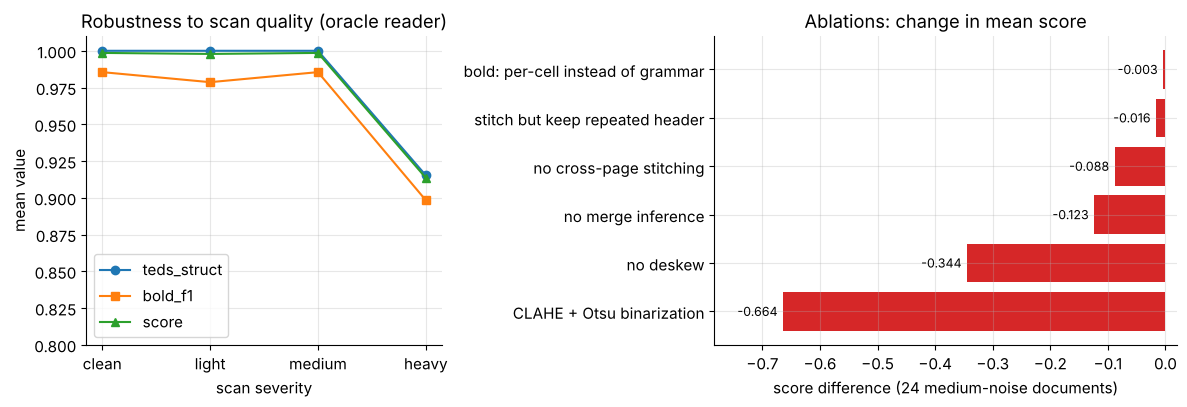

In [62]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1, 1.3]})
for col, marker in [("teds_struct", "o"), ("bold_f1", "s"), ("score", "^")]:
    axes[0].plot(sweep.index, sweep[col], marker=marker, label=col)
axes[0].set(title="Robustness to scan quality (oracle reader)", xlabel="scan severity", ylabel="mean value",
            ylim=(0.8, 1.01))
axes[0].legend()
deltas = abl["change in score"].drop("full pipeline").sort_values()
axes[1].barh(deltas.index, deltas.values, color="tab:red")
axes[1].set(title="Ablations: change in mean score", xlabel="score difference (24 medium-noise documents)")
for y, v in enumerate(deltas.values):
    axes[1].text(v - 0.01, y, f"{v:+.3f}", va="center", ha="right", fontsize=9)
axes[1].set_xlim(deltas.min() - 0.12, 0.02)
plt.tight_layout()
plt.show()

### 13.5 Reading the results: error analysis by stage

Every document above was labeled with the **first stage that went wrong** (`first_failure`), using
the ground-truth geometry: table count per page, then grid size, then merged cells, then
stitching, then text/header handling, then bold. Attributing each document to its earliest
failure avoids double counting: a missed table also ruins its grid, merges and text, but the fix
belongs to the detector. What the numbers say:

* **Up to the medium level, structure is solved** on these documents. The only errors are bold
  errors (highlighted L3 body cells, and the occasional totals row on a large font).
* **At the heavy level, structure starts to break**: one table drawn with 1-pixel rules is not
  detected at all, and in two documents neighboring cells are *wrongly merged* (a real boundary
  is lost). Heavy blur plus noise breaks thin lines into pieces shorter than the opening stencil,
  and the opening removes them: the 1-pixel table keeps only a few short fragments of its rules,
  and at each lost boundary the line coverage drops below 0.20, so union–find glues the slots on
  both sides into one cell.
* **Deskewing is essential.** Without it, a tilt of 2.5° (the largest at the medium level) moves a
  rule by about 40 pixels across a 900-pixel table: the line climbs one pixel every 23 pixels, so
  a horizontal stencil of length 41 barely fits inside it (or not at all), rules break into
  fragments or vanish from the masks, and rows merge.
* **The binarization choice matters even more** (CLAHE + Otsu): fused letters survive the opening
  and create fake ruling lines, which split rows and invent cells. That is the effect we predicted in
  Section 5.1, now measured end to end.
* **Merges and stitching** are worth about 0.12 and 0.09 points: ignoring merges also breaks the
  header rule ($H$ falls back to 1), so bold detection suffers too. Without stitching, every
  cross-page table appears twice with a repeated header.
* **Small things add up**: keeping repeated headers or using per-cell bold decisions each cost
  less than 0.02, but they are free to fix.
* **Different metrics see different errors.** Cell F1 compares cell boxes page by page, so it is
  blind to stitching and header handling: the ablations "no cross-page stitching" and "stitch but
  keep repeated header" keep a perfect cell F1 while TEDS drops, and the per-cell bold ablation
  changes neither (only Bold-F1 moves). Conversely, cell F1 checks box geometry, which TEDS never
  sees: TEDS compares only the logical structure and the text. Report several metrics, each
  answering a precise question.

> **Going deeper.** The test documents come from the same generator the pipeline was designed
> on, so these numbers are optimistic: a real benchmark needs documents from *other* sources.
> A fair protocol freezes all thresholds, then evaluates once on unseen data, exactly like a
> train/validation/test split, even though nothing here is "trained".

## 14. Beyond rules: borderless tables and learned models

### 14.1 Where a rule-based pipeline breaks

Our pipeline is strong because our documents keep their promises: ruling lines are drawn, merges
are visible as missing lines, headers are bold. Real collections break these promises in many ways:

* **Borderless tables**: no lines at all, only alignment. Columns must come from whitespace (our
  L4 approach), which fails when columns are close together, when a long cell text crosses the
  gap of its neighbors, or when numbers are right-aligned under left-aligned headers. Merged cells
  become ambiguous: is "North" a label for two rows, or does the second row have an empty cell?
* **Multi-line cells without lines**: is a second text line a new row or a wrapped cell? Humans
  use indentation, font and meaning. Projection profiles cannot.
* **Zebra stripes, colored headers, dotted rules**: the line masks see nothing, or see shading.
* **Camera photos**: perspective distortion and curved pages. A single rotation is not enough
  (you need a homography or page dewarping).
* **Layout**: tables inside multi-column pages, rotated (landscape) tables, nested tables.

### 14.2 Learned approaches

* **Detect, then recognize structure.** An object detector (for example a DETR-style detection
  transformer) finds tables on the page. A second detector, run on the table crop, predicts boxes
  for *rows*, *columns*, *column headers* and *spanning cells*. Cells are the intersections of rows
  and columns, merged where a spanning-cell box covers them, and the text comes from OCR or from
  the PDF itself. This is the design of the Table Transformer trained on the PubTables-1M dataset.
  It handles borderless tables because it learns from appearance and alignment, not from lines.
* **Image-to-markup.** An encoder–decoder network reads the table image and *writes* the HTML (or
  Markdown) token by token, structure tags and cell text included, the approach introduced
  together with the PubTabNet dataset and the TEDS metric, and later refined by models such as
  TableFormer. Whole-page models (Donut, Nougat) go further and transcribe entire documents.
* **Vision–language models.** General multimodal language models can simply be *asked* to convert
  a table image to Extended Markdown, even with a format specification like ours in the prompt.
  They are remarkably good on clean tables, but they can **hallucinate** plausible cells, skip
  rows of long tables, produce inconsistent merges, and they are slow and costly at scale.

| | Rule-based (this notebook) | Detector + structure model | Image-to-markup | Vision–language model |
|---|---|---|---|---|
| training data | none (but tuning on samples) | many labeled pages | many labeled tables | none for you (huge pretraining) |
| borderless tables | weak | good | good | good |
| merged cells | good if lines exist | via spanning-cell boxes | learned | often inconsistent |
| output always valid? | yes (validator + fallback) | yes (built from boxes) | no: decoder can emit broken markup | no |
| failure mode | silent misses on unexpected layouts | domain shift | hallucinated/missing tokens | hallucination, truncation |
| speed on CPU | fast | moderate | slow | slow (usually remote) |
| explainable | every decision visible | partly | hardly | hardly |

In practice the best systems are **hybrids**: a learned detector proposes table regions, ruled
tables go through a geometric pipeline like ours (fast, exact, explainable), borderless or messy
tables go to a learned structure model or a VLM, and *every* output passes through a validator and
consistency checks (rectangular merges, equal column counts, totals that actually add up).

> **Key idea.** Whatever recognizes the table, the *evaluation* machinery of this notebook (
> synthetic data with perfect labels, an oracle stage, TEDS, TEDS-Struct, Bold-F1, ablations and
> stage-by-stage error attribution) stays exactly the same. It is the part you will reuse most.

## 15. Quiz

Try each question before opening the answer. Every answer explains why the right option is right
*and* why each wrong option is wrong.

**Q1.** In Extended Markdown, a merged cell covers rows 4–5 and columns 1–3 of the grid. Which
markers does it produce besides its text?

- A. two `[[H]]` and three `[[V]]`
- B. three `[[H]]` and two `[[V]]`
- C. two `[[H]]` and two `[[V]]`
- D. five `[[V]]`

<details><summary>Answer</summary>

**A.** The block has $2 \times 3 = 6$ slots. Row 4 holds the anchor (the text) and two `[[H]]` to its
right. Row 5 holds `[[V]]` in all three columns. B swaps the roles of the rows and columns. C
forgets that the lower row needs a `[[V]]` under the anchor as well. D uses `[[V]]` in the anchor's
own row, which our rules forbid: `[[V]]` marks only the slots *below* the anchor's row.
</details>

**Q2.** Why do we extract horizontal rules with an *opening* (erosion, then dilation) by a
$1 \times 41$ stencil instead of an erosion alone?

- A. Erosion alone would keep the text.
- B. Erosion alone finds the rules but shortens each by 40 pixels. The dilation restores their full extent.
- C. The dilation removes noise that the erosion created.
- D. There is no difference. The opening is just conventional.

<details><summary>Answer</summary>

**B.** Erosion keeps only the pixels where the whole stencil fits (the interiors of long runs),
so every rule loses 20 pixels at each end. Dilating with the same stencil grows the survivors back
to exactly the runs that contained the stencil. A is wrong: erosion alone already removes the text
(short strokes). C is wrong: erosion never creates pixels, so there is nothing for the dilation to
remove. D is wrong: after erosion alone, a rule under a 45-pixel-wide cell would shrink to 5 pixels,
far too little for the profile thresholds and the coverage test that follow.
</details>

**Q3.** Otsu's method chooses the threshold $t$ that maximizes

- A. the within-class variance $\omega_0\sigma_0^2 + \omega_1\sigma_1^2$
- B. the between-class variance $\omega_0\omega_1(\mu_0 - \mu_1)^2$
- C. the number of pixels classified as ink
- D. the difference $\mu_1 - \mu_0$ of the class means

<details><summary>Answer</summary>

**B.** Because $\sigma_T^2 = \sigma_W^2 + \sigma_B^2$ and the total variance does not depend on $t$,
maximizing $\sigma_B^2$ is equivalent to *minimizing* the within-class variance, so A has the
direction wrong. C would push the threshold to 255. D ignores the class weights: it can be made
large by splitting off a handful of extreme pixels, which is why Otsu multiplies by $\omega_0\omega_1$.
</details>

**Q4.** The deskew step takes the **median** angle of the Hough segments because

- A. the median is faster to compute than the mean
- B. a few wrong segments (vertical rules, joined corners) barely move the median but can drag the mean far away
- C. the median removes the staircase bias of small angles
- D. the mean of angles is undefined

<details><summary>Answer</summary>

**B.** The median is robust to outliers. A is irrelevant (both are cheap). C is false: the staircase
bias affects *most* segments in the same direction, which no robust statistic can undo, and that is why
we added the projection-profile refinement. D is false for angles in a small range like
$[-5^\circ, 5^\circ]$, where the ordinary mean is perfectly well defined.
</details>

**Q5.** A boundary segment between two slots has line coverage 0.35. With our threshold 0.20, the
pipeline

- A. merges the two slots into one logical cell
- B. keeps the boundary: the slots stay separate cells
- C. marks the table as invalid
- D. asks the OCR engine to decide

<details><summary>Answer</summary>

**B.** Only coverage *below* 0.20 means "no line". 0.35 is low (perhaps a noisy, partly broken
line) but clearly not zero, so the boundary is kept. A would apply below 0.20. C is wrong: coverage
never makes a table invalid. Validity is about the final markup. D is wrong: OCR runs after the
structure is fixed and cannot see lines.
</details>

**Q6.** With path compression and union by size, a sequence of $m$ union–find operations on $n$
elements costs

- A. $O(m \log n)$
- B. $O(m\, \alpha(n))$, where $\alpha$ is the inverse Ackermann function
- C. $O(m\, n)$
- D. $O(m)$ in the worst case for every single operation

<details><summary>Answer</summary>

**B.** This is Tarjan's classic amortized bound. $\alpha(n) \le 4$ for any practical $n$. A is the
bound with only one of the two tricks. C is the naive linked-list behavior. D claims a constant
worst case *per operation*, which is false: a single `find` can still walk a long path the first
time (the guarantee is amortized over the sequence).
</details>

**Q7.** A prediction misses one row boundary near the top of a 20-row table, so two rows are glued
together. Compared with "fraction of cells equal at the same (row, col) position", TEDS

- A. is also near 0, because every row below the error is shifted
- B. stays high, because the edit distance only pays for the glued rows. The remaining rows still match as subtrees
- C. is exactly 1, because no text was misread
- D. is undefined, because the trees have different sizes

<details><summary>Answer</summary>

**B.** The tree edit distance aligns rows like sequence alignment: one extra or missing `tr` with its
cells costs a few operations, and all later rows align again. A describes the position-based
measure, which collapses because every row below is shifted by one. C is wrong: the glued row has
wrong cell texts and the truth has one more row. D is wrong: TEDS normalizes by the larger size,
precisely so that trees of different sizes can be compared.
</details>

**Q8.** Page 1 ends with a table and page 2 starts with a table that has the same number of
columns and the same normalized column edges. In our pipeline, what decides whether they are one
table?

- A. nothing more: equal columns always mean a continuation
- B. whether the first table's last row is bold (a finished table ends with a bold totals row)
- C. whether both tables have the same number of rows
- D. whether the second table repeats the header

<details><summary>Answer</summary>

**B.** Look-alike documents have two different tables with identical columns, so A would stitch
them by mistake. C is meaningless (a continuation can have any length). D is used *after* the
decision, to drop the repeated rows, and look-alike tables also have identical-looking headers
except for the title, so it would be a weak cue on its own.
</details>

**Q9.** What does the oracle reader tell us?

- A. how fast the pipeline can run
- B. the score we would get with perfect reading, i.e. how much of the error comes from structure
- C. which OCR engine is best
- D. nothing, since it uses the ground truth

<details><summary>Answer</summary>

**B.** Replacing one stage by its perfect version measures the error caused by all *other* stages.
The gap to the real reader is the cost of reading. A is a side effect, not the purpose. C would
require comparing engines, not replacing them. D misunderstands the experiment: an oracle is never
deployed, but it is one of the most informative diagnostic tools there is.
</details>

**Q10.** Why did the erosion survival ratio separate bold from regular cells better than the
distance-transform ridge width?

- A. the distance transform is computed incorrectly for text
- B. on a pixel grid the ridge distances take only a few values, so the median width jumps between levels. The erosion ratio averages over all ink pixels
- C. erosion is more sensitive to the text color
- D. bold fonts have no ridge

<details><summary>Answer</summary>

**B.** Quantization: ridge distances are values like $1, \sqrt2, 2, \sqrt5$, so a median over them is
coarse, while the fraction of surviving pixels varies smoothly. A is wrong: the transform is exact
(we used the precise mask). C is wrong: both work on the binary mask, where color is gone. D is
wrong: every stroke has a ridge, and bold strokes simply have a deeper one.
</details>

## 16. Summary and going further

| Stage | Technique | Key formula / parameter | Typical failure |
|---|---|---|---|
| output format | Extended Markdown + validator | `[[H]]`, `[[V]]`, `<br>`, `\|`, `**…**`, rectangles only | invalid output scores 0 |
| data | synthetic generator with exact ground truth | template → logical table → pages → scan | domain gap to real documents |
| deskew | Canny + probabilistic Hough, median angle and profile refinement | $\varphi = \operatorname{atan2}(\Delta y, \Delta x)$, $S(a) = \sum_y (P_a(y+1) - P_a(y))^2$ | staircase bias towards $0^\circ$ |
| contrast / binarization | CLAHE, Otsu, flat-field, local mean threshold | $\sigma_B^2 = \omega_0\omega_1(\mu_0-\mu_1)^2$, $T = m_{31} - C$ | global thresholds under uneven light, fused letters |
| ruling lines | morphological opening with long thin stencils | $k_h = W/30$, $k_v = H/60$, open then close | lines broken by heavy blur and noise |
| table localization | dilated line web → external contours, open tables from grouped rules | size filters, band-then-x reading order | tables without any rule |
| atomic grid | projection profiles → runs → deduplicated edges | thresholds $k/2$, `max_gap`, `tol` | double rules, missing borders |
| merged cells | boundary coverage + union–find + rectangle check | cov < 0.20 means "no line" | partially erased lines |
| reading | inset crops, text bands, oracle vs Tesseract (batched mosaic, whitelist) | `--psm 6` mosaic, `--psm 7` single line | glyph confusions (`l`/`i`/`1`) |
| bold | erosion survival ratio, per-table calibration, bold grammar | $E = \lvert\text{erode}(T)\rvert / \lvert T\rvert$, $\tau = \frac12(\tilde E_H + \tilde E_B)$ | large fonts, highlighted body cells |
| document | reading order, cross-page stitching, header drop | same $C$, edges within 0.02, last row not bold | look-alike tables if bold fails |
| evaluation | Zhang–Shasha TED, TEDS, TEDS-Struct, Bold-F1 | $1 - \text{TED}/\max(\lvert T_1\rvert, \lvert T_2\rvert)$, $0.9\,\text{TEDS} + 0.1\,\text{F1}$ | optimistic on in-distribution data |

**Takeaways**

1. Separate **structure** from **content**: recover the grid and the merges first, then read each
   cell. An oracle reader tells you which half is failing.
2. Make every threshold **relative**: to the page size, to a stencil length, to a local mean, to
   the header of the same table. Absolute numbers break on the next document.
3. Choose preprocessing by what the **next stage** needs (fused letters were invisible to the eye
   but fatal to line extraction).
4. Use the regularities of your documents (bold headers, totals rows, repeated headers), but as
   calibration and tie-breakers, and measure what happens when they fail.
5. **Validate before you write**: a slightly wrong valid answer beats a perfect-looking invalid one.
6. Evaluate like a scientist: tree-based scores, per-stage attribution, robustness sweeps and
   ablations, and an honest note about the domain gap.

**Going further**

- K. Zhang and D. Shasha, [Simple fast algorithms for the editing distance between trees and related problems](https://doi.org/10.1137/0218082), SIAM Journal on Computing, 1989.
- M. Pawlik and N. Augsten, [Tree edit distance: robust and memory-efficient](https://doi.org/10.1016/j.is.2015.08.004), Information Systems, 2016 (the APTED algorithm).
- X. Zhong, E. ShafieiBavani, A. Jimeno Yepes, [Image-based table recognition: data, model, and evaluation](https://arxiv.org/abs/1911.10683), 2019 (PubTabNet and the TEDS metric).
- B. Smock, R. Pesala, R. Abraham, [PubTables-1M: towards comprehensive table extraction from unstructured documents](https://arxiv.org/abs/2110.00061), 2021 (the Table Transformer).
- A. Nassar et al., [TableFormer: table structure understanding with transformers](https://arxiv.org/abs/2203.01017), 2022.
- G. Kim et al., [OCR-free document understanding transformer (Donut)](https://arxiv.org/abs/2111.15664), 2021, and L. Blecher et al., [Nougat: neural optical understanding for academic documents](https://arxiv.org/abs/2308.13418), 2023.
- N. Otsu, [A threshold selection method from gray-level histograms](https://doi.org/10.1109/TSMC.1979.4310076), IEEE Transactions on Systems, Man, and Cybernetics, 1979.
- R. E. Tarjan, [Efficiency of a good but not linear set union algorithm](https://doi.org/10.1145/321879.321884), Journal of the ACM, 1975.
- OpenCV tutorials: [morphological transformations](https://docs.opencv.org/4.x/d9/d61/tutorial_py_morphological_ops.html), [Hough line transform](https://docs.opencv.org/4.x/d6/d10/tutorial_py_houghlines.html), [histogram equalization and CLAHE](https://docs.opencv.org/4.x/d5/daf/tutorial_py_histogram_equalization.html), [image thresholding](https://docs.opencv.org/4.x/d7/d4d/tutorial_py_thresholding.html).
- [Tesseract documentation](https://tesseract-ocr.github.io/tessdoc/): page segmentation modes, training, and how to improve recognition quality.
- R. C. Gonzalez and R. E. Woods, *Digital Image Processing*: chapters on morphology, segmentation and the Hough transform.

**Ideas to try next:** make bold detection scale-invariant (stroke width divided by text height),
replace the single rotation by a perspective correction for photographed pages, add borderless
tables with wrapped cells to the generator and see which stages break first, train a small CNN
to classify each boundary segment as "line / no line" from its pixels and compare it with the
coverage rule, or prompt a vision–language model with the Extended Markdown specification and
score it with the same TEDS code.